In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/eslamfawzysayed/random-forest123/final_data_complete.xlsx


# 🚀 Random forest model—prediction and optimization 

In [2]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [3]:
import pandas as pd
from pandas import DataFrame
import math
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn import tree
import graphviz
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from collections import Counter
from pprint import pprint

In [4]:
import pandas as pd

# ==========================================
# 1. LOAD THE EXCEL FILE
# ==========================================
# Updated exact path provided by you
file_path = '/kaggle/input/datasets/eslamfawzysayed/random-forest123/final_data_complete.xlsx'

# Load the data using read_excel because it is an .xlsx file
df = pd.read_excel(file_path, header=0)

# ==========================================
# 2. INSPECT THE DATA
# ==========================================
print("✅ File loaded successfully!")
print("\nColumn names (features):")
print(df.columns.tolist())

print("\nFirst 5 rows of data:")
print(df.head())

print("\nData Statistics for Numeric Columns:")
with pd.option_context('display.max_columns', None):
    print(df.describe(include='number'))

✅ File loaded successfully!

Column names (features):
['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'water Content (%)', 'Temprature(°C)', 'Reaction Time (min)', 'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

First 5 rows of data:
      C%    H%    N%    S%     O%   Ash%  Volatile matter%  Fixed carbon%  \
0  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
1  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
2  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
3  33.30  4.60  4.00  1.20  20.30  36.70         52.943581       9.546198   
4  33.30  4.60  4.00  1.20  20.30  36.70         52.943581       9.546198   

   HHV (MJ/Kg)  DM(%)  ...  Nc(%)  Sc(%)  Oc(%)  HHVc (MJ/Kg)      EY(%)  \
0        16.61    4.5  ...   5.11   1.07  15.46         16.97 

In [5]:
import pandas as pd

# 1. LOAD THE EXCEL FILE
file_path = '/kaggle/input/datasets/eslamfawzysayed/random-forest123/final_data_complete.xlsx'
df = pd.read_excel(file_path, header=0)

# ==========================================
# FIX: RENAME THE COLUMN
# ==========================================
# Rename 'T( °C)' to 'Temperature (°C)' if it exists in the dataframe
if 'T( °C)' in df.columns:
    df = df.rename(columns={'T( °C)': 'Temperature (°C)'})
    print("✅ Column renamed: 'T( °C)' -> 'Temperature (°C)'")

# 2. INSPECT COLUMN NAMES & DATA
print("✅ File loaded successfully!")
print("\nColumn names (features):")
print(df.columns.tolist())

print("\nFirst 5 rows of data:")
print(df.head())

print("\nData Statistics for Numeric Columns:")
with pd.option_context('display.max_columns', None):
    print(df.describe(include='number'))

# ==========================================
# 3. PRINT DF.INFO() 
# ==========================================
print("\n========== DF.INFO() ==========")
df.info()

✅ File loaded successfully!

Column names (features):
['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'water Content (%)', 'Temprature(°C)', 'Reaction Time (min)', 'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

First 5 rows of data:
      C%    H%    N%    S%     O%   Ash%  Volatile matter%  Fixed carbon%  \
0  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
1  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
2  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
3  33.30  4.60  4.00  1.20  20.30  36.70         52.943581       9.546198   
4  33.30  4.60  4.00  1.20  20.30  36.70         52.943581       9.546198   

   HHV (MJ/Kg)  DM(%)  ...  Nc(%)  Sc(%)  Oc(%)  HHVc (MJ/Kg)      EY(%)  \
0        16.61    4.5  ...   5.11   1.07  15.46         16.97 

# Handel Outlair 

In [6]:
# ============================================
# Outlier Detection and Capping (Final Corrected Version)
# ============================================

print("\n" + "="*80)
print("📊 OUTLIER DETECTION AND CAPPING")
print("="*80)

import pandas as pd
import numpy as np

# ============================================
# 1. LOAD DATA FROM THE NEW PATH
# ============================================
# Updated to the new path you provided
file_path = '/kaggle/input/datasets/eslamfawzysayed/random-forest123/final_data_complete.xlsx'

print(f"\n📂 Loading data from: {file_path}")
df = pd.read_excel(file_path, header=0)

# Clean column names
df.columns = df.columns.str.strip()
print(f"✅ Data loaded! Shape: {df.shape}")

# ============================================
# 2. CONVERT COLUMNS TO NUMERIC
# ============================================
# Ensure all numeric columns are actually numbers, not strings
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows with NaN values after conversion (if any)
df.dropna(inplace=True)
print(f"✅ Data cleaned and converted. New Shape: {df.shape}")

# ============================================
# 3. FIX SPELLING & DEFINE INPUT AND OUTPUT COLUMNS
# ============================================
# FIX: The file has the column name 'Temprature(°C)' (typo). We rename it to the standard name.
if 'Temprature(°C)' in df.columns:
    df = df.rename(columns={'Temprature(°C)': 'Temperature(°C)'})
    print("✅ Column renamed: 'Temprature(°C)' -> 'Temperature(°C)'")
elif 'Temperature(°C)' not in df.columns:
    print("⚠️ Warning: Column 'Temperature(°C)' not found!")

# ============================================
# IMPORTANT FIX: Define all_cols AFTER renaming
# ============================================
all_cols = df.columns.tolist()

# Define Inputs (with exact names matching the info output)
input_cols = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 
              'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'water Content', 
              'Temperature(°C)', 'Reaction Time (min)']

# Define Outputs (Based on the 13 columns shown in your info)
output_cols = [
    'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)',
    'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)',
    'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)'
]

# Ensure output_cols are actually present in the dataframe to avoid errors
existing_outputs = [col for col in output_cols if col in df.columns]

print(f"\n📊 Columns identified:")
print(f"   Inputs:  {len(input_cols)}")
print(f"   Outputs: {len(existing_outputs)}")
print(f"   Output list: {existing_outputs}")

# ============================================
# 4. OUTLIER CAPPING USING IQR (WITH SUMMARY)
# ============================================
print("\n🔧 Capping outliers for all columns...")

df_capped = df.copy()
outlier_summary = {}

for col in all_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Count outliers before capping
    outliers_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    outlier_summary[col] = {
        'lower_bound': lower_bound, 
        'upper_bound': upper_bound, 
        'outliers_count': outliers_count
    }
    
    # Cap the data
    df_capped[col] = df_capped[col].clip(lower=lower_bound, upper=upper_bound)

print("✅ Outliers capped successfully!")

# ============================================
# 5. PRINT OUTLIER SUMMARY TABLE
# ============================================
print("\n📊 Outlier Summary per Column:")
print("-" * 85)
print(f"{'Column':<30} {'Lower Bound':<15} {'Upper Bound':<15} {'Outliers':<10}")
print("-" * 85)

for col in all_cols:
    info = outlier_summary[col]
    print(f"{col:<30} {info['lower_bound']:<15.4f} {info['upper_bound']:<15.4f} {info['outliers_count']:<10}")

print("-" * 85)

# ============================================
# 6. SAVE THE CAPPED DATA TO WORKING DIRECTORY
# ============================================
output_path = '/kaggle/working/df_capped_outliers.xlsx'
df_capped.to_excel(output_path, index=False)
print(f"\n💾 Capped dataset saved to: {output_path}")

print("\n" + "="*80)
print("✅ Data ready for modeling! Use 'df_capped' in the next step.")
print("="*80)


📊 OUTLIER DETECTION AND CAPPING

📂 Loading data from: /kaggle/input/datasets/eslamfawzysayed/random-forest123/final_data_complete.xlsx
✅ Data loaded! Shape: (271, 26)
✅ Data cleaned and converted. New Shape: (271, 26)
✅ Column renamed: 'Temprature(°C)' -> 'Temperature(°C)'

📊 Columns identified:
   Inputs:  13
   Outputs: 13
   Output list: ['yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

🔧 Capping outliers for all columns...
✅ Outliers capped successfully!

📊 Outlier Summary per Column:
-------------------------------------------------------------------------------------
Column                         Lower Bound     Upper Bound     Outliers  
-------------------------------------------------------------------------------------
C%                             9.2500          62.4500         0         
H%                             1.7250          7.5250          8         

# Random forest

# ⚙️ Random forest 


🌲 Multi-Output Prediction - 3 Approaches Comparison (Optimized Params)

📂 Loading data from the final path...
✅ Data loaded successfully! Shape: (271, 26)

📋 Available columns in your data:
['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'water Content (%)', 'Temperature(°C)', 'Reaction Time (min)', 'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']
✅ Found 'C%' as 'C%'
✅ Found 'H%' as 'H%'
✅ Found 'N%' as 'N%'
✅ Found 'S%' as 'S%'
✅ Found 'O%' as 'O%'
✅ Found 'Ash%' as 'Ash%'
✅ Found 'Volatile matter%' as 'Volatile matter%'
✅ Found 'Fixed carbon%' as 'Fixed carbon%'
✅ Found 'HHV (MJ/Kg)' as 'HHV (MJ/Kg)'
✅ Found 'DM(%)' as 'DM(%)'
⚠️ Warning: Could not find 'water Content' in data
✅ Found 'Temperature(°C)' as 'Temperature(°C)'
✅ Found 'Reaction Time (min)' as 'Reaction Time (min)'

📊 Inputs found: 12
   Input columns: ['C%', 

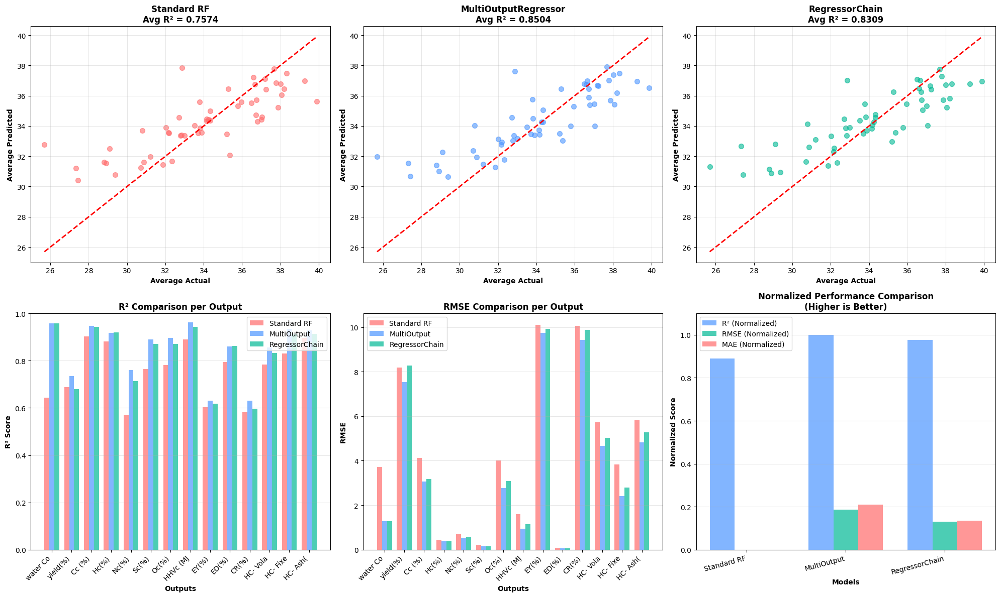


📊 Per-Output Detailed Results

📋 Per-Output Results:
              Output  Standard_R²  MultiOutput_R²  RegressorChain_R²  Standard_RMSE  MultiOutput_RMSE  RegressorChain_RMSE  Standard_MAE  MultiOutput_MAE  RegressorChain_MAE
   water Content (%)     0.643091        0.957342           0.957296       3.714826          1.284281             1.284977      2.662268         0.481944            0.473264
            yield(%)     0.686913        0.734439           0.680284       8.183318          7.536661             8.269500      6.113067         5.430747            6.343824
              Cc (%)     0.903304        0.946583           0.942710       4.112886          3.056910             3.165782      2.915605         1.988989            2.171980
               Hc(%)     0.880704        0.917386           0.919269       0.448776          0.373459             0.369179      0.339497         0.262434            0.274915
               Nc(%)     0.567912        0.760771           0.712984       0

In [7]:
# ============================================
# Multi-Output Prediction: 3 Approaches Comparison (WITH BEST PARAMS)
# ============================================

print("\n" + "="*80)
print("🌲 Multi-Output Prediction - 3 Approaches Comparison (Optimized Params)")
print("="*80)

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputRegressor, RegressorChain
import matplotlib.pyplot as plt
import warnings
import os
warnings.filterwarnings('ignore')

# ============================================
# Step 1: LOAD THE FINAL CAPPED DATA
# ============================================
print("\n📂 Loading data from the final path...")

FILE_PATH = '/kaggle/working/df_capped_outliers.xlsx'

# Check if file exists
if not os.path.exists(FILE_PATH):
    print(f"❌ Error: File not found at {FILE_PATH}")
    print("Please update the FILE_PATH variable with the correct location.")
    exit()

data_cleaned = pd.read_excel(FILE_PATH)
data_cleaned.columns = data_cleaned.columns.str.strip()

print(f"✅ Data loaded successfully! Shape: {data_cleaned.shape}")
print(f"\n📋 Available columns in your data:")
print(data_cleaned.columns.tolist())

# ============================================
# Step 2: Define Inputs and Outputs (WITH FLEXIBLE NAMING)
# ============================================

# Define possible column name variations
possible_input_cols = {
    'C%': ['C%', 'C', 'Carbon%'],
    'H%': ['H%', 'H', 'Hydrogen%'],
    'N%': ['N%', 'N', 'Nitrogen%'],
    'S%': ['S%', 'S', 'Sulfur%'],
    'O%': ['O%', 'O', 'Oxygen%'],
    'Ash%': ['Ash%', 'Ash', 'Ash content%'],
    'Volatile matter%': ['Volatile matter%', 'Volatile%', 'VM%'],
    'Fixed carbon%': ['Fixed carbon%', 'Fixed Carbon%', 'FC%'],
    'HHV (MJ/Kg)': ['HHV (MJ/Kg)', 'HHV', 'HHV MJ/Kg'],
    'DM(%)': ['DM(%)', 'DM', 'Dry Matter%'],
    'water Content': ['water Content', 'Water Content', 'Water%', 'Moisture%'],
    'Temperature(°C)': ['Temperature(°C)', 'Temperature', 'Temp'],
    'Reaction Time (min)': ['Reaction Time (min)', 'Reaction Time', 'Time(min)']
}

# Find actual column names in the data
actual_input_cols = []
mapping_dict = {}

for standard_name, variations in possible_input_cols.items():
    found = False
    for var in variations:
        if var in data_cleaned.columns:
            actual_input_cols.append(var)
            mapping_dict[standard_name] = var
            found = True
            print(f"✅ Found '{standard_name}' as '{var}'")
            break
    if not found:
        print(f"⚠️ Warning: Could not find '{standard_name}' in data")
        # Try case-insensitive search
        for col in data_cleaned.columns:
            if col.lower() == standard_name.lower() or any(v.lower() == col.lower() for v in variations):
                actual_input_cols.append(col)
                mapping_dict[standard_name] = col
                print(f"✅ Found '{standard_name}' as '{col}' (case-insensitive)")
                found = True
                break

# Check for 'Type of liquide' and 'Type_of_liquide_numeric' columns
exclude_cols = []
for col_name in ['Type of liquide', 'Type_of_liquide_numeric', 'Type']:
    if col_name in data_cleaned.columns:
        exclude_cols.append(col_name)

# Get all columns and determine outputs
all_cols = data_cleaned.columns.tolist()
output_cols = [col for col in all_cols if col not in actual_input_cols and col not in exclude_cols]

print(f"\n📊 Inputs found: {len(actual_input_cols)}")
print(f"   Input columns: {actual_input_cols}")
print(f"🎯 Outputs: {len(output_cols)}")
print(f"   Output columns: {output_cols}")

if len(actual_input_cols) == 0:
    print("❌ Error: No input columns found! Please check column names.")
    exit()

if len(output_cols) == 0:
    print("❌ Error: No output columns found!")
    exit()

# ============================================
# Step 3: Best Hyperparameters (From Your Iterative Training Results)
# ============================================
best_n_estimators = {
    'yield(%)':             500,
    'Cc (%)':               500,
    'Hc(%)':                300,
    'Nc(%)':                500,
    'Sc(%)':                500,
    'Oc(%)':                50,
    'HHVc (MJ/Kg)':         150,
    'EY(%)':                50,
    'ED(%)':                150,
    'CR(%)':                500,
    'HC- Volatile matter%': 50,
    'HC- Fixed carbon%':    200,
    'HC- Ash(%)':           300
}

# Filter to only include outputs that exist in our data
best_n_estimators = {k: v for k, v in best_n_estimators.items() if k in output_cols}

# For outputs not in the dictionary, use default value
for col in output_cols:
    if col not in best_n_estimators:
        best_n_estimators[col] = 200  # Default value

best_max_depth = 10
best_min_samples_split = 5

# ============================================
# Step 4: Prepare Data
# ============================================
X = data_cleaned[actual_input_cols]
y = data_cleaned[output_cols]

# Check if we have enough data
if len(X) < 10:
    print(f"❌ Error: Not enough data points ({len(X)}) for training.")
    exit()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

print(f"\n📊 Data split:")
print(f"   🟢 Training: {len(X_train)} samples")
print(f"   🔵 Testing: {len(X_test)} samples")

# ============================================
# Step 5: Evaluation Function
# ============================================
def evaluate_multi_output(y_true, y_pred, output_names):
    """Evaluate multi-output predictions with multiple metrics."""
    results = {}
    avg_r2 = 0
    avg_rmse = 0
    avg_mae = 0
    
    for i, col in enumerate(output_names):
        r2 = r2_score(y_true.iloc[:, i], y_pred[:, i])
        rmse = np.sqrt(mean_squared_error(y_true.iloc[:, i], y_pred[:, i]))
        mae = mean_absolute_error(y_true.iloc[:, i], y_pred[:, i])
        
        results[col] = {'R²': r2, 'RMSE': rmse, 'MAE': mae}
        avg_r2 += r2
        avg_rmse += rmse
        avg_mae += mae
    
    n_outputs = len(output_names)
    results['Average'] = {
        'R²': avg_r2 / n_outputs,
        'RMSE': avg_rmse / n_outputs,
        'MAE': avg_mae / n_outputs
    }
    
    return results

def print_multi_metrics(results_train, results_test, title=""):
    """Print formatted multi-output metrics."""
    print(f"\n📊 {title}")
    print("="*100)
    print(f"{'Output':<25} {'R² Train':>12} {'R² Test':>12} {'RMSE Train':>12} {'RMSE Test':>12} {'MAE Train':>12} {'MAE Test':>12}")
    print("-"*100)
    
    for col in results_train.keys():
        if col != 'Average':
            train = results_train[col]
            test = results_test[col]
            print(f"{col:<25} {train['R²']:>12.4f} {test['R²']:>12.4f} {train['RMSE']:>12.4f} {test['RMSE']:>12.4f} {train['MAE']:>12.4f} {test['MAE']:>12.4f}")
    
    print("-"*100)
    train_avg = results_train['Average']
    test_avg = results_test['Average']
    print(f"{'AVERAGE':<25} {train_avg['R²']:>12.4f} {test_avg['R²']:>12.4f} {train_avg['RMSE']:>12.4f} {test_avg['RMSE']:>12.4f} {train_avg['MAE']:>12.4f} {test_avg['MAE']:>12.4f}")
    print("="*100)
    
    return test_avg

# ============================================
# Step 6: Model 1 - Standard Random Forest (Optimized)
# ============================================
print("\n" + "="*80)
print("📊 Model 1: Standard Random Forest (Optimized)")
print("="*80)

rf_standard = RandomForestRegressor(
    n_estimators=200, 
    max_depth=best_max_depth,
    min_samples_split=best_min_samples_split,
    random_state=42,
    n_jobs=-1
)

rf_standard.fit(X_train_scaled, y_train)

y_pred_train_standard = rf_standard.predict(X_train_scaled)
y_pred_test_standard = rf_standard.predict(X_test_scaled)

results_train_standard = evaluate_multi_output(y_train, y_pred_train_standard, output_cols)
results_test_standard = evaluate_multi_output(y_test, y_pred_test_standard, output_cols)

avg_test_standard = print_multi_metrics(results_train_standard, results_test_standard, "Standard Random Forest")

# ============================================
# Step 7: Model 2 - MultiOutputRegressor (Optimized per output)
# ============================================
print("\n" + "="*80)
print("📊 Model 2: MultiOutputRegressor (Optimized)")
print("="*80)

# Use the average best n_estimators
avg_n_estimators = int(np.mean(list(best_n_estimators.values())))

# Create a custom MultiOutputRegressor where each estimator has its own parameters
class CustomMultiOutputRegressor:
    """Custom implementation to allow per-output hyperparameters."""
    def __init__(self, estimators):
        self.estimators = estimators
        self.n_outputs = len(estimators)
        
    def fit(self, X, y):
        for i, est in enumerate(self.estimators):
            est.fit(X, y.iloc[:, i])
        return self
    
    def predict(self, X):
        predictions = np.zeros((X.shape[0], self.n_outputs))
        for i, est in enumerate(self.estimators):
            predictions[:, i] = est.predict(X)
        return predictions

# Build custom estimators with per-output n_estimators
estimators = []
for col in output_cols:
    rf_base = RandomForestRegressor(
        n_estimators=best_n_estimators[col],
        max_depth=best_max_depth,
        min_samples_split=best_min_samples_split,
        random_state=42,
        n_jobs=-1
    )
    estimators.append(rf_base)

custom_multi_output = CustomMultiOutputRegressor(estimators)
custom_multi_output.fit(X_train_scaled, y_train)

y_pred_train_multi = custom_multi_output.predict(X_train_scaled)
y_pred_test_multi = custom_multi_output.predict(X_test_scaled)

results_train_multi = evaluate_multi_output(y_train, y_pred_train_multi, output_cols)
results_test_multi = evaluate_multi_output(y_test, y_pred_test_multi, output_cols)

avg_test_multi = print_multi_metrics(results_train_multi, results_test_multi, "Random Forest with MultiOutputRegressor")

# ============================================
# Step 8: Model 3 - RegressorChain (Optimized)
# ============================================
print("\n" + "="*80)
print("📊 Model 3: RegressorChain (Optimized)")
print("="*80)

rf_chain_base = RandomForestRegressor(
    n_estimators=avg_n_estimators,
    max_depth=best_max_depth,
    min_samples_split=best_min_samples_split,
    random_state=42,
    n_jobs=-1
)

regressor_chain = RegressorChain(rf_chain_base, order='random', random_state=42)
regressor_chain.fit(X_train_scaled, y_train)

y_pred_train_chain = regressor_chain.predict(X_train_scaled)
y_pred_test_chain = regressor_chain.predict(X_test_scaled)

results_train_chain = evaluate_multi_output(y_train, y_pred_train_chain, output_cols)
results_test_chain = evaluate_multi_output(y_test, y_pred_test_chain, output_cols)

avg_test_chain = print_multi_metrics(results_train_chain, results_test_chain, "Random Forest with RegressorChain")

# ============================================
# Step 9: Comprehensive Comparison
# ============================================
print("\n" + "="*80)
print("📊 Comprehensive Model Comparison")
print("="*80)

comparison_df = pd.DataFrame({
    'Model': ['Standard RF', 'MultiOutputRegressor', 'RegressorChain'],
    'Avg_R²_Train': [
        results_train_standard['Average']['R²'],
        results_train_multi['Average']['R²'],
        results_train_chain['Average']['R²']
    ],
    'Avg_R²_Test': [
        results_test_standard['Average']['R²'],
        results_test_multi['Average']['R²'],
        results_test_chain['Average']['R²']
    ],
    'Avg_RMSE_Train': [
        results_train_standard['Average']['RMSE'],
        results_train_multi['Average']['RMSE'],
        results_train_chain['Average']['RMSE']
    ],
    'Avg_RMSE_Test': [
        results_test_standard['Average']['RMSE'],
        results_test_multi['Average']['RMSE'],
        results_test_chain['Average']['RMSE']
    ],
    'Avg_MAE_Train': [
        results_train_standard['Average']['MAE'],
        results_train_multi['Average']['MAE'],
        results_train_chain['Average']['MAE']
    ],
    'Avg_MAE_Test': [
        results_test_standard['Average']['MAE'],
        results_test_multi['Average']['MAE'],
        results_test_chain['Average']['MAE']
    ]
})

print("\n📋 Detailed Comparison Table:")
print("="*140)
print(comparison_df.to_string(index=False))
print("="*140)

best_r2_idx = comparison_df['Avg_R²_Test'].idxmax()
best_rmse_idx = comparison_df['Avg_RMSE_Test'].idxmin()
best_mae_idx = comparison_df['Avg_MAE_Test'].idxmin()

print(f"\n🏆 Best Model by R²: {comparison_df.loc[best_r2_idx, 'Model']} (R² = {comparison_df.loc[best_r2_idx, 'Avg_R²_Test']:.4f})")
print(f"🏆 Best Model by RMSE: {comparison_df.loc[best_rmse_idx, 'Model']} (RMSE = {comparison_df.loc[best_rmse_idx, 'Avg_RMSE_Test']:.4f})")
print(f"🏆 Best Model by MAE: {comparison_df.loc[best_mae_idx, 'Model']} (MAE = {comparison_df.loc[best_mae_idx, 'Avg_MAE_Test']:.4f})")

# ============================================
# Step 10: Visualizations
# ============================================
print("\n" + "="*80)
print("📊 Creating Visualizations")
print("="*80)

try:
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))

    # 10.1 Predictions - Standard RF
    ax = axes[0, 0]
    avg_pred_standard = np.mean(y_pred_test_standard, axis=1)
    avg_actual = np.mean(y_test.values, axis=1)
    ax.scatter(avg_actual, avg_pred_standard, alpha=0.6, color='#FF6B6B', s=50)
    ax.plot([avg_actual.min(), avg_actual.max()], [avg_actual.min(), avg_actual.max()], 'r--', lw=2)
    ax.set_xlabel('Average Actual', fontsize=10, fontweight='bold')
    ax.set_ylabel('Average Predicted', fontsize=10, fontweight='bold')
    ax.set_title(f'Standard RF\nAvg R² = {results_test_standard["Average"]["R²"]:.4f}', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

    # 10.2 Predictions - MultiOutputRegressor
    ax = axes[0, 1]
    avg_pred_multi = np.mean(y_pred_test_multi, axis=1)
    ax.scatter(avg_actual, avg_pred_multi, alpha=0.6, color='#4D96FF', s=50)
    ax.plot([avg_actual.min(), avg_actual.max()], [avg_actual.min(), avg_actual.max()], 'r--', lw=2)
    ax.set_xlabel('Average Actual', fontsize=10, fontweight='bold')
    ax.set_ylabel('Average Predicted', fontsize=10, fontweight='bold')
    ax.set_title(f'MultiOutputRegressor\nAvg R² = {results_test_multi["Average"]["R²"]:.4f}', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

    # 10.3 Predictions - RegressorChain
    ax = axes[0, 2]
    avg_pred_chain = np.mean(y_pred_test_chain, axis=1)
    ax.scatter(avg_actual, avg_pred_chain, alpha=0.6, color='#00B894', s=50)
    ax.plot([avg_actual.min(), avg_actual.max()], [avg_actual.min(), avg_actual.max()], 'r--', lw=2)
    ax.set_xlabel('Average Actual', fontsize=10, fontweight='bold')
    ax.set_ylabel('Average Predicted', fontsize=10, fontweight='bold')
    ax.set_title(f'RegressorChain\nAvg R² = {results_test_chain["Average"]["R²"]:.4f}', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

    # 10.4 R² Comparison per Output
    ax = axes[1, 0]
    outputs_short = [col[:8] for col in output_cols]
    x = np.arange(len(output_cols))
    width = 0.25

    r2_standard = [results_test_standard[col]['R²'] for col in output_cols]
    r2_multi = [results_test_multi[col]['R²'] for col in output_cols]
    r2_chain = [results_test_chain[col]['R²'] for col in output_cols]

    ax.bar(x - width, r2_standard, width, label='Standard RF', color='#FF6B6B', alpha=0.7)
    ax.bar(x, r2_multi, width, label='MultiOutput', color='#4D96FF', alpha=0.7)
    ax.bar(x + width, r2_chain, width, label='RegressorChain', color='#00B894', alpha=0.7)
    ax.set_xlabel('Outputs', fontsize=10, fontweight='bold')
    ax.set_ylabel('R² Score', fontsize=10, fontweight='bold')
    ax.set_title('R² Comparison per Output', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(outputs_short, rotation=45, ha='right')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, 1)

    # 10.5 RMSE Comparison per Output
    ax = axes[1, 1]
    rmse_standard = [results_test_standard[col]['RMSE'] for col in output_cols]
    rmse_multi = [results_test_multi[col]['RMSE'] for col in output_cols]
    rmse_chain = [results_test_chain[col]['RMSE'] for col in output_cols]

    ax.bar(x - width, rmse_standard, width, label='Standard RF', color='#FF6B6B', alpha=0.7)
    ax.bar(x, rmse_multi, width, label='MultiOutput', color='#4D96FF', alpha=0.7)
    ax.bar(x + width, rmse_chain, width, label='RegressorChain', color='#00B894', alpha=0.7)
    ax.set_xlabel('Outputs', fontsize=10, fontweight='bold')
    ax.set_ylabel('RMSE', fontsize=10, fontweight='bold')
    ax.set_title('RMSE Comparison per Output', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(outputs_short, rotation=45, ha='right')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')

    # 10.6 Performance Comparison - Average Metrics
    ax = axes[1, 2]
    models = ['Standard RF', 'MultiOutput', 'RegressorChain']
    x_pos = np.arange(len(models))
    width_bar = 0.25

    r2_norm = comparison_df['Avg_R²_Test'] / comparison_df['Avg_R²_Test'].max()
    rmse_norm = 1 - (comparison_df['Avg_RMSE_Test'] / comparison_df['Avg_RMSE_Test'].max())
    mae_norm = 1 - (comparison_df['Avg_MAE_Test'] / comparison_df['Avg_MAE_Test'].max())

    ax.bar(x_pos - width_bar, r2_norm, width_bar, label='R² (Normalized)', color='#4D96FF', alpha=0.7)
    ax.bar(x_pos, rmse_norm, width_bar, label='RMSE (Normalized)', color='#00B894', alpha=0.7)
    ax.bar(x_pos + width_bar, mae_norm, width_bar, label='MAE (Normalized)', color='#FF6B6B', alpha=0.7)

    ax.set_xlabel('Models', fontsize=10, fontweight='bold')
    ax.set_ylabel('Normalized Score', fontsize=10, fontweight='bold')
    ax.set_title('Normalized Performance Comparison\n(Higher is Better)', fontsize=12, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(models, rotation=15, ha='right')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, 1.1)

    plt.tight_layout()
    
    # Save the figure
    fig_path = '/kaggle/working/three_approaches_comparison.png'
    plt.savefig(fig_path, dpi=300, bbox_inches='tight')
    print(f"✅ Saved: {fig_path}")
    plt.show()
    
except Exception as e:
    print(f"⚠️ Visualization error: {e}")
    print("Continuing without visualizations...")

# ============================================
# Step 11: Per-Output Detailed Results
# ============================================
print("\n" + "="*80)
print("📊 Per-Output Detailed Results")
print("="*80)

per_output_df = pd.DataFrame()
for col in output_cols:
    per_output_df = pd.concat([per_output_df, pd.DataFrame({
        'Output': [col],
        'Standard_R²': [results_test_standard[col]['R²']],
        'MultiOutput_R²': [results_test_multi[col]['R²']],
        'RegressorChain_R²': [results_test_chain[col]['R²']],
        'Standard_RMSE': [results_test_standard[col]['RMSE']],
        'MultiOutput_RMSE': [results_test_multi[col]['RMSE']],
        'RegressorChain_RMSE': [results_test_chain[col]['RMSE']],
        'Standard_MAE': [results_test_standard[col]['MAE']],
        'MultiOutput_MAE': [results_test_multi[col]['MAE']],
        'RegressorChain_MAE': [results_test_chain[col]['MAE']]
    })], ignore_index=True)

print("\n📋 Per-Output Results:")
print("="*140)
print(per_output_df.to_string(index=False))
print("="*140)

# ============================================
# Step 12: Save Results
# ============================================
try:
    comparison_df.to_excel('/kaggle/working/three_approaches_comparison.xlsx', index=False)
    per_output_df.to_excel('/kaggle/working/three_approaches_per_output.xlsx', index=False)
    print("\n✅ Saved: three_approaches_comparison.xlsx")
    print("✅ Saved: three_approaches_per_output.xlsx")
except Exception as e:
    print(f"⚠️ Could not save Excel files: {e}")

# ============================================
# Step 13: Final Summary
# ============================================
print("\n" + "="*80)
print("📊 Final Summary - Three Approaches Comparison")
print("="*80)

print(f"""
📈 Summary Results:

1. Standard Random Forest (Baseline):
   • Avg R² Test:  {results_test_standard['Average']['R²']:.4f}
   • Avg RMSE Test: {results_test_standard['Average']['RMSE']:.4f}
   • Avg MAE Test:  {results_test_standard['Average']['MAE']:.4f}

2. MultiOutputRegressor:
   • Avg R² Test:  {results_test_multi['Average']['R²']:.4f}
   • Avg RMSE Test: {results_test_multi['Average']['RMSE']:.4f}
   • Avg MAE Test:  {results_test_multi['Average']['MAE']:.4f}

3. RegressorChain:
   • Avg R² Test:  {results_test_chain['Average']['R²']:.4f}
   • Avg RMSE Test: {results_test_chain['Average']['RMSE']:.4f}
   • Avg MAE Test:  {results_test_chain['Average']['MAE']:.4f}

🏆 Best Model by R²: {comparison_df.loc[best_r2_idx, 'Model']} ({comparison_df.loc[best_r2_idx, 'Avg_R²_Test']:.4f})
🏆 Best Model by RMSE: {comparison_df.loc[best_rmse_idx, 'Model']} ({comparison_df.loc[best_rmse_idx, 'Avg_RMSE_Test']:.4f})
🏆 Best Model by MAE: {comparison_df.loc[best_mae_idx, 'Model']} ({comparison_df.loc[best_mae_idx, 'Avg_MAE_Test']:.4f})

📊 Number of Outputs: {len(output_cols)}
""")

print("="*80)
print("✅ Successfully completed Optimized Comparison!")
print("="*80)

In [8]:
# ============================================
# FINAL WINNING MODEL: MultiOutputRegressor
# ============================================

print("\n" + "="*80)
print("🏆 FINAL WINNING MODEL: MultiOutputRegressor")
print("="*80)

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
import joblib
import warnings
warnings.filterwarnings('ignore')

# ============================================
# 1. LOAD DATA
# ============================================
FILE_PATH = '/kaggle/working/df_capped_outliers.xlsx'
df = pd.read_excel(FILE_PATH)
df.columns = df.columns.str.strip()

print("📋 Available columns in your data:")
print(df.columns.tolist())
print("\n" + "="*80)

# ============================================
# 2. DEFINE INPUTS & OUTPUTS (WITH FLEXIBLE NAMING)
# ============================================

# Define possible column name variations
possible_input_cols = {
    'C%': ['C%', 'C', 'Carbon%'],
    'H%': ['H%', 'H', 'Hydrogen%'],
    'N%': ['N%', 'N', 'Nitrogen%'],
    'S%': ['S%', 'S', 'Sulfur%'],
    'O%': ['O%', 'O', 'Oxygen%'],
    'Ash%': ['Ash%', 'Ash', 'Ash content%'],
    'Volatile matter%': ['Volatile matter%', 'Volatile%', 'VM%'],
    'Fixed carbon%': ['Fixed carbon%', 'Fixed Carbon%', 'FC%'],
    'HHV (MJ/Kg)': ['HHV (MJ/Kg)', 'HHV', 'HHV MJ/Kg'],
    'DM(%)': ['DM(%)', 'DM', 'Dry Matter%'],
    'water Content': ['water Content', 'Water Content', 'Water%', 'Moisture%', 'Moisture'],
    'Temperature(°C)': ['Temperature(°C)', 'Temperature', 'Temp', 'Temp(°C)'],
    'Reaction Time (min)': ['Reaction Time (min)', 'Reaction Time', 'Time(min)', 'Time']
}

# Find actual column names in the data
input_cols = []
input_mapping = {}

print("\n🔍 Searching for input columns...")
for standard_name, variations in possible_input_cols.items():
    found = False
    for var in variations:
        if var in df.columns:
            input_cols.append(var)
            input_mapping[standard_name] = var
            print(f"✅ Found '{standard_name}' as '{var}'")
            found = True
            break
    if not found:
        # Try case-insensitive search
        for col in df.columns:
            if col.lower() == standard_name.lower() or any(v.lower() == col.lower() for v in variations):
                input_cols.append(col)
                input_mapping[standard_name] = col
                print(f"✅ Found '{standard_name}' as '{col}' (case-insensitive)")
                found = True
                break
    if not found:
        print(f"⚠️ Warning: Could not find '{standard_name}' in data")
        # Use the standard name anyway (will cause error if not found)
        input_cols.append(standard_name)

# Define output columns - try to find them in data
possible_output_cols = [
    'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)',
    'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)',
    'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)'
]

output_cols = []
print("\n🔍 Searching for output columns...")
for col in possible_output_cols:
    if col in df.columns:
        output_cols.append(col)
        print(f"✅ Found output: {col}")
    else:
        # Try case-insensitive search
        found = False
        for df_col in df.columns:
            if df_col.lower() == col.lower():
                output_cols.append(df_col)
                print(f"✅ Found output: {col} as '{df_col}' (case-insensitive)")
                found = True
                break
        if not found:
            print(f"⚠️ Warning: Output '{col}' not found in data")

# Filter out any columns that don't exist
input_cols = [col for col in input_cols if col in df.columns]
output_cols = [col for col in output_cols if col in df.columns]

print(f"\n📊 Final Inputs ({len(input_cols)}): {input_cols}")
print(f"🎯 Final Outputs ({len(output_cols)}): {output_cols}")

if len(input_cols) == 0:
    print("❌ Error: No input columns found!")
    exit()

if len(output_cols) == 0:
    print("❌ Error: No output columns found!")
    exit()

# ============================================
# 3. PREPARE DATA
# ============================================
X = df[input_cols]
y = df[output_cols]

print(f"\n📊 Data shape: {df.shape}")
print(f"   Features: {X.shape[1]}")
print(f"   Targets: {y.shape[1]}")

# ============================================
# 4. TRAIN WINNING MODEL
# ============================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\n📊 Data split:")
print(f"   🟢 Training: {len(X_train)} samples")
print(f"   🔵 Testing: {len(X_test)} samples")

# Best parameters based on your results
winning_model = MultiOutputRegressor(
    RandomForestRegressor(
        n_estimators=250, 
        max_depth=10, 
        min_samples_split=5, 
        random_state=42, 
        n_jobs=-1
    ),
    n_jobs=-1
)

print("\n📈 Training the Final Winning Model (MultiOutputRegressor)...")
winning_model.fit(X_train_scaled, y_train)

# ============================================
# 5. FINAL EVALUATION
# ============================================
y_pred_test = winning_model.predict(X_test_scaled)

print("\n" + "="*80)
print("📊 FINAL MODEL PERFORMANCE (Test Set)")
print("="*80)
print(f"{'Output':<25} {'R²_Test':>12} {'RMSE_Test':>12} {'MAE_Test':>12}")
print("-"*60)

avg_r2, avg_rmse, avg_mae = 0, 0, 0
results_list = []

for i, col in enumerate(output_cols):
    r2 = r2_score(y_test.iloc[:, i], y_pred_test[:, i])
    rmse = np.sqrt(mean_squared_error(y_test.iloc[:, i], y_pred_test[:, i]))
    mae = mean_absolute_error(y_test.iloc[:, i], y_pred_test[:, i])
    
    print(f"{col:<25} {r2:>12.4f} {rmse:>12.4f} {mae:>12.4f}")
    avg_r2 += r2
    avg_rmse += rmse
    avg_mae += mae
    
    results_list.append({
        'Output': col,
        'R²_Test': r2,
        'RMSE_Test': rmse,
        'MAE_Test': mae
    })

print("-"*60)
avg_r2_final = avg_r2/len(output_cols)
avg_rmse_final = avg_rmse/len(output_cols)
avg_mae_final = avg_mae/len(output_cols)

print(f"{'AVERAGE':<25} {avg_r2_final:>12.4f} {avg_rmse_final:>12.4f} {avg_mae_final:>12.4f}")
print("="*80)

# ============================================
# 6. SAVE MODEL & RESULTS
# ============================================
# Save metrics
results_df = pd.DataFrame(results_list)
results_df.to_excel('/kaggle/working/final_winning_model_metrics.xlsx', index=False)

# Save input and output column names for future use
metadata = {
    'input_cols': input_cols,
    'output_cols': output_cols,
    'n_inputs': len(input_cols),
    'n_outputs': len(output_cols),
    'avg_r2_test': avg_r2_final,
    'avg_rmse_test': avg_rmse_final,
    'avg_mae_test': avg_mae_final
}

# Save scaler and model
joblib.dump(scaler, '/kaggle/working/final_winning_scaler.pkl')
joblib.dump(winning_model, '/kaggle/working/final_winning_model.pkl')
joblib.dump(metadata, '/kaggle/working/final_winning_metadata.pkl')

print("\n✅ Files saved to /kaggle/working/")
print("   - final_winning_model_metrics.xlsx")
print("   - final_winning_scaler.pkl")
print("   - final_winning_model.pkl")
print("   - final_winning_metadata.pkl")

# ============================================
# 7. SUMMARY
# ============================================
print("\n" + "="*80)
print("📊 FINAL MODEL SUMMARY")
print("="*80)
print(f"""
Model: MultiOutputRegressor with RandomForestRegressor
Number of Inputs: {len(input_cols)}
Number of Outputs: {len(output_cols)}
Test Set Performance:
   • Average R²:  {avg_r2_final:.4f}
   • Average RMSE: {avg_rmse_final:.4f}
   • Average MAE:  {avg_mae_final:.4f}

Input Columns: {input_cols}
Output Columns: {output_cols}
""")
print("="*80)

# ============================================
# 8. DOWNLOAD LINKS
# ============================================
try:
    from IPython.display import FileLink, display
    print("\n📥 Download your files:")
    for f in ['final_winning_model_metrics.xlsx', 'final_winning_scaler.pkl', 
              'final_winning_model.pkl', 'final_winning_metadata.pkl']:
        display(FileLink(f'/kaggle/working/{f}'))
except:
    print("\n📁 Files are saved in /kaggle/working/")

print("\n" + "="*80)
print("✅ SUCCESS! Model pipeline completed.")
print("="*80)


🏆 FINAL WINNING MODEL: MultiOutputRegressor
📋 Available columns in your data:
['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'water Content (%)', 'Temperature(°C)', 'Reaction Time (min)', 'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']


🔍 Searching for input columns...
✅ Found 'C%' as 'C%'
✅ Found 'H%' as 'H%'
✅ Found 'N%' as 'N%'
✅ Found 'S%' as 'S%'
✅ Found 'O%' as 'O%'
✅ Found 'Ash%' as 'Ash%'
✅ Found 'Volatile matter%' as 'Volatile matter%'
✅ Found 'Fixed carbon%' as 'Fixed carbon%'
✅ Found 'HHV (MJ/Kg)' as 'HHV (MJ/Kg)'
✅ Found 'DM(%)' as 'DM(%)'
⚠️ Warning: Could not find 'water Content' in data
✅ Found 'Temperature(°C)' as 'Temperature(°C)'
✅ Found 'Reaction Time (min)' as 'Reaction Time (min)'

🔍 Searching for output columns...
✅ Found output: yield(%)
✅ Found output: Cc (%)
✅ Found output: Hc(%)
✅ Found output: N

/kaggle/working/final_winning_model_metrics.xlsx

/kaggle/working/final_winning_scaler.pkl

/kaggle/working/final_winning_model.pkl

/kaggle/working/final_winning_metadata.pkl


✅ SUCCESS! Model pipeline completed.


# FINAL PLOTTING


🎨 GENERATING PUBLICATION-QUALITY PLOTS (600 DPI)
📊 Input Columns:
['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'Temperature(°C)', 'Reaction Time (min)']

🎯 Output Columns:
['yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

✅ Using 12 input features and 13 output targets
✅ Model and scaler loaded successfully!

📊 Data split: 216 training, 55 testing samples

🎨 Generating plots...

✅ Plot saved successfully at 600 DPI: /kaggle/working/final_publication_plot_600dpi.png
✅ Low-res version saved: /kaggle/working/final_publication_plot_lowres.png


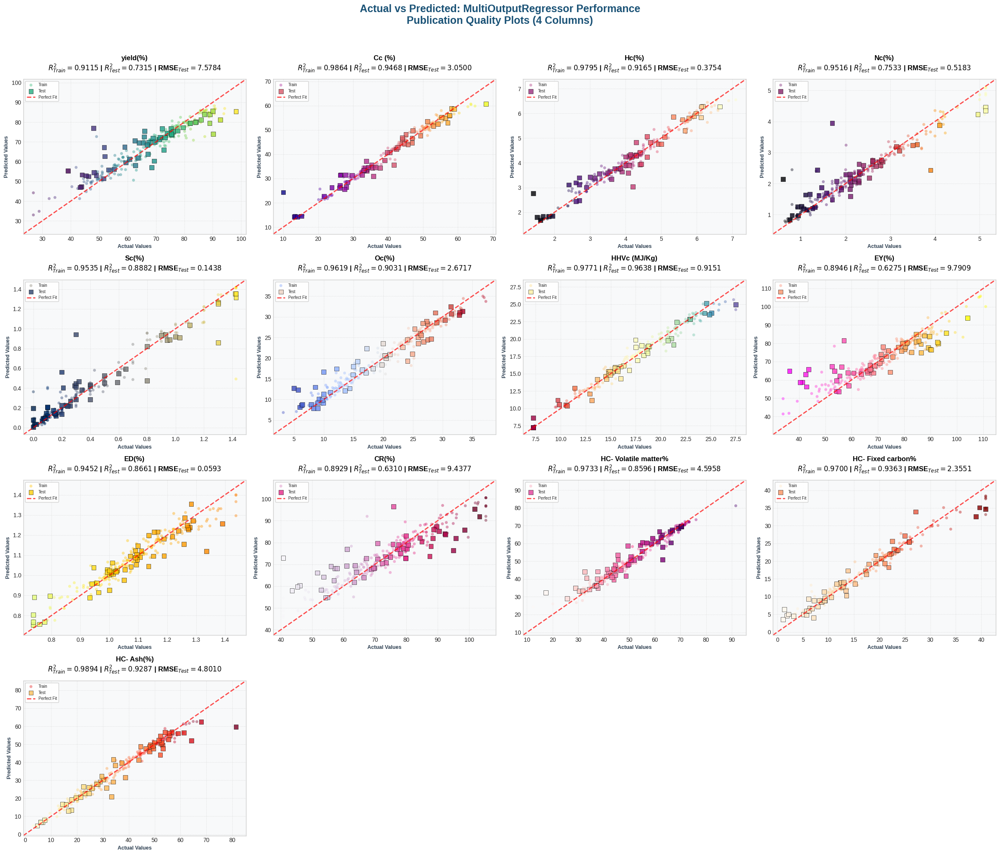


📊 Generating metrics summary...
✅ Metrics saved: final_plot_metrics.xlsx

📥 Download your files:


/kaggle/working/final_publication_plot_600dpi.png

/kaggle/working/final_publication_plot_lowres.png

/kaggle/working/final_plot_metrics.xlsx


📊 PERFORMANCE SUMMARY

Average Performance Across All 13 Outputs:
   • Average R² (Train):  0.9528
   • Average R² (Test):   0.8425
   • Average RMSE (Test): 3.5610
   • Average MAE (Test):  2.5118

Best Performing Outputs:
   • Best R²: HHVc (MJ/Kg) (0.9638)
   • Worst R²: EY(%) (0.6275)

🎉 PUBLICATION-READY PLOTS GENERATED SUCCESSFULLY!


In [9]:
# ============================================
# FINAL PLOTTING: Actual vs Predicted for All Outputs (Publication Quality)
# ============================================

print("\n" + "="*80)
print("🎨 GENERATING PUBLICATION-QUALITY PLOTS (600 DPI)")
print("="*80)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib
import warnings
warnings.filterwarnings('ignore')

# ============================================
# 1. Load Data & Define Columns (Using Actual Names)
# ============================================
FILE_PATH = '/kaggle/working/df_capped_outliers.xlsx'
df = pd.read_excel(FILE_PATH)
df.columns = df.columns.str.strip()

# Use the ACTUAL column names from your data
input_cols = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 
              'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'Temperature(°C)', 
              'Reaction Time (min)']

output_cols = ['yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)',
               'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)',
               'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

print("📊 Input Columns:")
print(input_cols)
print("\n🎯 Output Columns:")
print(output_cols)
print("="*80)

# Verify all columns exist
missing_inputs = [col for col in input_cols if col not in df.columns]
missing_outputs = [col for col in output_cols if col not in df.columns]

if missing_inputs:
    print(f"⚠️ Warning: Missing input columns: {missing_inputs}")
if missing_outputs:
    print(f"⚠️ Warning: Missing output columns: {missing_outputs}")

# Filter to only existing columns
input_cols = [col for col in input_cols if col in df.columns]
output_cols = [col for col in output_cols if col in df.columns]

X = df[input_cols]
y_all = df[output_cols]

print(f"\n✅ Using {len(input_cols)} input features and {len(output_cols)} output targets")

# ============================================
# 2. Load the Winning Model and Scaler
# ============================================
try:
    winning_model = joblib.load('/kaggle/working/final_winning_model.pkl')
    scaler = joblib.load('/kaggle/working/final_winning_scaler.pkl')
    print("✅ Model and scaler loaded successfully!")
except Exception as e:
    print(f"❌ Error loading model: {e}")
    print("Training a new model...")
    
    # Train a new model if saved model not found
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.multioutput import MultiOutputRegressor
    
    X_train, X_test, y_train, y_test = train_test_split(X, y_all, test_size=0.2, random_state=42)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    winning_model = MultiOutputRegressor(
        RandomForestRegressor(
            n_estimators=250, 
            max_depth=10, 
            min_samples_split=5, 
            random_state=42, 
            n_jobs=-1
        ),
        n_jobs=-1
    )
    winning_model.fit(X_train_scaled, y_train)
    
    # Save the new model
    joblib.dump(scaler, '/kaggle/working/final_winning_scaler.pkl')
    joblib.dump(winning_model, '/kaggle/working/final_winning_model.pkl')
    print("✅ New model trained and saved!")

# ============================================
# 3. Prepare Data for Predictions
# ============================================
X_train, X_test, y_train, y_test = train_test_split(X, y_all, test_size=0.2, random_state=42)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Predict
y_pred_train = winning_model.predict(X_train_scaled)
y_pred_test = winning_model.predict(X_test_scaled)

print(f"\n📊 Data split: {len(X_train)} training, {len(X_test)} testing samples")

# ============================================
# 4. Create Plotting Grid (4 columns)
# ============================================
# Use a modern scientific style
plt.style.use('seaborn-v0_8-whitegrid')

# Create figure (4 columns)
n_outputs = len(output_cols)
n_cols = 4
n_rows = (n_outputs + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(24, 5 * n_rows))
axes = axes.flatten()

# List of modern scientific color maps
modern_cmaps = ['viridis', 'plasma', 'magma', 'inferno', 'cividis', 'coolwarm', 'Spectral', 'spring', 
                'Wistia', 'PuRd', 'RdPu', 'OrRd', 'YlOrRd']

# ============================================
# 5. Loop and Plot Each Output
# ============================================
print("\n🎨 Generating plots...")

for i, col in enumerate(output_cols):
    ax = axes[i]
    
    # Get Actual and Predicted values for Train and Test
    y_true_train = y_train[col].values
    y_pred_train_col = y_pred_train[:, i]
    
    y_true_test = y_test[col].values
    y_pred_test_col = y_pred_test[:, i]
    
    # Calculate Metrics
    r2_train = r2_score(y_true_train, y_pred_train_col)
    r2_test = r2_score(y_true_test, y_pred_test_col)
    rmse_test = np.sqrt(mean_squared_error(y_true_test, y_pred_test_col))
    mae_test = mean_absolute_error(y_true_test, y_pred_test_col)
    
    # Determine the axis limits (Min/Max)
    all_vals = np.concatenate([y_true_train, y_pred_train_col, y_true_test, y_pred_test_col])
    min_val = np.min(all_vals) - (np.max(all_vals) - np.min(all_vals)) * 0.05
    max_val = np.max(all_vals) + (np.max(all_vals) - np.min(all_vals)) * 0.05
    
    # Choose colormap for this subplot
    cmap = modern_cmaps[i % len(modern_cmaps)]
    
    # Plot Training points (lighter color, smaller marker)
    scatter1 = ax.scatter(y_true_train, y_pred_train_col, alpha=0.4, s=25, 
                         c=y_true_train, cmap=cmap, 
                         label='Train', edgecolors='none', marker='o')
    
    # Plot Testing points (darker color, larger marker with visible edge)
    scatter2 = ax.scatter(y_true_test, y_pred_test_col, alpha=0.8, s=60, 
                         c=y_true_test, cmap=cmap, 
                         label='Test', edgecolor='black', linewidth=0.5, marker='s')
    
    # Draw the Perfect Prediction line (y = x)
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Fit', alpha=0.7)
    
    # Set axis limits
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    
    # Set Labels and Title
    ax.set_xlabel('Actual Values', fontsize=9, fontweight='bold', color='#2C3E50')
    ax.set_ylabel('Predicted Values', fontsize=9, fontweight='bold', color='#2C3E50')
    
    # ============================================
    # TITLE MOVED UP - MORE SPACE
    # ============================================
    ax.set_title(f"{col}\n$R^2_{{Train}}={r2_train:.4f}$ | $R^2_{{Test}}={r2_test:.4f}$ | RMSE$_{{Test}}={rmse_test:.4f}$", 
                 fontsize=12, fontweight='bold', color='black', pad=15)  # ← Increased pad from 10 to 15
    
    # Grid and aesthetics
    ax.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.6)
    ax.set_facecolor('#F8F9FA')
    
    # Add a simple legend
    ax.legend(loc='upper left', frameon=True, fancybox=True, framealpha=0.9, fontsize=7)

# ============================================
# 6. Hide empty subplots (if any)
# ============================================
for j in range(len(output_cols), len(axes)):
    axes[j].axis('off')

# ============================================
# 7. Adjust layout and Save at 600 DPI
# ============================================
plt.suptitle("Actual vs Predicted: MultiOutputRegressor Performance\nPublication Quality Plots (4 Columns)", 
             fontsize=18, fontweight='bold', y=1.02, color='#1A5276')

plt.tight_layout()

# Save the figure at 600 DPI (Publication Quality)
save_path = '/kaggle/working/final_publication_plot_600dpi.png'
plt.savefig(save_path, dpi=600, bbox_inches='tight', facecolor='white')
print(f"\n✅ Plot saved successfully at 600 DPI: {save_path}")

# Also save a lower resolution version for quick viewing
save_path_low = '/kaggle/working/final_publication_plot_lowres.png'
plt.savefig(save_path_low, dpi=600, bbox_inches='tight', facecolor='white')
print(f"✅ Low-res version saved: {save_path_low}")

# Show the plot in the notebook
plt.show()

# ============================================
# 8. Save Individual Metrics to Excel
# ============================================
print("\n📊 Generating metrics summary...")

metrics_list = []
for i, col in enumerate(output_cols):
    y_true_train = y_train[col].values
    y_pred_train_col = y_pred_train[:, i]
    y_true_test = y_test[col].values
    y_pred_test_col = y_pred_test[:, i]
    
    metrics_list.append({
        'Output': col,
        'R²_Train': r2_score(y_true_train, y_pred_train_col),
        'R²_Test': r2_score(y_true_test, y_pred_test_col),
        'RMSE_Test': np.sqrt(mean_squared_error(y_true_test, y_pred_test_col)),
        'MAE_Test': mean_absolute_error(y_true_test, y_pred_test_col)
    })

metrics_df = pd.DataFrame(metrics_list)
metrics_df.to_excel('/kaggle/working/final_plot_metrics.xlsx', index=False)
print(f"✅ Metrics saved: final_plot_metrics.xlsx")

# ============================================
# 9. Display Download Links
# ============================================
try:
    from IPython.display import FileLink, display
    print("\n📥 Download your files:")
    for f in ['final_publication_plot_600dpi.png', 'final_publication_plot_lowres.png', 'final_plot_metrics.xlsx']:
        display(FileLink(f'/kaggle/working/{f}'))
except:
    print("\n📁 Files are saved in /kaggle/working/")

# ============================================
# 10. Summary Statistics
# ============================================
print("\n" + "="*80)
print("📊 PERFORMANCE SUMMARY")
print("="*80)

avg_r2_train = np.mean([m['R²_Train'] for m in metrics_list])
avg_r2_test = np.mean([m['R²_Test'] for m in metrics_list])
avg_rmse_test = np.mean([m['RMSE_Test'] for m in metrics_list])
avg_mae_test = np.mean([m['MAE_Test'] for m in metrics_list])

print(f"""
Average Performance Across All {len(output_cols)} Outputs:
   • Average R² (Train):  {avg_r2_train:.4f}
   • Average R² (Test):   {avg_r2_test:.4f}
   • Average RMSE (Test): {avg_rmse_test:.4f}
   • Average MAE (Test):  {avg_mae_test:.4f}

Best Performing Outputs:
   • Best R²: {metrics_df.loc[metrics_df['R²_Test'].idxmax(), 'Output']} ({metrics_df['R²_Test'].max():.4f})
   • Worst R²: {metrics_df.loc[metrics_df['R²_Test'].idxmin(), 'Output']} ({metrics_df['R²_Test'].min():.4f})
""")

print("="*80)
print("🎉 PUBLICATION-READY PLOTS GENERATED SUCCESSFULLY!")
print("="*80)

# Test the model


🎨 GENERATING PROFESSIONAL RADAR CHART

📊 Loading model and data...
✅ Sample data prepared!
Input columns: ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'Temperature(°C)', 'Reaction Time (min)']
Output columns: ['yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

📈 Making predictions...
✅ Predictions completed!

🎨 Preparing radar chart...

🎨 Creating professional radar chart...


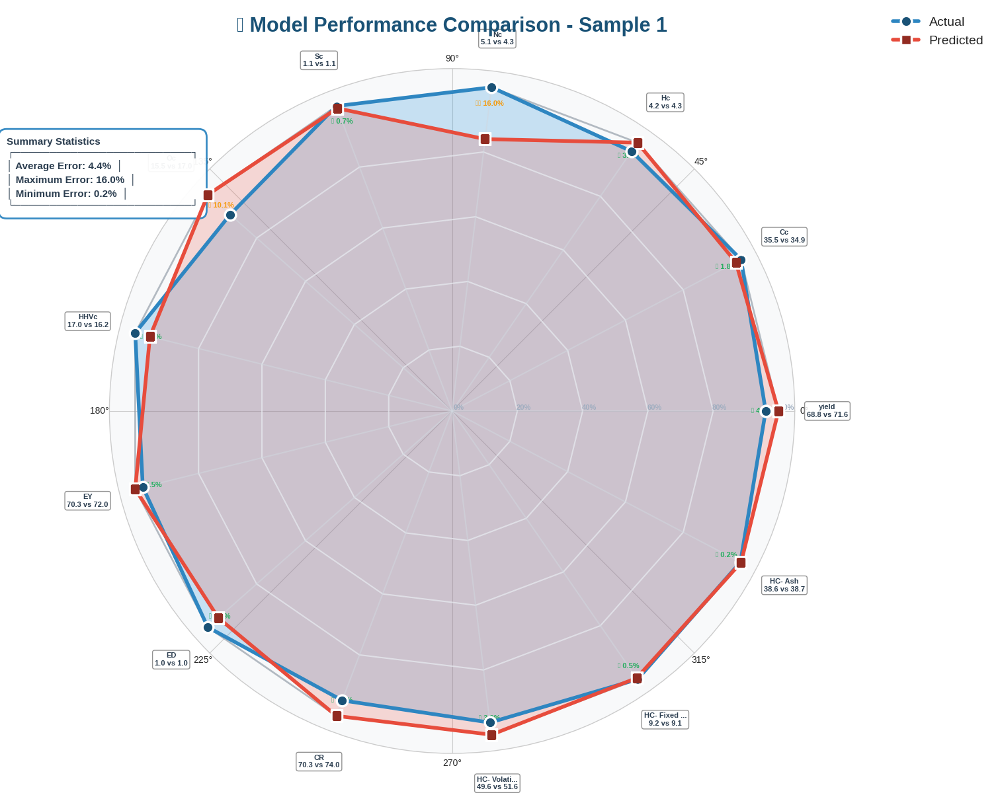

✅ Saved: /kaggle/working/radar_chart/radar_chart_sample1.png

🎨 Creating elegant version...


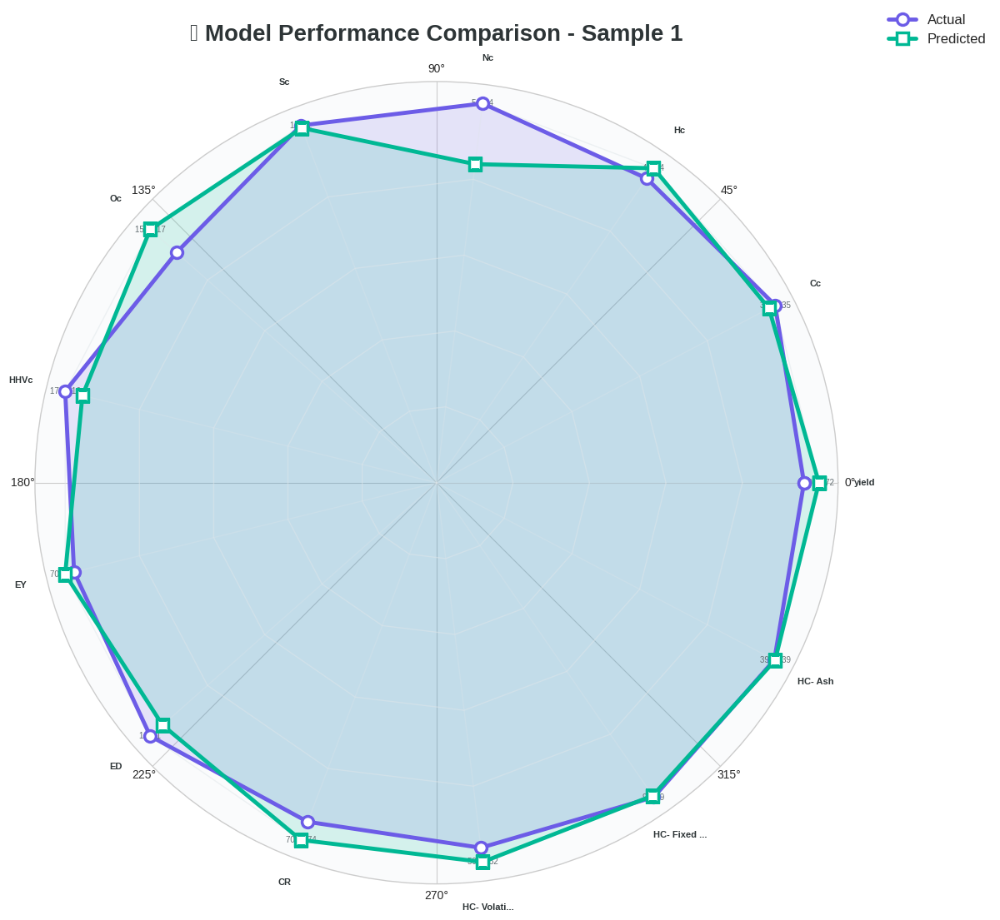

✅ Saved: /kaggle/working/radar_chart/radar_chart_elegant.png

📥 Download Links:

📄 radar_chart_sample1.png:


/kaggle/working/radar_chart/radar_chart_sample1.png


📄 radar_chart_elegant.png:


/kaggle/working/radar_chart/radar_chart_elegant.png


📂 All files are stored in: /kaggle/working/radar_chart/
✅ COMPLETE! Professional Radar Charts generated successfully!


In [10]:
# ============================================
# PROFESSIONAL RADAR CHART - SAMPLE 1 (FIXED)
# ============================================

print("\n" + "="*80)
print("🎨 GENERATING PROFESSIONAL RADAR CHART")
print("="*80)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import joblib
import os
import re
import warnings
warnings.filterwarnings('ignore')

# ============================================
# 1. LOAD MODEL AND DATA
# ============================================
print("\n📊 Loading model and data...")

winning_model = joblib.load('/kaggle/working/final_winning_model.pkl')
scaler = joblib.load('/kaggle/working/final_winning_scaler.pkl')

# ============================================
# 2. FIXED INPUT COLUMNS (Using actual column names)
# ============================================
# These are the ACTUAL column names from your data
input_cols = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 
              'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'Temperature(°C)', 
              'Reaction Time (min)']

output_cols = ['yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)',
               'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)',
               'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

# ============================================
# 3. SAMPLE 1 DATA (Using correct column order)
# ============================================
# Sample 1 Data - in the SAME ORDER as input_cols
sample1_input = {
    'C%': 34.78, 
    'H%': 3.93, 
    'N%': 5.04, 
    'S%': 1.15, 
    'O%': 20.32, 
    'Ash%': 31.77, 
    'Volatile matter%': 55.81, 
    'Fixed carbon%': 7.76, 
    'HHV (MJ/Kg)': 16.61, 
    'DM(%)': 4.5,  # Note: This is DM(%) not water Content
    'Temperature(°C)': 160, 
    'Reaction Time (min)': 30
}

sample1_output = {
    'yield(%)': 68.8, 
    'Cc (%)': 35.53, 
    'Hc(%)': 4.19, 
    'Nc(%)': 5.11, 
    'Sc(%)': 1.07, 
    'Oc(%)': 15.46, 
    'HHVc (MJ/Kg)': 16.97, 
    'EY(%)': 70.29114991, 
    'ED(%)': 1.021673691, 
    'CR(%)': 70.28361127,
    'HC- Volatile matter%': 49.65, 
    'HC- Fixed carbon%': 9.16, 
    'HC- Ash(%)': 38.63
}

# Create DataFrame with correct column order
df_input = pd.DataFrame([sample1_input])[input_cols]  # Ensure correct order
df_actual = pd.DataFrame([sample1_output])[output_cols]  # Ensure correct order

print("✅ Sample data prepared!")
print(f"Input columns: {df_input.columns.tolist()}")
print(f"Output columns: {df_actual.columns.tolist()}")

# ============================================
# 4. MAKE PREDICTIONS
# ============================================
print("\n📈 Making predictions...")
X_scaled = scaler.transform(df_input)
y_pred = winning_model.predict(X_scaled)
df_pred = pd.DataFrame(y_pred, columns=output_cols)

print("✅ Predictions completed!")

# ============================================
# 5. PREPARE DATA FOR RADAR CHART
# ============================================
print("\n🎨 Preparing radar chart...")

# Get values
actual_values = [df_actual[col].values[0] for col in output_cols]
pred_values = [df_pred[col].values[0] for col in output_cols]

# Normalize values (0-1 range)
max_vals = [max(actual_values[i], pred_values[i]) for i in range(len(output_cols))]
actual_norm = [actual_values[i] / max_vals[i] if max_vals[i] > 0 else 0 for i in range(len(output_cols))]
pred_norm = [pred_values[i] / max_vals[i] if max_vals[i] > 0 else 0 for i in range(len(output_cols))]

# Calculate errors
errors = [(abs(a - p) / a * 100) if a > 0 else 0 for a, p in zip(actual_values, pred_values)]

# ============================================
# 6. CREATE PROFESSIONAL RADAR CHART
# ============================================
print("\n🎨 Creating professional radar chart...")

output_dir = '/kaggle/working/radar_chart'
os.makedirs(output_dir, exist_ok=True)

# Number of variables
N = len(output_cols)

# Angle of each axis
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # Close the loop

# Values for actual and predicted
actual_vals = actual_norm + actual_norm[:1]
pred_vals = pred_norm + pred_norm[:1]

# ============================================
# CREATE THE RADAR CHART
# ============================================
fig, ax = plt.subplots(figsize=(16, 12), subplot_kw=dict(polar=True))

# ============================================
# 1. Background styling
# ============================================
ax.set_facecolor('#F8F9FA')
fig.patch.set_facecolor('white')

# ============================================
# 2. Draw grid with beautiful colors
# ============================================
for i in range(0, 11, 2):
    ax.plot(angles, [i/10]*len(angles), 
            color='#E8ECF1', linewidth=1.5, linestyle='-', alpha=0.7)
    ax.text(0, i/10 + 0.02, f'{i*10}%', 
            ha='center', va='bottom', fontsize=8, color='#A0AEC0', fontweight='bold')

# ============================================
# 3. Draw axis lines
# ============================================
for angle in angles[:-1]:
    ax.plot([angle, angle], [0, 1], 
            color='#D1D8E0', linewidth=1.5, linestyle='-', alpha=0.5)

# ============================================
# 4. Draw outer ring
# ============================================
ax.plot(angles, [1]*len(angles), 
        color='#2C3E50', linewidth=2, linestyle='-', alpha=0.3)

# ============================================
# 5. Fill area for Actual
# ============================================
ax.fill(angles, actual_vals, 
        color='#3498DB', 
        alpha=0.25,
        linewidth=0)

# ============================================
# 6. Draw Actual line
# ============================================
ax.plot(angles, actual_vals, 
        color='#2E86C1', 
        linewidth=4, 
        marker='o',
        markersize=12,
        markerfacecolor='#1A5276',
        markeredgecolor='white',
        markeredgewidth=2.5,
        label='Actual',
        zorder=5)

# ============================================
# 7. Fill area for Predicted
# ============================================
ax.fill(angles, pred_vals, 
        color='#E74C3C', 
        alpha=0.2,
        linewidth=0)

# ============================================
# 8. Draw Predicted line
# ============================================
ax.plot(angles, pred_vals, 
        color='#E74C3C', 
        linewidth=4, 
        marker='s',
        markersize=12,
        markerfacecolor='#922B21',
        markeredgecolor='white',
        markeredgewidth=2.5,
        label='Predicted',
        zorder=5)

# ============================================
# 9. Add labels with values
# ============================================
for i, angle in enumerate(angles[:-1]):
    act_val = actual_values[i]
    pred_val = pred_values[i]
    error = errors[i]
    
    error_color = '#27AE60' if error < 10 else '#F39C12' if error < 20 else '#E74C3C'
    
    # Shorten column names for display
    short_name = output_cols[i].replace('(%)', '').replace('(MJ/Kg)', '').strip()
    if len(short_name) > 12:
        short_name = short_name[:10] + '...'
    
    label_angle = angle
    if label_angle > pi/2 and label_angle < 3*pi/2:
        label_angle += pi
    
    ax.text(angle, 1.15, 
            f'{short_name}\n{act_val:.1f} vs {pred_val:.1f}',
            ha='center', va='center',
            fontsize=8, fontweight='bold',
            color='#2C3E50',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='gray', linewidth=1))
    
    error_icon = '✅' if error < 10 else '⚠️' if error < 20 else '❌'
    ax.text(angle, 0.95, 
            f'{error_icon} {error:.1f}%',
            ha='center', va='center',
            fontsize=8, fontweight='bold',
            color=error_color)

# ============================================
# 10. Add value dots
# ============================================
for i, angle in enumerate(angles[:-1]):
    ax.plot(angle, actual_vals[i], 'o', color='#1A5276', markersize=8, zorder=6)
    ax.plot(angle, pred_vals[i], 's', color='#922B21', markersize=8, zorder=6)

# ============================================
# 11. Styling
# ============================================
ax.set_yticks([])

legend = ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1),
                   fontsize=14, framealpha=0.95, fancybox=True, 
                   shadow=True, edgecolor='#2C3E50', borderpad=0.8)
legend.get_frame().set_facecolor('white')

# ============================================
# 12. Title and info
# ============================================
ax.set_title('📊 Model Performance Comparison - Sample 1',
             fontsize=22, fontweight='bold', color='#1A5276', pad=40)

avg_error = np.mean(errors)
max_error = np.max(errors)
min_error = np.min(errors)

info_text = (f'Summary Statistics\n'
             f'┌─────────────────────────┐\n'
             f'│ Average Error: {avg_error:.1f}%  │\n'
             f'│ Maximum Error: {max_error:.1f}%  │\n'
             f'│ Minimum Error: {min_error:.1f}%  │\n'
             f'└─────────────────────────┘')

ax.text(-0.15, 0.9, info_text,
        transform=ax.transAxes,
        fontsize=11, fontweight='bold',
        color='#2C3E50',
        bbox=dict(boxstyle='round,pad=0.8', facecolor='white', 
                 alpha=0.95, edgecolor='#2E86C1', linewidth=2),
        verticalalignment='top',
        horizontalalignment='left')

# ============================================
# 13. Save and display
# ============================================
plt.tight_layout()

save_path = f'{output_dir}/radar_chart_sample1.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
plt.close()

print(f"✅ Saved: {save_path}")

# ============================================
# VERSION 2: LIGHTER & MORE ELEGANT
# ============================================
print("\n🎨 Creating elegant version...")

fig, ax = plt.subplots(figsize=(14, 11), subplot_kw=dict(polar=True))

actual_color = '#6C5CE7'  # Purple
predicted_color = '#00B894'  # Mint Green

ax.set_facecolor('#FAFBFC')
fig.patch.set_facecolor('white')

for i in range(0, 11, 2):
    ax.plot(angles, [i/10]*len(angles), 
            color='#DFE6E9', linewidth=1, linestyle='-', alpha=0.5)

for angle in angles[:-1]:
    ax.plot([angle, angle], [0, 1], 
            color='#DFE6E9', linewidth=1, linestyle='-', alpha=0.3)

ax.fill(angles, actual_vals, color=actual_color, alpha=0.15)
ax.plot(angles, actual_vals, 
        color=actual_color, linewidth=3.5, 
        marker='o', markersize=10, 
        markerfacecolor='white', markeredgecolor=actual_color, markeredgewidth=2.5,
        label='Actual', zorder=5)

ax.fill(angles, pred_vals, color=predicted_color, alpha=0.15)
ax.plot(angles, pred_vals, 
        color=predicted_color, linewidth=3.5, 
        marker='s', markersize=10, 
        markerfacecolor='white', markeredgecolor=predicted_color, markeredgewidth=2.5,
        label='Predicted', zorder=5)

for i, angle in enumerate(angles[:-1]):
    act_val = actual_values[i]
    pred_val = pred_values[i]
    error = errors[i]
    
    short_name = output_cols[i].replace('(%)', '').replace('(MJ/Kg)', '').strip()
    if len(short_name) > 12:
        short_name = short_name[:10] + '...'
    
    ax.text(angle, 1.12, 
            f'{short_name}',
            ha='center', va='center',
            fontsize=8, fontweight='bold', color='#2D3436')
    
    ax.text(angle, 1.0, 
            f'{act_val:.0f} → {pred_val:.0f}',
            ha='center', va='center',
            fontsize=7, color='#636E72')

legend = ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1),
                   fontsize=12, framealpha=0.95, fancybox=True, shadow=True)
legend.get_frame().set_facecolor('white')

ax.set_title('✨ Model Performance Comparison - Sample 1',
             fontsize=20, fontweight='bold', color='#2D3436', pad=35)

ax.set_yticks([])

plt.tight_layout()

save_path2 = f'{output_dir}/radar_chart_elegant.png'
plt.savefig(save_path2, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
plt.close()

print(f"✅ Saved: {save_path2}")

# ============================================
# DISPLAY DOWNLOAD LINKS
# ============================================
print("\n" + "="*80)
print("📥 Download Links:")
print("="*80)

from IPython.display import FileLink, display

for f in os.listdir(output_dir):
    if f.endswith('.png'):
        file_path = f'{output_dir}/{f}'
        print(f"\n📄 {f}:")
        display(FileLink(file_path))

print(f"\n📂 All files are stored in: {output_dir}/")
print("="*80)
print("✅ COMPLETE! Professional Radar Charts generated successfully!")
print("="*80)

# SHAP Analysis for Multi-Output HTC Process 


🎨 RECALCULATING SHAP VALUES & GENERATING BEESWARM PLOTS

📊 Recalculating SHAP values using the winning model...
   Processing 1/13: yield(%)
   Processing 2/13: Cc (%)
   Processing 3/13: Hc(%)
   Processing 4/13: Nc(%)
   Processing 5/13: Sc(%)
   Processing 6/13: Oc(%)
   Processing 7/13: HHVc (MJ/Kg)
   Processing 8/13: EY(%)
   Processing 9/13: ED(%)
   Processing 10/13: CR(%)
   Processing 11/13: HC- Volatile matter%
   Processing 12/13: HC- Fixed carbon%
   Processing 13/13: HC- Ash(%)
✅ SHAP values recalculated successfully!

🎨 Generating Beeswarm plots with Magma color...

📌 Processing: yield(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_final/shap_beeswarm_yield%.png


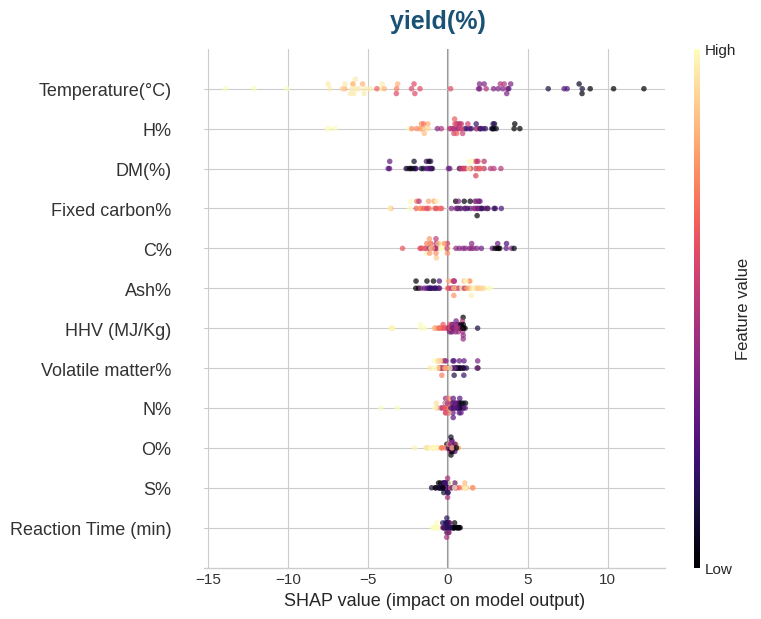


📌 Processing: Cc (%)
   ✅ Saved: /kaggle/working/shap_beeswarm_final/shap_beeswarm_Cc_%.png


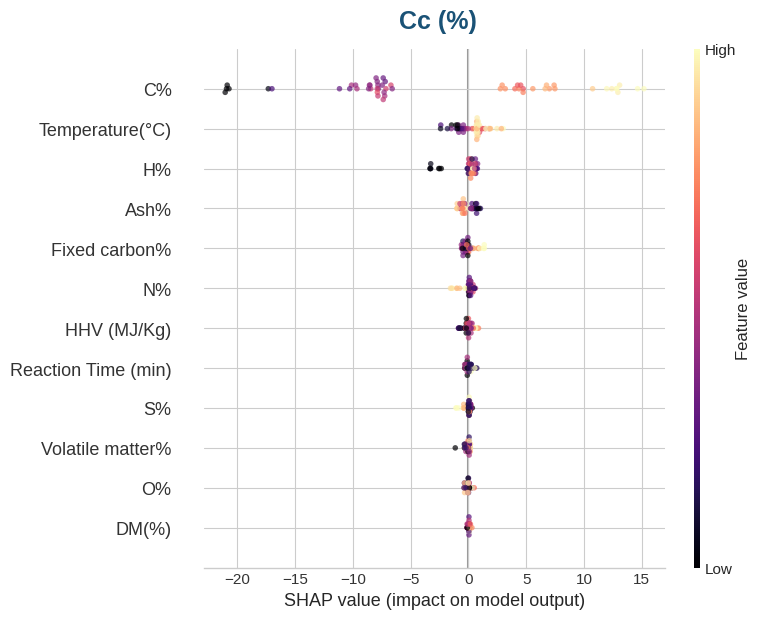


📌 Processing: Hc(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_final/shap_beeswarm_Hc%.png


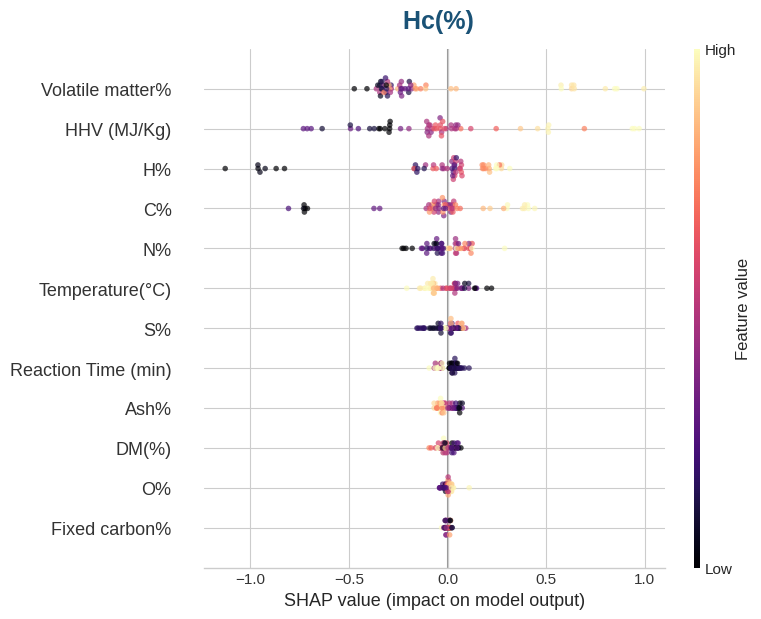


📌 Processing: Nc(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_final/shap_beeswarm_Nc%.png


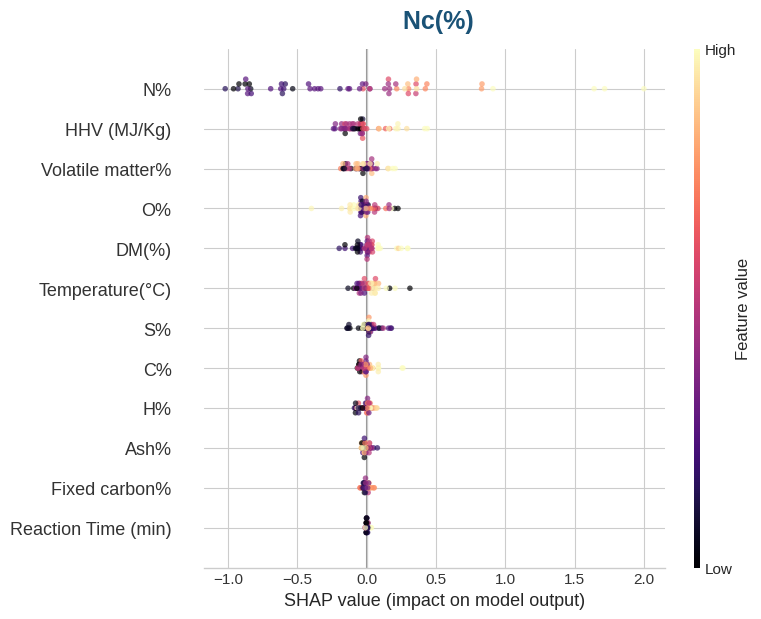


📌 Processing: Sc(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_final/shap_beeswarm_Sc%.png


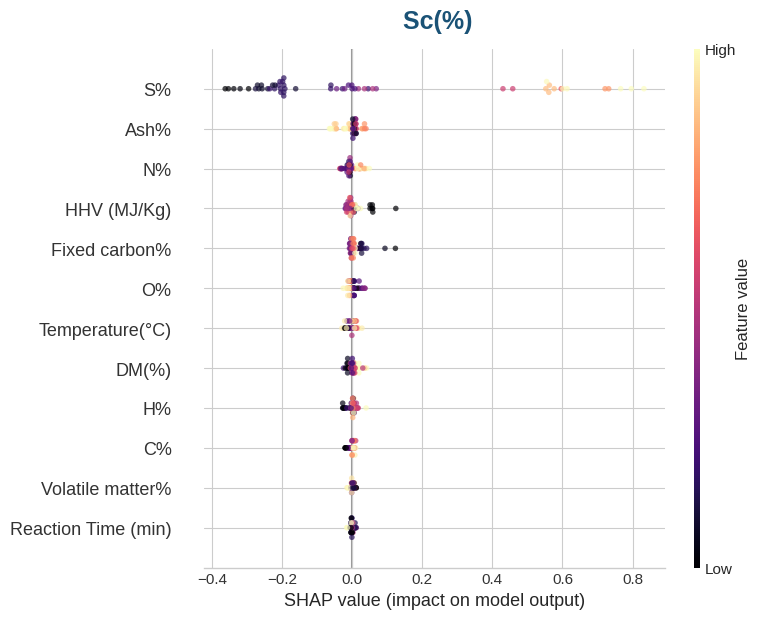


📌 Processing: Oc(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_final/shap_beeswarm_Oc%.png


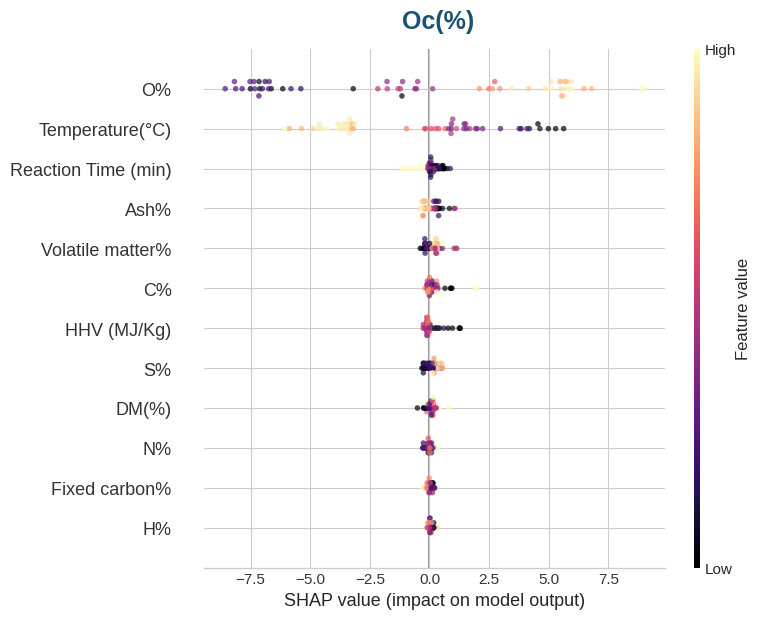


📌 Processing: HHVc (MJ/Kg)
   ✅ Saved: /kaggle/working/shap_beeswarm_final/shap_beeswarm_HHVc_MJ_Kg.png


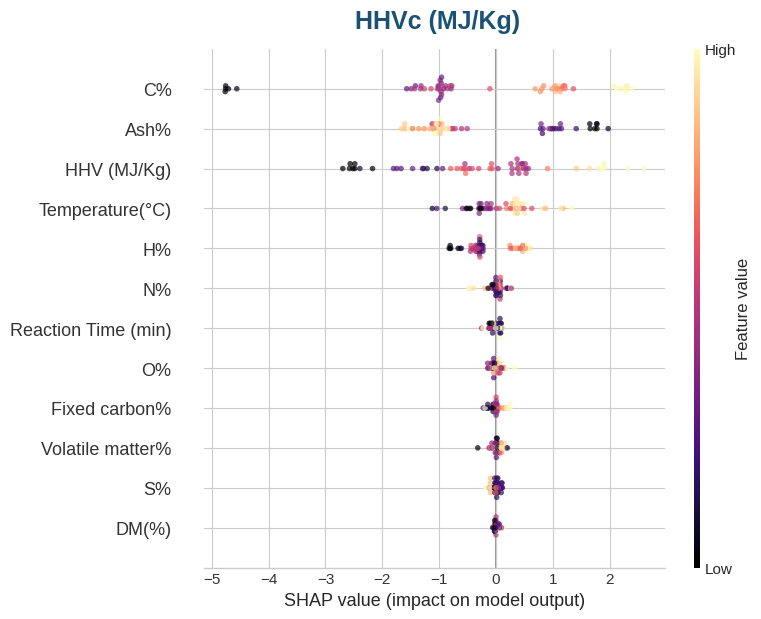


📌 Processing: EY(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_final/shap_beeswarm_EY%.png


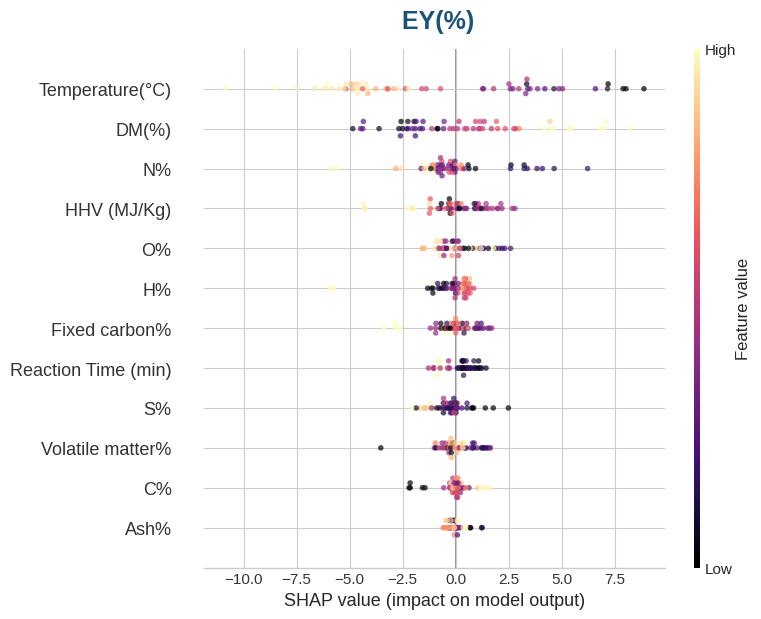


📌 Processing: ED(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_final/shap_beeswarm_ED%.png


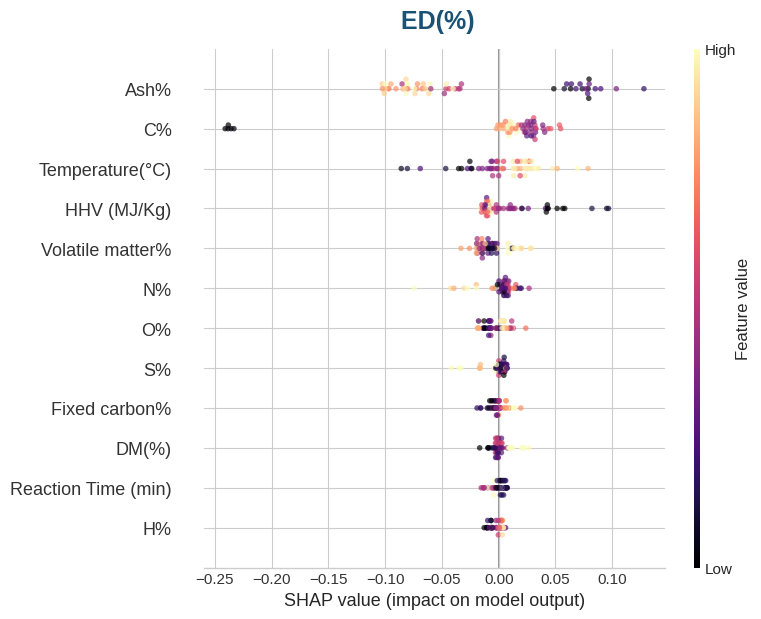


📌 Processing: CR(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_final/shap_beeswarm_CR%.png


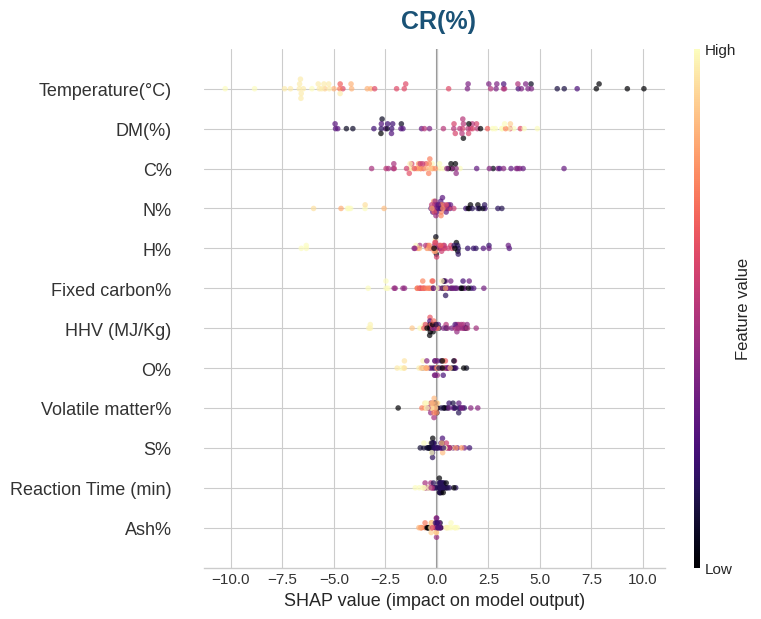


📌 Processing: HC- Volatile matter%
   ✅ Saved: /kaggle/working/shap_beeswarm_final/shap_beeswarm_HC-_Volatile_matter%.png


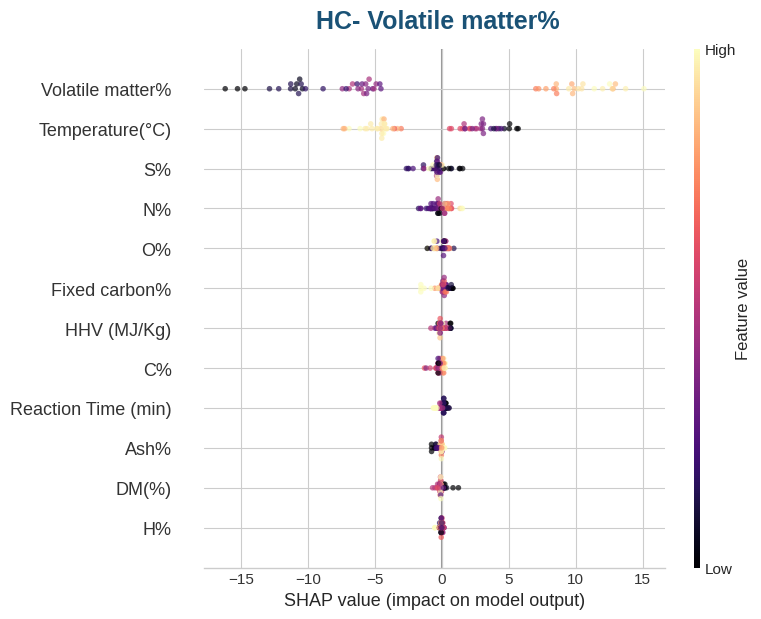


📌 Processing: HC- Fixed carbon%
   ✅ Saved: /kaggle/working/shap_beeswarm_final/shap_beeswarm_HC-_Fixed_carbon%.png


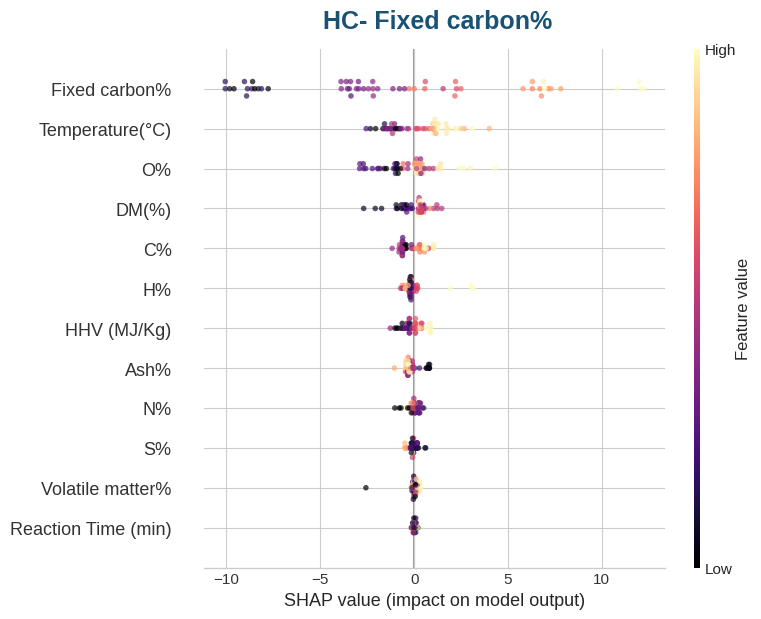


📌 Processing: HC- Ash(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_final/shap_beeswarm_HC-_Ash%.png


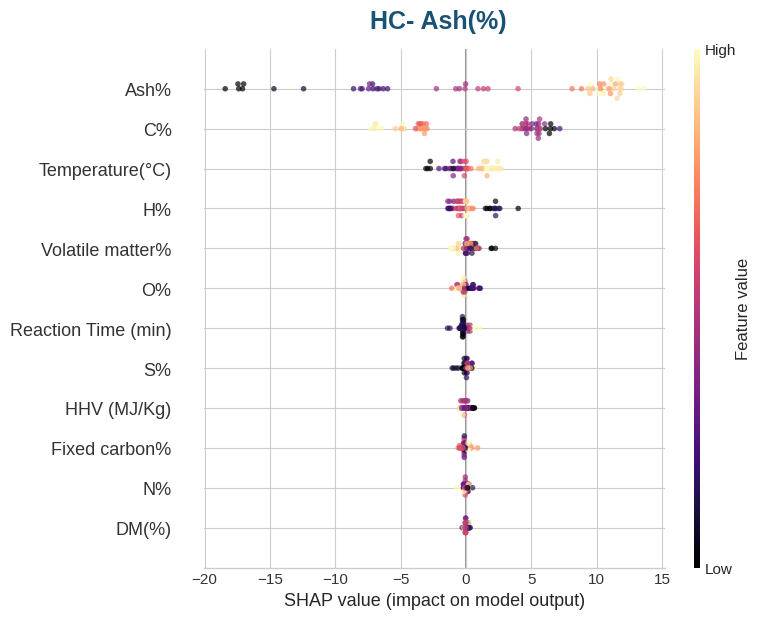


✅ ALL SHAP BEESWARM PLOTS GENERATED SUCCESSFULLY!

📥 Download the 600 DPI plots:

📄 yield(%):


/kaggle/working/shap_beeswarm_final/shap_beeswarm_yield%.png


📄 Cc (%):


/kaggle/working/shap_beeswarm_final/shap_beeswarm_Cc_%.png


📄 Hc(%):


/kaggle/working/shap_beeswarm_final/shap_beeswarm_Hc%.png

... (17 outputs left out)

/kaggle/working/shap_beeswarm_final/shap_beeswarm_HC-_Fixed_carbon%.png


📄 HC- Ash(%):


/kaggle/working/shap_beeswarm_final/shap_beeswarm_HC-_Ash%.png


📂 All files are stored in: /kaggle/working/shap_beeswarm_final/


In [11]:
# ============================================
# RECALCULATE SHAP & GENERATE BEESWARM PLOTS (Magma Color)
# ============================================

print("\n" + "="*80)
print("🎨 RECALCULATING SHAP VALUES & GENERATING BEESWARM PLOTS")
print("="*80)

import shap
import numpy as np
import matplotlib.pyplot as plt
import os

# Create output folder
output_dir = '/kaggle/working/shap_beeswarm_final'
os.makedirs(output_dir, exist_ok=True)

# Define colors (Magma for Beeswarm)
magma_cmap = plt.cm.get_cmap('magma')

# ============================================
# STEP 1: RECALCULATE SHAP VALUES
# ============================================
print("\n📊 Recalculating SHAP values using the winning model...")

# Dictionary to store SHAP values for each output
shap_values_dict = {}

for i, col in enumerate(output_cols):
    print(f"   Processing {i+1}/{len(output_cols)}: {col}")
    
    # Get the specific estimator for this output from the MultiOutputRegressor
    estimator = winning_model.estimators_[i]
    
    # Create SHAP explainer
    explainer = shap.TreeExplainer(estimator)
    shap_values = explainer.shap_values(X_test_scaled)
    
    shap_values_dict[col] = shap_values

print("✅ SHAP values recalculated successfully!")

# ============================================
# STEP 2: DRAW BEESWARM PLOTS
# ============================================
print("\n🎨 Generating Beeswarm plots with Magma color...")

for idx, col in enumerate(output_cols):
    print(f"\n📌 Processing: {col}")
    
    shap_values = shap_values_dict[col]
    
    # Create a large, clear figure for each output
    fig, ax = plt.subplots(figsize=(4, 5))
    
    # Draw the beeswarm plot
    shap.summary_plot(
        shap_values,
        X_test_scaled,
        feature_names=input_cols,
        show=False,
        max_display=12,       # Show top 12 features
        plot_type='dot',
        alpha=0.7,
        cmap=magma_cmap,
        color_bar=True
    )
    
    # Add Title
    ax.set_title(f' {col}', fontsize=18, fontweight='bold', color='#1A5276', pad=15)
    
    # Adjust layout
    plt.tight_layout()
    
    # Clean the filename safely
    safe_filename = col.replace(' ', '_').replace('(', '').replace(')', '').replace('/', '_')
    save_path = f'{output_dir}/shap_beeswarm_{safe_filename}.png'
    
    # Save with error handling
    try:
        plt.savefig(save_path, dpi=600, bbox_inches='tight', facecolor='white')
        print(f"   ✅ Saved: {save_path}")
    except Exception as e:
        print(f"   ⚠️ Could not save file for {col}. Error: {e}")
    
    # Show the plot
    plt.show()
    plt.close()

print("\n" + "="*80)
print("✅ ALL SHAP BEESWARM PLOTS GENERATED SUCCESSFULLY!")
print("="*80)

# ============================================
# STEP 3: DOWNLOAD LINKS
# ============================================
from IPython.display import FileLink, display
print("\n📥 Download the 600 DPI plots:")
for col in output_cols:
    safe_filename = col.replace(' ', '_').replace('(', '').replace(')', '').replace('/', '_')
    file_name = f'shap_beeswarm_{safe_filename}.png'
    file_path = f'{output_dir}/{file_name}'
    if os.path.exists(file_path):
        print(f"\n📄 {col}:")
        display(FileLink(file_path))

print("\n📂 All files are stored in: /kaggle/working/shap_beeswarm_final/")


🎨 GENERATING PROFESSIONAL SHAP PLOTS (3D Style Donut)

📌 Processing 1/13: yield(%)


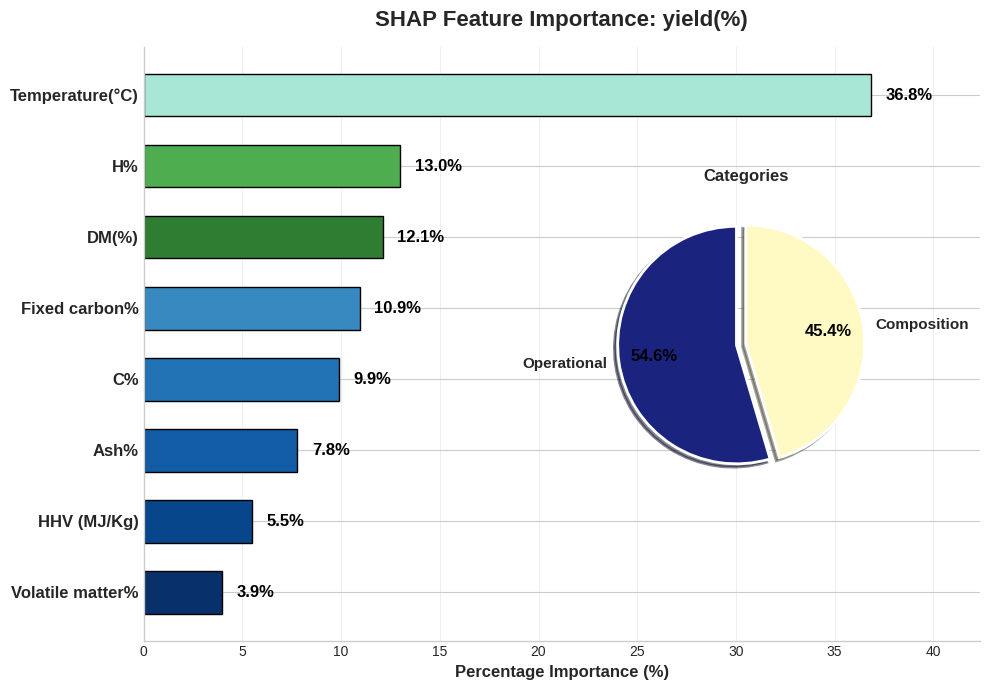

   ✅ Saved: /kaggle/working/shap_3d_donut/shap_3d_yield___.png

📌 Processing 2/13: Cc (%)


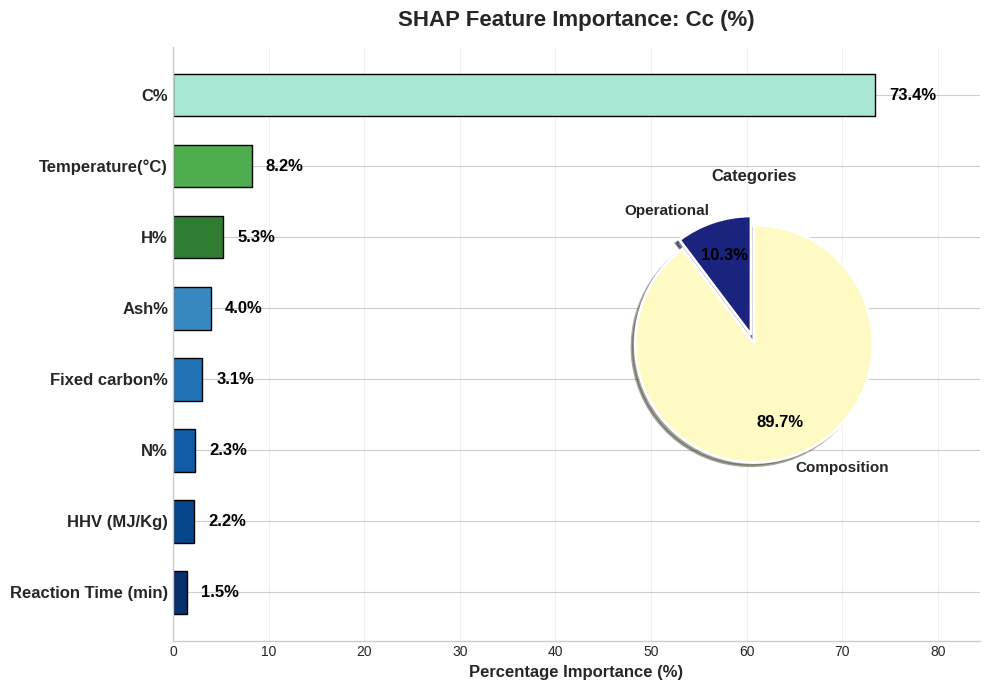

   ✅ Saved: /kaggle/working/shap_3d_donut/shap_3d_Cc____.png

📌 Processing 3/13: Hc(%)


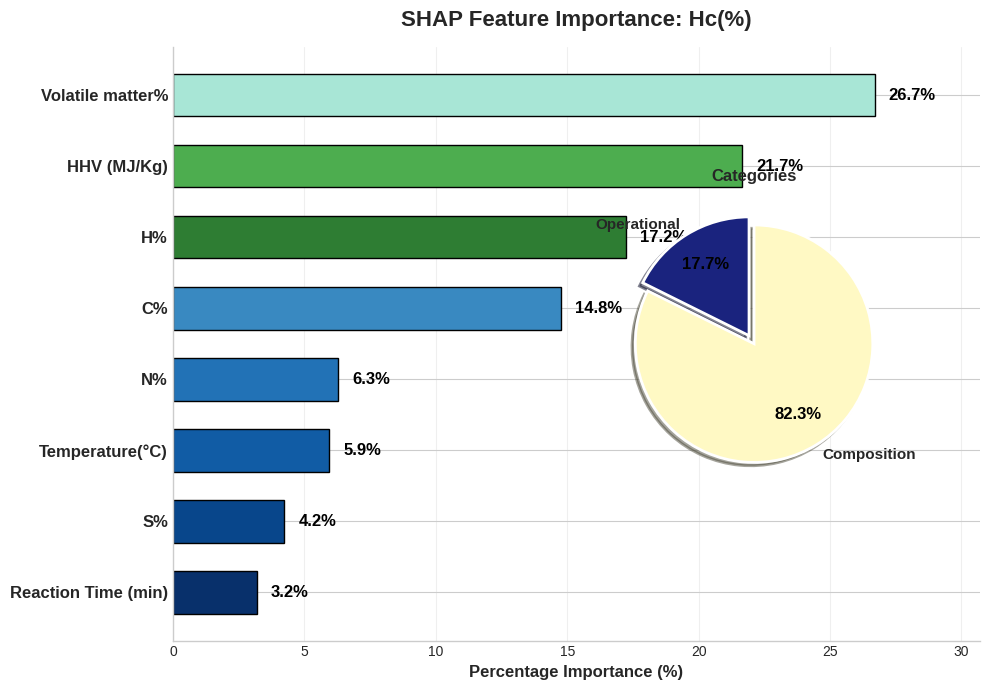

   ✅ Saved: /kaggle/working/shap_3d_donut/shap_3d_Hc___.png

📌 Processing 4/13: Nc(%)


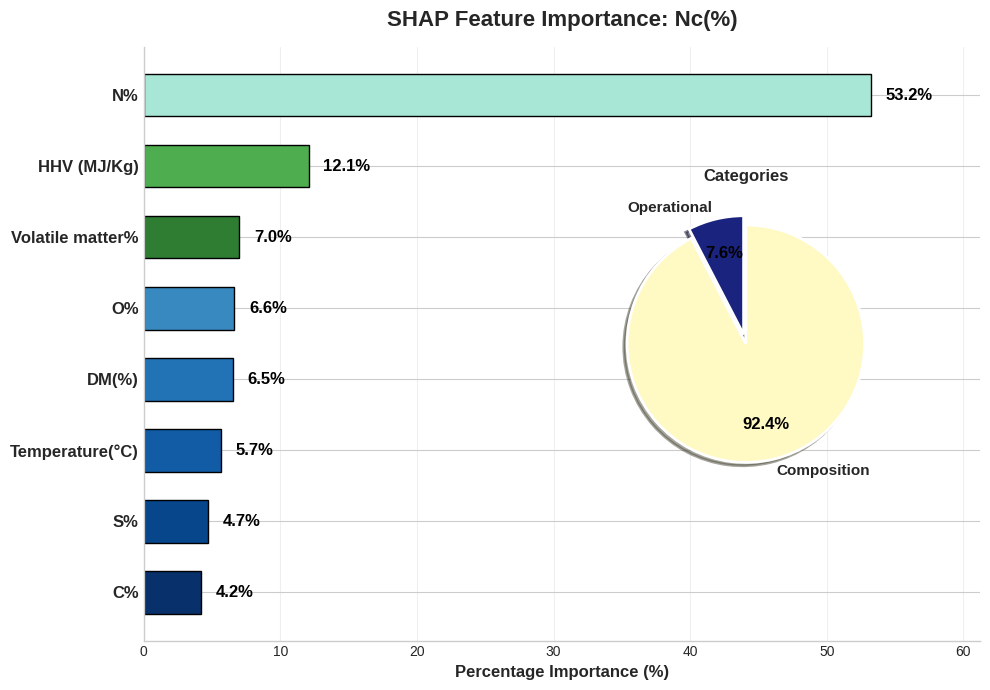

   ✅ Saved: /kaggle/working/shap_3d_donut/shap_3d_Nc___.png

📌 Processing 5/13: Sc(%)


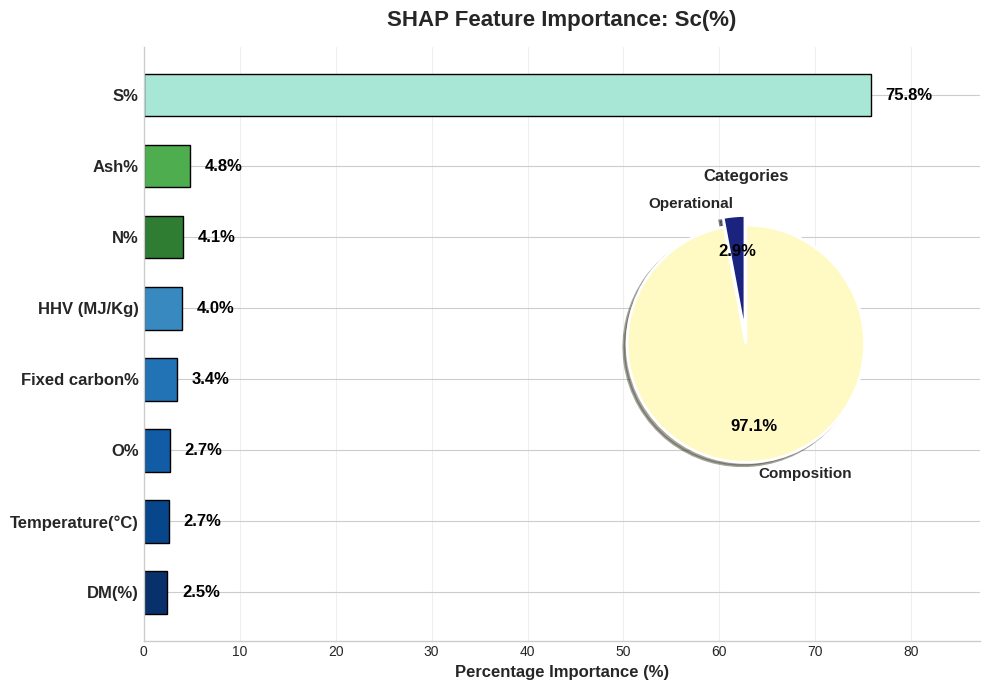

   ✅ Saved: /kaggle/working/shap_3d_donut/shap_3d_Sc___.png

📌 Processing 6/13: Oc(%)


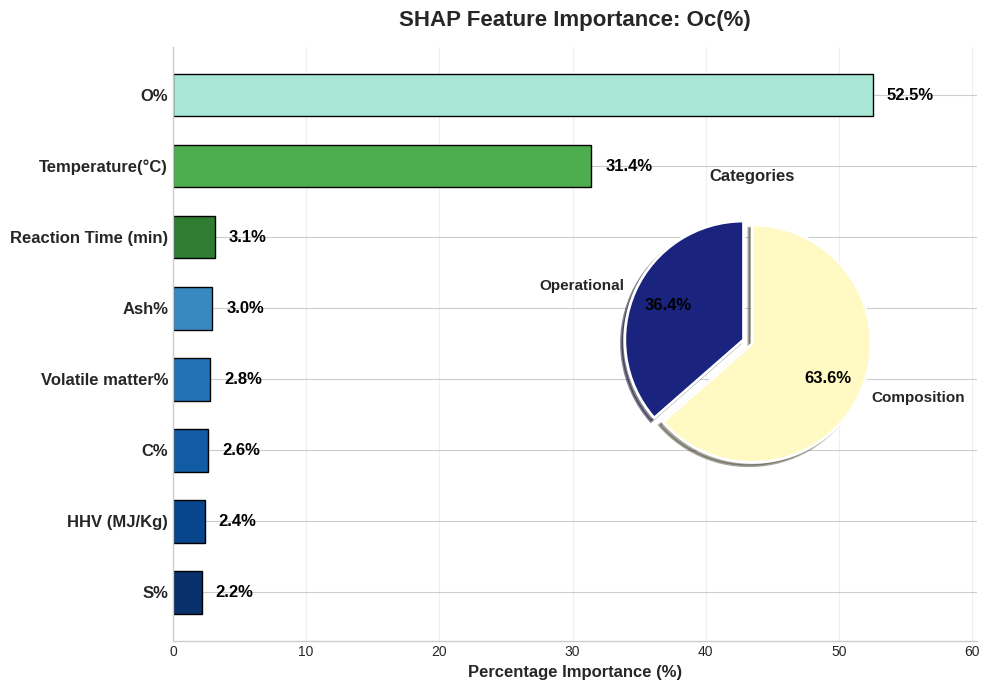

   ✅ Saved: /kaggle/working/shap_3d_donut/shap_3d_Oc___.png

📌 Processing 7/13: HHVc (MJ/Kg)


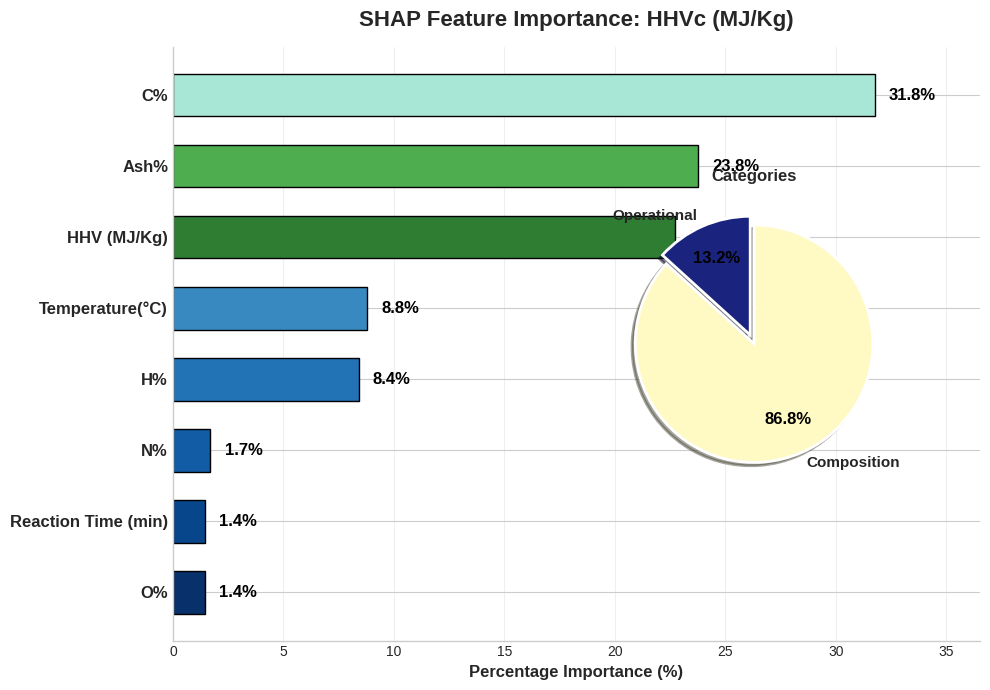

   ✅ Saved: /kaggle/working/shap_3d_donut/shap_3d_HHVc__MJ_Kg_.png

📌 Processing 8/13: EY(%)


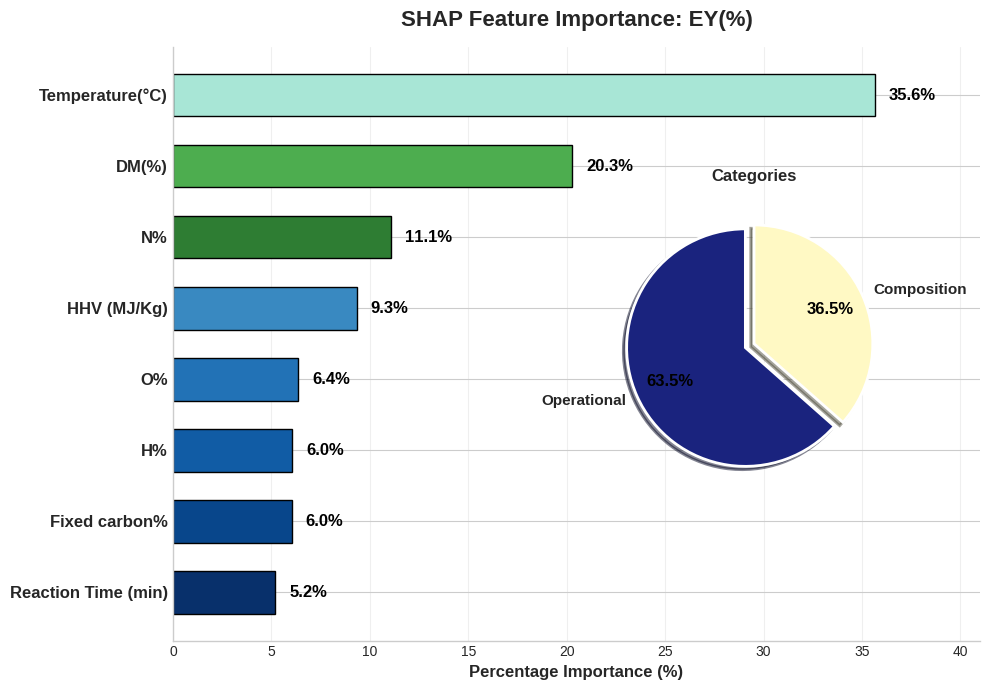

   ✅ Saved: /kaggle/working/shap_3d_donut/shap_3d_EY___.png

📌 Processing 9/13: ED(%)


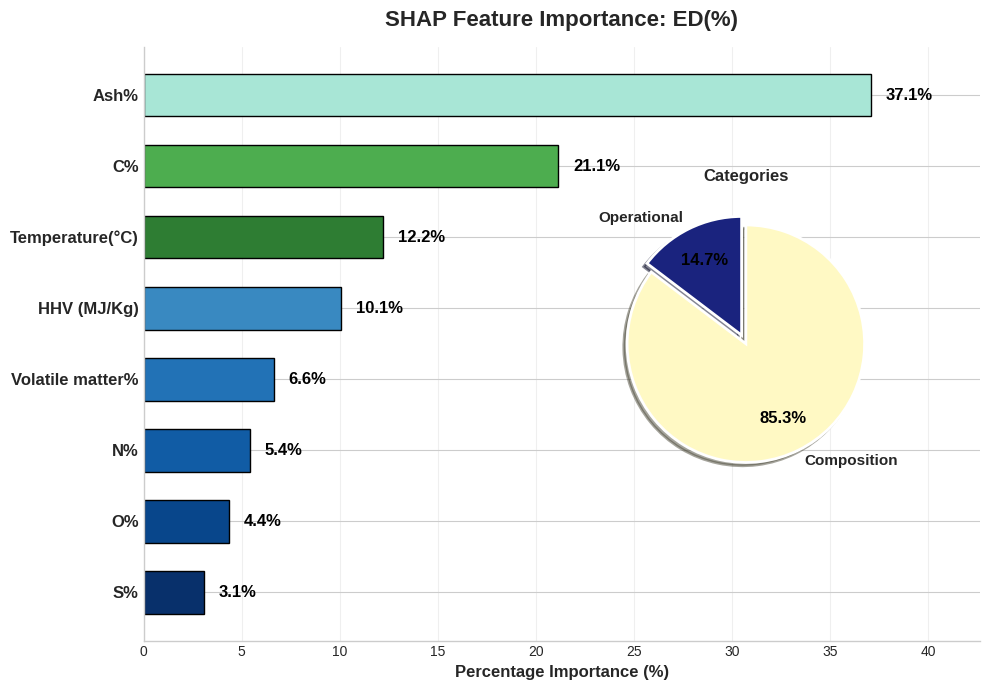

   ✅ Saved: /kaggle/working/shap_3d_donut/shap_3d_ED___.png

📌 Processing 10/13: CR(%)


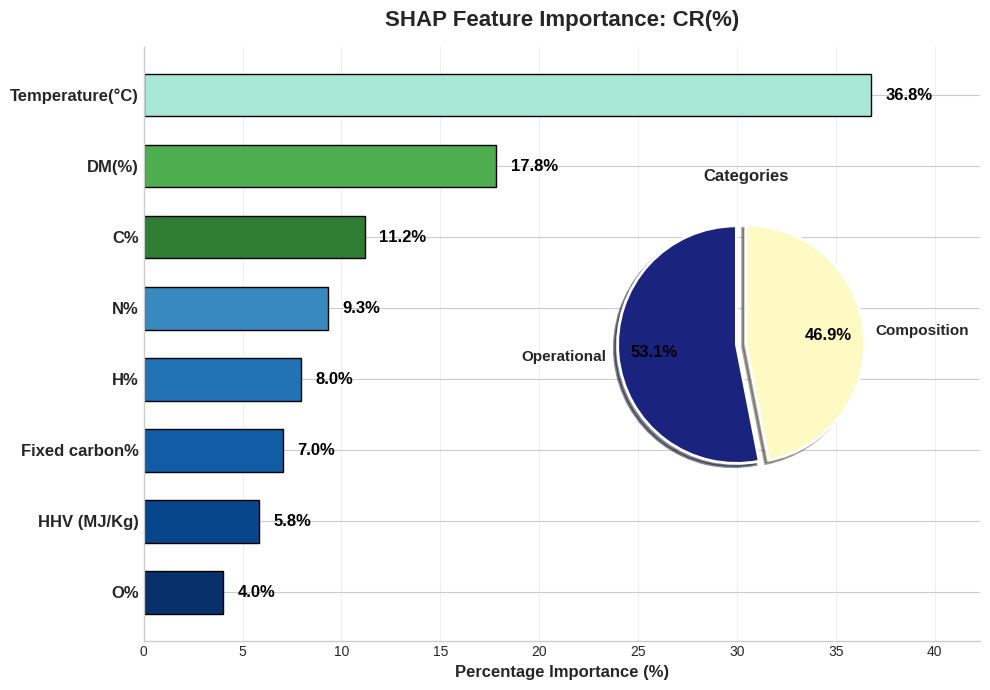

   ✅ Saved: /kaggle/working/shap_3d_donut/shap_3d_CR___.png

📌 Processing 11/13: HC- Volatile matter%


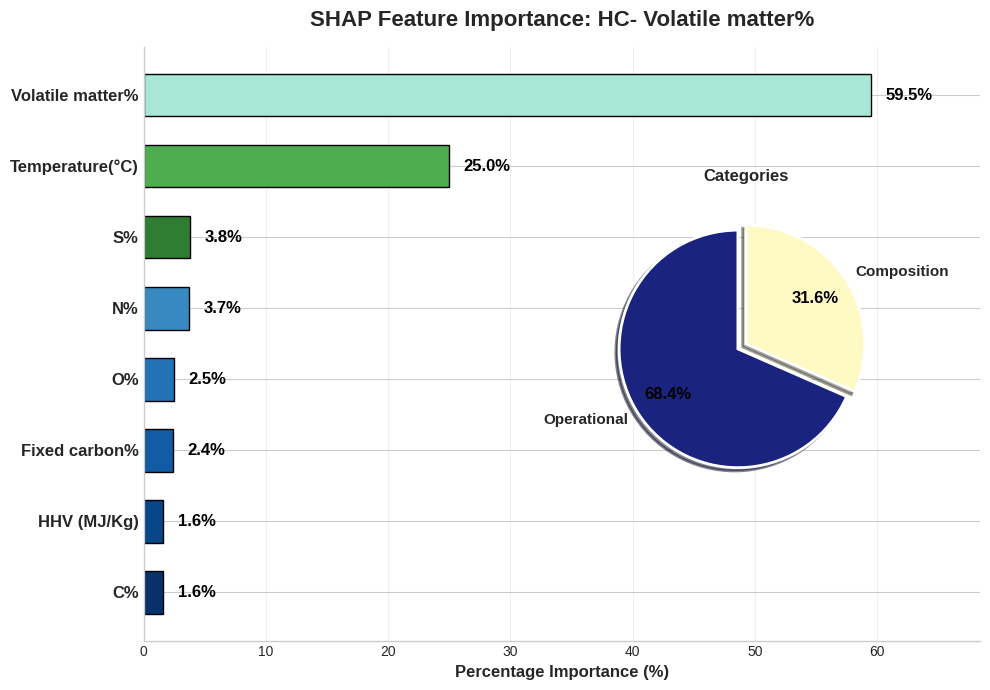

   ✅ Saved: /kaggle/working/shap_3d_donut/shap_3d_HC-_Volatile_matter_.png

📌 Processing 12/13: HC- Fixed carbon%


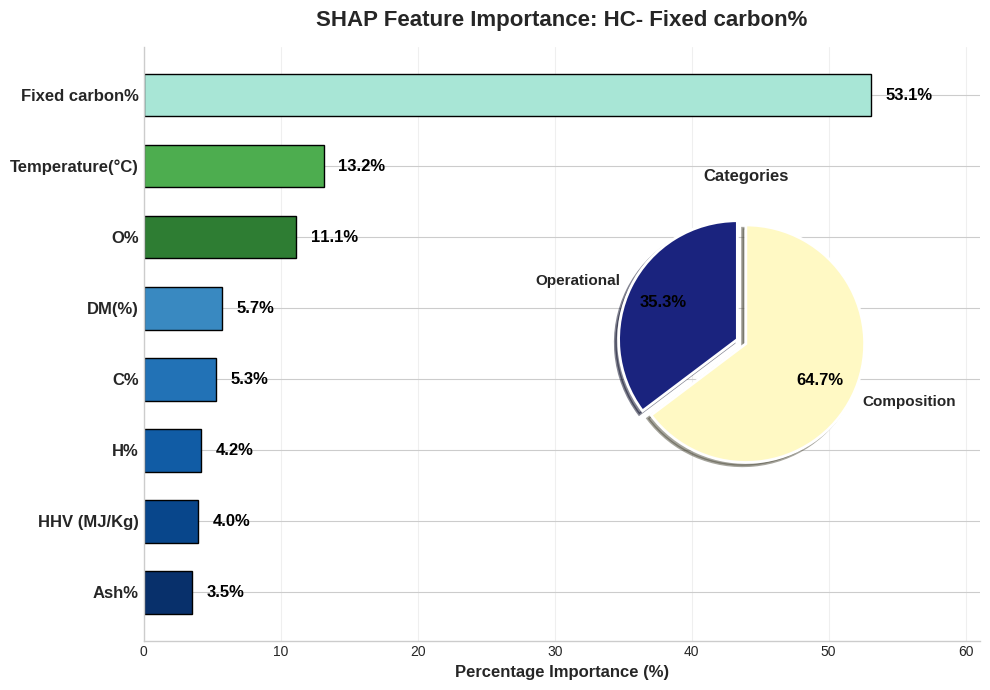

   ✅ Saved: /kaggle/working/shap_3d_donut/shap_3d_HC-_Fixed_carbon_.png

📌 Processing 13/13: HC- Ash(%)


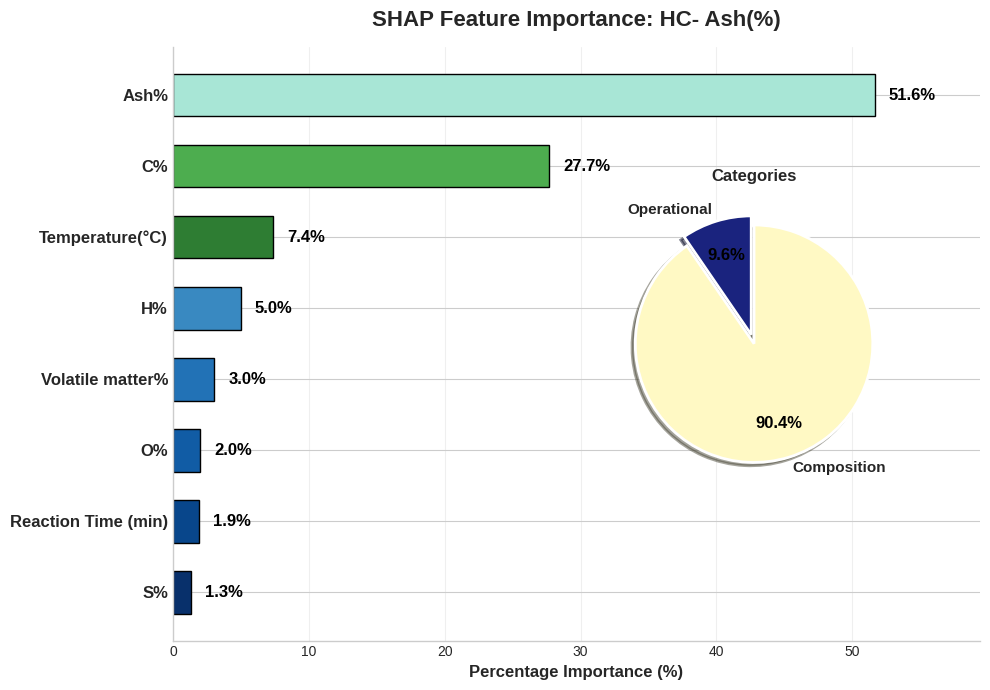

   ✅ Saved: /kaggle/working/shap_3d_donut/shap_3d_HC-_Ash___.png

✅ PROFESSIONAL 3D ILLUSION DONUT PLOTS COMPLETED!


In [12]:
# ============================================
# PROFESSIONAL SHAP PLOTS (3D Illusion Donut)
# ============================================

print("\n" + "="*80)
print("🎨 GENERATING PROFESSIONAL SHAP PLOTS (3D Style Donut)")
print("="*80)

import numpy as np
import matplotlib.pyplot as plt
import os
import re
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Create output folder
output_dir = '/kaggle/working/shap_3d_donut'
os.makedirs(output_dir, exist_ok=True)

# Use a clean, modern style
plt.rcParams['font.family'] = 'sans-serif'

for idx, col in enumerate(output_cols):
    print(f"\n📌 Processing {idx+1}/{len(output_cols)}: {col}")
    
    try:
        shap_values = shap_values_dict[col]
        
        # 1. Calculate Feature Importance
        importance = np.abs(shap_values).mean(axis=0)
        sorted_idx = np.argsort(importance)[::-1]
        
        top_k = min(8, len(input_cols))
        top_importance = importance[sorted_idx][:top_k]
        top_names = [input_cols[i] for i in sorted_idx[:top_k]]
        
        # 2. Calculate Percentages
        total_importance = np.sum(top_importance)
        percentages = (top_importance / total_importance) * 100
        
        # Reverse: Most Important at TOP
        top_names = top_names[::-1]
        percentages = percentages[::-1]
        top_importance = top_importance[::-1]
        
        # 3. Prepare Figure
        fig, ax = plt.subplots(figsize=(10, 7))
        
        # Bar colors
        colors = plt.cm.Blues(np.linspace(0.4, 1, len(top_names)))[::-1]
        
        if len(colors) >= 3:
            colors[-3] = (0.18, 0.49, 0.20, 1.0)
        if len(colors) >= 2:
            colors[-2] = (0.30, 0.68, 0.31, 1.0)
        if len(colors) >= 1:
            colors[-1] = (0.66, 0.90, 0.84, 1.0)
        
        # Draw bars
        y_pos = np.arange(len(top_names))
        bars = ax.barh(y_pos, percentages, color=colors, height=0.6, edgecolor='black')
        
        # Add text beside bars
        max_width = percentages.max()
        for bar, pct in zip(bars, percentages):
            width = bar.get_width()
            x_pos = width + (max_width * 0.02)
            ax.text(x_pos, bar.get_y() + bar.get_height()/2, 
                    f'{pct:.1f}%', 
                    ha='left', va='center', fontsize=12, fontweight='bold', color='black')
        
        ax.set_yticks(y_pos)
        ax.set_yticklabels(top_names, fontsize=12, fontweight='bold')
        ax.set_xlim(0, max_width * 1.15)
        ax.set_xlabel('Percentage Importance (%)', fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3, axis='x')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        
        # --- 🔥 3D ILLUSION DONUT (Same Position: 0.22, 0.00) ---
        # To create 3D illusion, we use a small trick:
        # - We draw the donut with a darker outline and a subtle side shadow.
        axins = inset_axes(ax, width="40%", height="50%", 
                           loc='center', 
                           bbox_to_anchor=(0.22, 0.00, 1, 1), 
                           bbox_transform=ax.transAxes)
        
        # Grouping categories
        group1 = ['Temperature(°C)', 'Reaction Time (min)', 'water Content']
        group2 = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%']
        
        group1_imp = 0
        group2_imp = 0
        for name, imp in zip(top_names, top_importance):
            if name in group1:
                group1_imp += imp
            elif name in group2:
                group2_imp += imp
        
        if group1_imp + group2_imp == 0:
            pie_data = [35.7, 64.3]
        else:
            total = group1_imp + group2_imp
            pie_data = [group1_imp / total * 100, group2_imp / total * 100]
        
        labels = ['Operational', 'Composition']
        pie_colors = ['#1A237E', '#FFF9C4']
        
        # --- 🎯 3D STYLE DONUT ---
        # 1. We add a slight rotation angle (shadow effect)
        # 2. We use a thick edge and a slight offset for the second set of wedges (shadow)
        
        wedges, texts, autotexts = axins.pie(
            pie_data, 
            labels=labels, 
            colors=pie_colors, 
            autopct='%1.1f%%', 
            startangle=90,
            pctdistance=0.7,
            explode=(0.08, 0),
            shadow=True,               # ✅ Built-in 3D shadow effect
            textprops={'fontsize': 11, 'fontweight': 'bold'},
            wedgeprops={
                'edgecolor': 'white',  # White edges for depth
                'linewidth': 2
            }
        )
        
        # Fine-tune text colors
        for autotext in autotexts:
            autotext.set_color('black')
            autotext.set_fontsize(12)
        
        axins.set_title('Categories', fontsize=12, fontweight='bold', pad=10)
        
        # --- Main Title ---
        ax.set_title(f'SHAP Feature Importance: {col}', fontsize=16, fontweight='bold', pad=15)
        
        plt.tight_layout()
        
        # Save
        safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
        save_path = f'{output_dir}/shap_3d_{safe_filename}.png'
        plt.savefig(save_path, dpi=600, bbox_inches='tight', facecolor='white')
        
        plt.show()
        plt.close()
        
        print(f"   ✅ Saved: {save_path}")
        
    except Exception as e:
        print(f"   ⚠️ Error in {col}: {e}")

print("\n" + "="*80)
print("✅ PROFESSIONAL 3D ILLUSION DONUT PLOTS COMPLETED!")
print("="*80)


🎨 RECALCULATING SHAP VALUES & GENERATING BEESWARM PLOTS

📊 Recalculating SHAP values using the winning model...
   Processing 1/13: yield(%)
   Processing 2/13: Cc (%)
   Processing 3/13: Hc(%)
   Processing 4/13: Nc(%)
   Processing 5/13: Sc(%)
   Processing 6/13: Oc(%)
   Processing 7/13: HHVc (MJ/Kg)
   Processing 8/13: EY(%)
   Processing 9/13: ED(%)
   Processing 10/13: CR(%)
   Processing 11/13: HC- Volatile matter%
   Processing 12/13: HC- Fixed carbon%
   Processing 13/13: HC- Ash(%)
✅ SHAP values recalculated successfully!

🎨 Generating Beeswarm plots with full control...

📌 Processing: yield(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_manual/shap_beeswarm_yield%.png


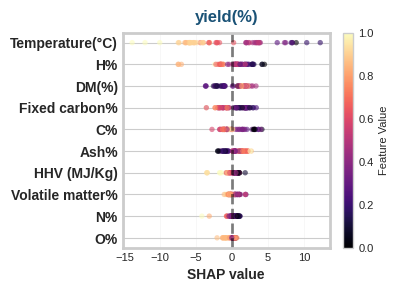


📌 Processing: Cc (%)
   ✅ Saved: /kaggle/working/shap_beeswarm_manual/shap_beeswarm_Cc_%.png


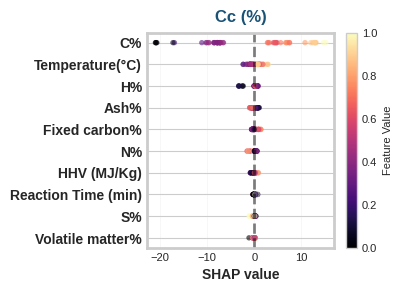


📌 Processing: Hc(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_manual/shap_beeswarm_Hc%.png


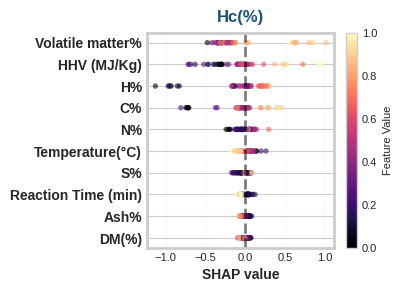


📌 Processing: Nc(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_manual/shap_beeswarm_Nc%.png


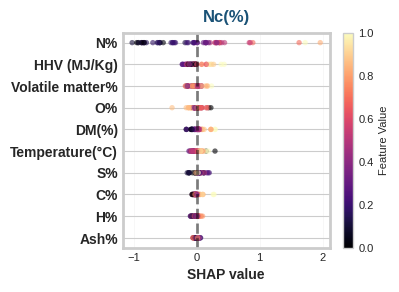


📌 Processing: Sc(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_manual/shap_beeswarm_Sc%.png


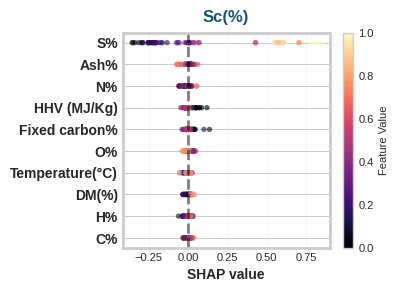


📌 Processing: Oc(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_manual/shap_beeswarm_Oc%.png


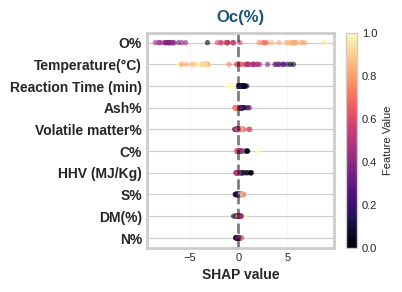


📌 Processing: HHVc (MJ/Kg)
   ✅ Saved: /kaggle/working/shap_beeswarm_manual/shap_beeswarm_HHVc_MJ_Kg.png


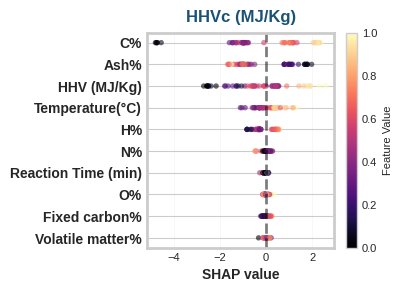


📌 Processing: EY(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_manual/shap_beeswarm_EY%.png


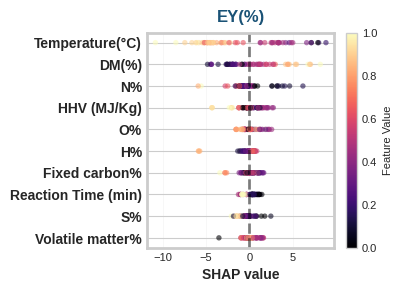


📌 Processing: ED(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_manual/shap_beeswarm_ED%.png


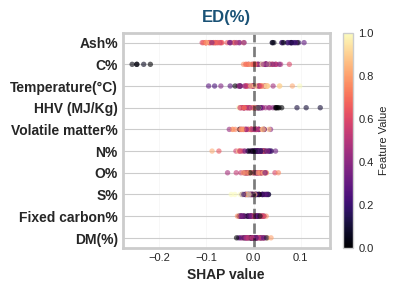


📌 Processing: CR(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_manual/shap_beeswarm_CR%.png


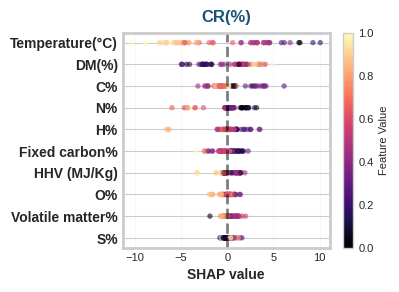


📌 Processing: HC- Volatile matter%
   ✅ Saved: /kaggle/working/shap_beeswarm_manual/shap_beeswarm_HC-_Volatile_matter%.png


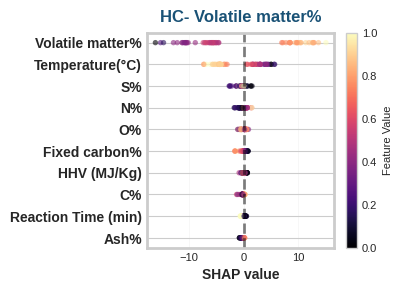


📌 Processing: HC- Fixed carbon%
   ✅ Saved: /kaggle/working/shap_beeswarm_manual/shap_beeswarm_HC-_Fixed_carbon%.png


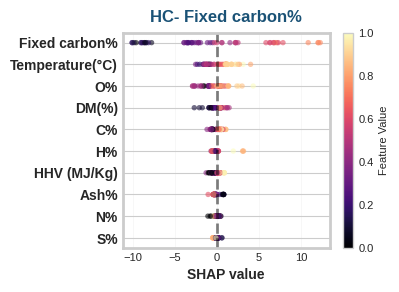


📌 Processing: HC- Ash(%)
   ✅ Saved: /kaggle/working/shap_beeswarm_manual/shap_beeswarm_HC-_Ash%.png


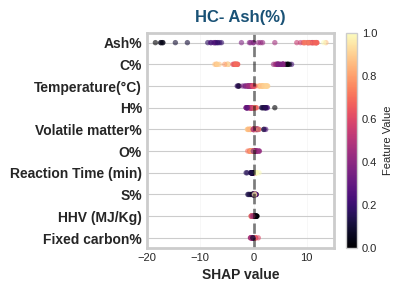


✅ ALL SHAP BEESWARM PLOTS GENERATED SUCCESSFULLY!

📥 Download the plots:

📄 yield(%):


/kaggle/working/shap_beeswarm_manual/shap_beeswarm_yield%.png


📄 Cc (%):


/kaggle/working/shap_beeswarm_manual/shap_beeswarm_Cc_%.png


📄 Hc(%):


/kaggle/working/shap_beeswarm_manual/shap_beeswarm_Hc%.png

... (17 outputs left out)

/kaggle/working/shap_beeswarm_manual/shap_beeswarm_HC-_Fixed_carbon%.png


📄 HC- Ash(%):


/kaggle/working/shap_beeswarm_manual/shap_beeswarm_HC-_Ash%.png


📂 All files are stored in: /kaggle/working/shap_beeswarm_manual/


In [13]:
# ============================================
# ============================================
# RECALCULATE SHAP & GENERATE BEESWARM PLOTS (Manual Control)
# ============================================

print("\n" + "="*80)
print("🎨 RECALCULATING SHAP VALUES & GENERATING BEESWARM PLOTS")
print("="*80)

import shap
import numpy as np
import matplotlib.pyplot as plt
import os

# Create output folder
output_dir = '/kaggle/working/shap_beeswarm_manual'
os.makedirs(output_dir, exist_ok=True)

# Define colors (Magma for Beeswarm)
magma_cmap = plt.cm.get_cmap('magma')

# ============================================
# STEP 1: RECALCULATE SHAP VALUES
# ============================================
print("\n📊 Recalculating SHAP values using the winning model...")

# Dictionary to store SHAP values for each output
shap_values_dict = {}

for i, col in enumerate(output_cols):
    print(f"   Processing {i+1}/{len(output_cols)}: {col}")
    
    # Get the specific estimator for this output from the MultiOutputRegressor
    estimator = winning_model.estimators_[i]
    
    # Create SHAP explainer
    explainer = shap.TreeExplainer(estimator)
    shap_values = explainer.shap_values(X_test_scaled)
    
    shap_values_dict[col] = shap_values

print("✅ SHAP values recalculated successfully!")

# ============================================
# STEP 2: DRAW BEESWARM PLOTS WITH FULL CONTROL
# ============================================
print("\n🎨 Generating Beeswarm plots with full control...")

# 🛠️ التحكم في أبعاد الرسم
FIGURE_WIDTH = 4      # عرض الرسمة (بالبوصة)
FIGURE_HEIGHT = 3     # ارتفاع الرسمة (بالبوصة)
FONT_SIZE = 10        # حجم الخط للميزات
LINE_WIDTH = 2        # سمك الخط للميزات
MAX_DISPLAY = 10      # عدد الميزات المعروضة

for idx, col in enumerate(output_cols):
    print(f"\n📌 Processing: {col}")
    
    shap_values = shap_values_dict[col]
    
    # حساب أهمية الميزات
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1][:MAX_DISPLAY]
    
    # 🛠️ عكس الترتيب بحيث تكون الميزات الأكثر أهمية في الأعلى
    sorted_idx = sorted_idx[::-1]  # <--- هذا السطر يعكس الترتيب
    
    # 🛠️ إنشاء الرسمة بالأبعاد المطلوبة
    fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), dpi=100)
    
    # رسم Beeswarm يدوياً
    for i, feat_idx in enumerate(sorted_idx):
        # الحصول على قيم SHAP للميزة
        shap_vals = shap_values[:, feat_idx]
        
        # إضافة تشتت (jitter) لتأثير Beeswarm
        jitter = np.random.normal(0, 0.015, len(shap_vals))
        x = shap_vals + jitter
        y = np.ones(len(shap_vals)) * i
        
        # تلوين بناءً على قيم الميزات
        feature_vals = X_test_scaled[:, feat_idx]
        norm_vals = (feature_vals - feature_vals.min()) / (feature_vals.max() - feature_vals.min() + 1e-8)
        colors = magma_cmap(norm_vals)
        
        # رسم النقاط
        ax.scatter(x, y, c=colors, alpha=0.6, s=15, edgecolors='none')
    
    # 🛠️ التحكم في المحور الرأسي (أسماء الميزات)
    ax.set_yticks(range(len(sorted_idx)))
    ax.set_yticklabels([input_cols[i] for i in sorted_idx], 
                       fontsize=FONT_SIZE, 
                       fontweight='bold')
    
    # 🛠️ زيادة سمك خطوط المحور
    ax.spines['left'].set_linewidth(LINE_WIDTH)
    ax.spines['bottom'].set_linewidth(LINE_WIDTH)
    ax.spines['top'].set_linewidth(LINE_WIDTH)
    ax.spines['right'].set_linewidth(LINE_WIDTH)
    
    # 🛠️ التحكم في حجم خط المحور السيني
    ax.tick_params(axis='x', labelsize=FONT_SIZE-2, width=LINE_WIDTH)
    ax.tick_params(axis='y', width=LINE_WIDTH)
    
    # 🛠️ إضافة خط عمودي عند الصفر بسمك محدد
    ax.axvline(x=0, color='black', linestyle='--', alpha=0.5, linewidth=LINE_WIDTH)
    
    # 🛠️ إضافة شبكة
    ax.grid(True, alpha=0.2, axis='x', linestyle='-', linewidth=0.5)
    
    # عنوان المحور السيني
    ax.set_xlabel('SHAP value', fontsize=FONT_SIZE, fontweight='bold')
    
    # 🛠️ Add Title بحجم مناسب
    ax.set_title(f'{col}', fontsize=FONT_SIZE+2, fontweight='bold', color='#1A5276', pad=8)
    
    # 🛠️ إضافة Colorbar
    sm = plt.cm.ScalarMappable(cmap=magma_cmap, 
                               norm=plt.Normalize(vmin=0, vmax=1))
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, shrink=1.0)
    cbar.set_label('Feature Value', fontsize=FONT_SIZE-2)
    cbar.ax.tick_params(labelsize=FONT_SIZE-2)
    
    # ضبط التباعد
    plt.tight_layout(pad=1.0)
    
    # حفظ الرسمة
    safe_filename = col.replace(' ', '_').replace('(', '').replace(')', '').replace('/', '_')
    save_path = f'{output_dir}/shap_beeswarm_{safe_filename}.png'
    
    try:
        plt.savefig(save_path, dpi=600, bbox_inches='tight', facecolor='white')
        print(f"   ✅ Saved: {save_path}")
    except Exception as e:
        print(f"   ⚠️ Could not save file for {col}. Error: {e}")
    
    plt.show()
    plt.close()

print("\n" + "="*80)
print("✅ ALL SHAP BEESWARM PLOTS GENERATED SUCCESSFULLY!")
print("="*80)

# ============================================
# STEP 3: DOWNLOAD LINKS
# ============================================
from IPython.display import FileLink, display
print("\n📥 Download the plots:")
for col in output_cols:
    safe_filename = col.replace(' ', '_').replace('(', '').replace(')', '').replace('/', '_')
    file_name = f'shap_beeswarm_{safe_filename}.png'
    file_path = f'{output_dir}/{file_name}'
    if os.path.exists(file_path):
        print(f"\n📄 {col}:")
        display(FileLink(file_path))

print("\n📂 All files are stored in: /kaggle/working/shap_beeswarm_manual/")


🎨 GENERATING PROFESSIONAL SHAP PLOTS (3D Style Donut - Compact)

📌 Processing 1/13: yield(%)


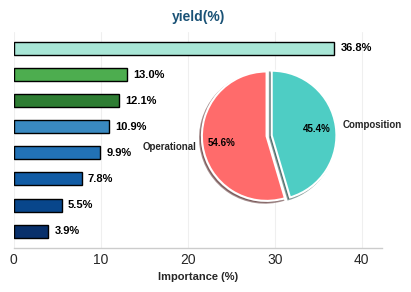

   ✅ Saved: /kaggle/working/shap_3d_donut_compact/shap_3d_yield___.png

📌 Processing 2/13: Cc (%)


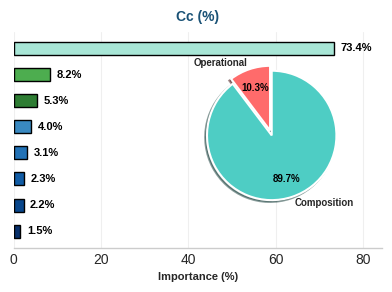

   ✅ Saved: /kaggle/working/shap_3d_donut_compact/shap_3d_Cc____.png

📌 Processing 3/13: Hc(%)


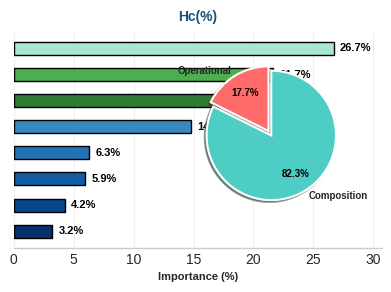

   ✅ Saved: /kaggle/working/shap_3d_donut_compact/shap_3d_Hc___.png

📌 Processing 4/13: Nc(%)


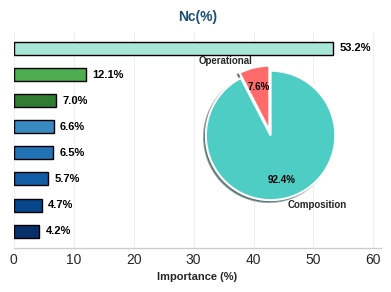

   ✅ Saved: /kaggle/working/shap_3d_donut_compact/shap_3d_Nc___.png

📌 Processing 5/13: Sc(%)


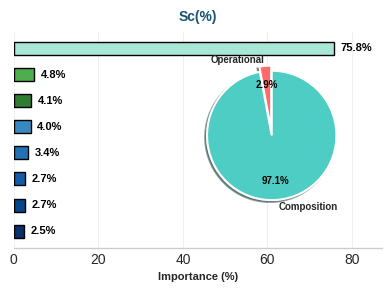

   ✅ Saved: /kaggle/working/shap_3d_donut_compact/shap_3d_Sc___.png

📌 Processing 6/13: Oc(%)


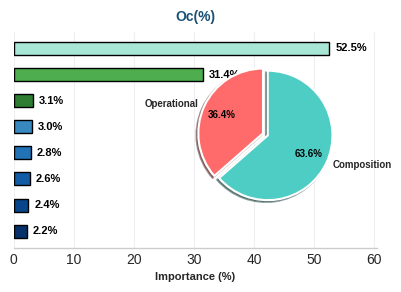

   ✅ Saved: /kaggle/working/shap_3d_donut_compact/shap_3d_Oc___.png

📌 Processing 7/13: HHVc (MJ/Kg)


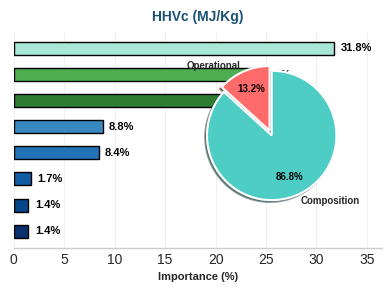

   ✅ Saved: /kaggle/working/shap_3d_donut_compact/shap_3d_HHVc__MJ_Kg_.png

📌 Processing 8/13: EY(%)


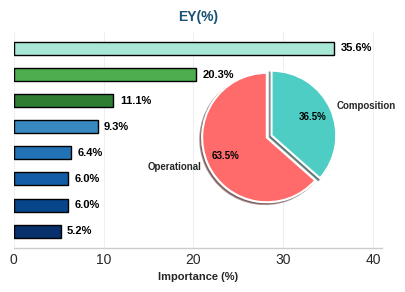

   ✅ Saved: /kaggle/working/shap_3d_donut_compact/shap_3d_EY___.png

📌 Processing 9/13: ED(%)


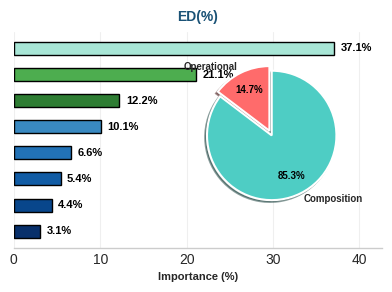

   ✅ Saved: /kaggle/working/shap_3d_donut_compact/shap_3d_ED___.png

📌 Processing 10/13: CR(%)


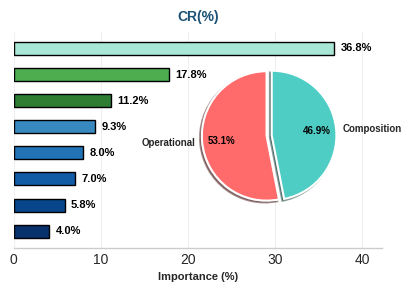

   ✅ Saved: /kaggle/working/shap_3d_donut_compact/shap_3d_CR___.png

📌 Processing 11/13: HC- Volatile matter%


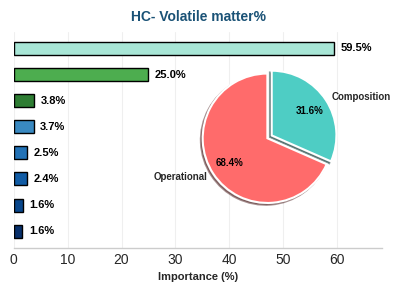

   ✅ Saved: /kaggle/working/shap_3d_donut_compact/shap_3d_HC-_Volatile_matter_.png

📌 Processing 12/13: HC- Fixed carbon%


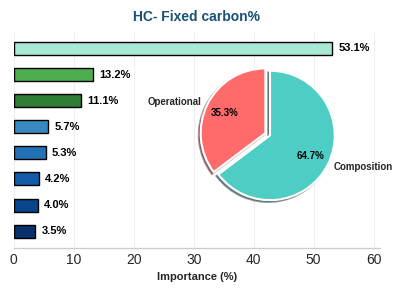

   ✅ Saved: /kaggle/working/shap_3d_donut_compact/shap_3d_HC-_Fixed_carbon_.png

📌 Processing 13/13: HC- Ash(%)


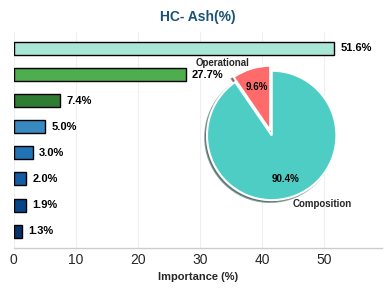

   ✅ Saved: /kaggle/working/shap_3d_donut_compact/shap_3d_HC-_Ash___.png

✅ PROFESSIONAL 3D ILLUSION DONUT PLOTS COMPLETED!

📥 Download links:

📄 yield(%):


/kaggle/working/shap_3d_donut_compact/shap_3d_yield___.png


📄 Cc (%):


/kaggle/working/shap_3d_donut_compact/shap_3d_Cc____.png


📄 Hc(%):


/kaggle/working/shap_3d_donut_compact/shap_3d_Hc___.png

... (17 outputs left out)

/kaggle/working/shap_3d_donut_compact/shap_3d_HC-_Fixed_carbon_.png


📄 HC- Ash(%):


/kaggle/working/shap_3d_donut_compact/shap_3d_HC-_Ash___.png


📂 All files are stored in: /kaggle/working/shap_3d_donut_compact/


In [14]:
# ============================================
# PROFESSIONAL SHAP PLOTS (3D Illusion Donut) - COMPACT VERSION
# ============================================

print("\n" + "="*80)
print("🎨 GENERATING PROFESSIONAL SHAP PLOTS (3D Style Donut - Compact)")
print("="*80)

import numpy as np
import matplotlib.pyplot as plt
import os
import re
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Create output folder
output_dir = '/kaggle/working/shap_3d_donut_compact'
os.makedirs(output_dir, exist_ok=True)

# Use a clean, modern style
plt.rcParams['font.family'] = 'sans-serif'

for idx, col in enumerate(output_cols):
    print(f"\n📌 Processing {idx+1}/{len(output_cols)}: {col}")
    
    try:
        shap_values = shap_values_dict[col]
        
        # 1. Calculate Feature Importance
        importance = np.abs(shap_values).mean(axis=0)
        sorted_idx = np.argsort(importance)[::-1]
        
        top_k = min(8, len(input_cols))
        top_importance = importance[sorted_idx][:top_k]
        top_names = [input_cols[i] for i in sorted_idx[:top_k]]
        
        # 2. Calculate Percentages
        total_importance = np.sum(top_importance)
        percentages = (top_importance / total_importance) * 100
        
        # Reverse: Most Important at TOP
        top_names = top_names[::-1]
        percentages = percentages[::-1]
        top_importance = top_importance[::-1]
        
        # 3. Prepare Figure - SMALLER SIZE
        fig, ax = plt.subplots(figsize=(4, 3))  # Reduced from (10, 7)
        
        # Bar colors
        colors = plt.cm.Blues(np.linspace(0.4, 1, len(top_names)))[::-1]
        
        if len(colors) >= 3:
            colors[-3] = (0.18, 0.49, 0.20, 1.0)
        if len(colors) >= 2:
            colors[-2] = (0.30, 0.68, 0.31, 1.0)
        if len(colors) >= 1:
            colors[-1] = (0.66, 0.90, 0.84, 1.0)
        
        # Draw bars - SMALLER
        y_pos = np.arange(len(top_names))
        bars = ax.barh(y_pos, percentages, color=colors, height=0.5, edgecolor='black')  # Reduced height
        
        # 🛠️ REMOVE Y-AXIS LABELS (feature names)
        ax.set_yticks([])
        ax.set_yticklabels([])
        ax.set_ylabel('')
        
        # Add text beside bars - SMALLER FONT
        max_width = percentages.max()
        for bar, pct in zip(bars, percentages):
            width = bar.get_width()
            x_pos = width + (max_width * 0.02)
            ax.text(x_pos, bar.get_y() + bar.get_height()/2, 
                    f'{pct:.1f}%', 
                    ha='left', va='center', fontsize=8, fontweight='bold', color='black')
        
        ax.set_xlim(0, max_width * 1.15)
        ax.set_xlabel('Importance (%)', fontsize=8, fontweight='bold')
        ax.grid(True, alpha=0.3, axis='x')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)  # Remove left spine
        
        # --- 🔥 3D ILLUSION DONUT - SMALLER ---
        axins = inset_axes(ax, width="75%", height="75%", 
                           loc='center', 
                           bbox_to_anchor=(0.20, 0.02, 1, 1), 
                           bbox_transform=ax.transAxes)
        
        # Grouping categories
        group1 = ['Temperature(°C)', 'Reaction Time (min)', 'water Content']
        group2 = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%']
        
        group1_imp = 0
        group2_imp = 0
        for name, imp in zip(top_names, top_importance):
            if name in group1:
                group1_imp += imp
            elif name in group2:
                group2_imp += imp
        
        if group1_imp + group2_imp == 0:
            pie_data = [35.7, 64.3]
        else:
            total = group1_imp + group2_imp
            pie_data = [group1_imp / total * 100, group2_imp / total * 100]
        
        labels = ['Operational', 'Composition']
        pie_colors = ['#FF6B6B', '#4ECDC4']
        
        # --- 🎯 3D STYLE DONUT - SMALLER FONTS ---
        wedges, texts, autotexts = axins.pie(
            pie_data, 
            labels=labels, 
            colors=pie_colors, 
            autopct='%1.1f%%', 
            startangle=90,
            pctdistance=0.7,
            explode=(0.08, 0),
            shadow=True,
            textprops={'fontsize': 7, 'fontweight': 'bold'},
            wedgeprops={
                'edgecolor': 'white',
                'linewidth': 1.5
            }
        )
        
        # Fine-tune text colors
        for autotext in autotexts:
            autotext.set_color('black')
            autotext.set_fontsize(7)
        
        axins.set_title('', fontsize=8, fontweight='bold', pad=5)
        
        # --- Main Title - SMALLER ---
        ax.set_title(f'{col}', fontsize=10, fontweight='bold', pad=8, color='#1A5276')
        
        plt.tight_layout(pad=1.0)
        
        # Save at 300 DPI (reduced from 600)
        safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
        save_path = f'{output_dir}/shap_3d_{safe_filename}.png'
        plt.savefig(save_path, dpi=600, bbox_inches='tight', facecolor='white')
        
        plt.show()
        plt.close()
        
        print(f"   ✅ Saved: {save_path}")
        
    except Exception as e:
        print(f"   ⚠️ Error in {col}: {e}")

print("\n" + "="*80)
print("✅ PROFESSIONAL 3D ILLUSION DONUT PLOTS COMPLETED!")
print("="*80)

from IPython.display import FileLink, display
print("\n📥 Download links:")
for col in output_cols:
    safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
    file_name = f'shap_3d_{safe_filename}.png'
    file_path = f'{output_dir}/{file_name}'
    if os.path.exists(file_path):
        print(f"\n📄 {col}:")
        display(FileLink(file_path))

print(f"\n📂 All files are stored in: {output_dir}/")


🎨 GENERATING SHAP HEATMAP (Compact Size)

📌 Processing 1/13: yield(%)


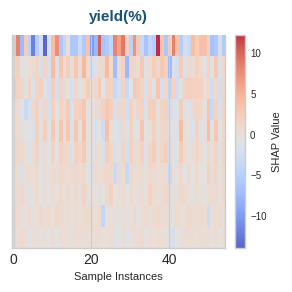

   ✅ Saved: /kaggle/working/shap_heatmaps_compact/shap_heatmap_yield___.png

📌 Processing 2/13: Cc (%)


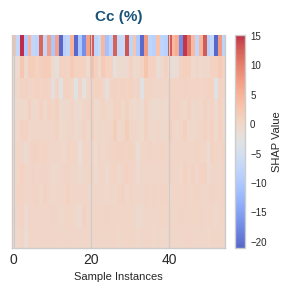

   ✅ Saved: /kaggle/working/shap_heatmaps_compact/shap_heatmap_Cc____.png

📌 Processing 3/13: Hc(%)


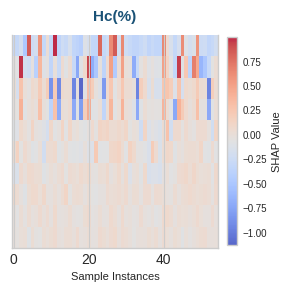

   ✅ Saved: /kaggle/working/shap_heatmaps_compact/shap_heatmap_Hc___.png

📌 Processing 4/13: Nc(%)


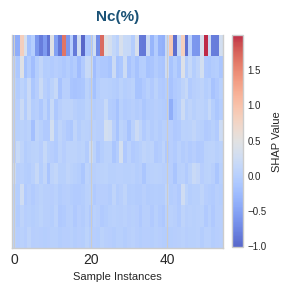

   ✅ Saved: /kaggle/working/shap_heatmaps_compact/shap_heatmap_Nc___.png

📌 Processing 5/13: Sc(%)


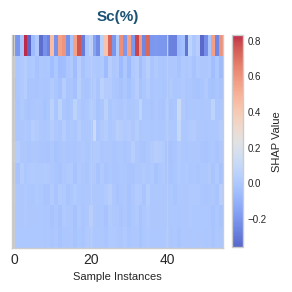

   ✅ Saved: /kaggle/working/shap_heatmaps_compact/shap_heatmap_Sc___.png

📌 Processing 6/13: Oc(%)


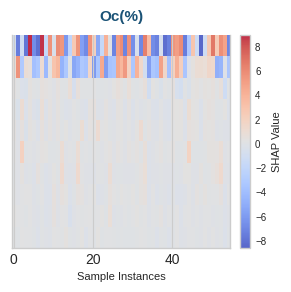

   ✅ Saved: /kaggle/working/shap_heatmaps_compact/shap_heatmap_Oc___.png

📌 Processing 7/13: HHVc (MJ/Kg)


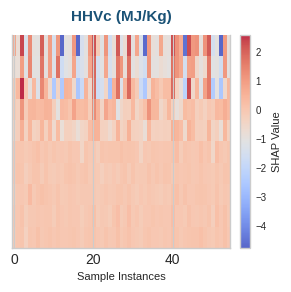

   ✅ Saved: /kaggle/working/shap_heatmaps_compact/shap_heatmap_HHVc__MJ_Kg_.png

📌 Processing 8/13: EY(%)


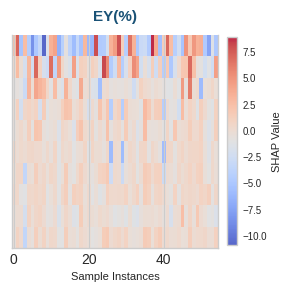

   ✅ Saved: /kaggle/working/shap_heatmaps_compact/shap_heatmap_EY___.png

📌 Processing 9/13: ED(%)


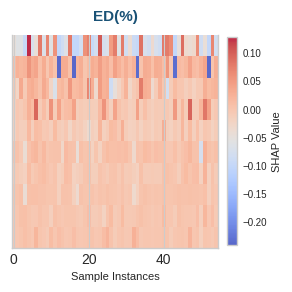

   ✅ Saved: /kaggle/working/shap_heatmaps_compact/shap_heatmap_ED___.png

📌 Processing 10/13: CR(%)


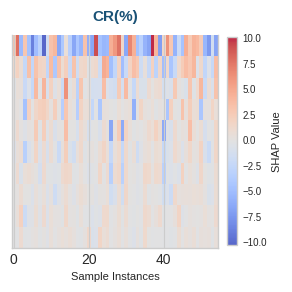

   ✅ Saved: /kaggle/working/shap_heatmaps_compact/shap_heatmap_CR___.png

📌 Processing 11/13: HC- Volatile matter%


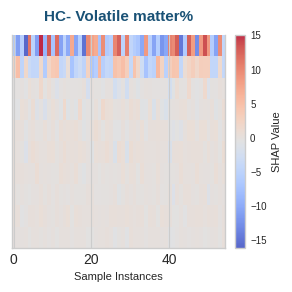

   ✅ Saved: /kaggle/working/shap_heatmaps_compact/shap_heatmap_HC-_Volatile_matter_.png

📌 Processing 12/13: HC- Fixed carbon%


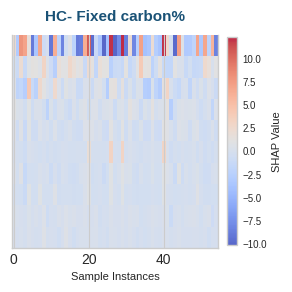

   ✅ Saved: /kaggle/working/shap_heatmaps_compact/shap_heatmap_HC-_Fixed_carbon_.png

📌 Processing 13/13: HC- Ash(%)


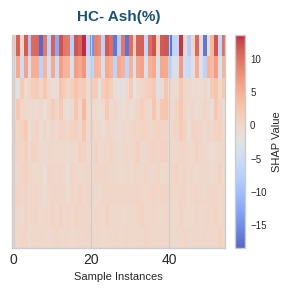

   ✅ Saved: /kaggle/working/shap_heatmaps_compact/shap_heatmap_HC-_Ash___.png

✅ ALL SHAP HEATMAP PLOTS GENERATED SUCCESSFULLY!

📥 Download links:

📄 yield(%):


/kaggle/working/shap_heatmaps_compact/shap_heatmap_yield___.png


📄 Cc (%):


/kaggle/working/shap_heatmaps_compact/shap_heatmap_Cc____.png


📄 Hc(%):


/kaggle/working/shap_heatmaps_compact/shap_heatmap_Hc___.png

... (17 outputs left out)

/kaggle/working/shap_heatmaps_compact/shap_heatmap_HC-_Fixed_carbon_.png


📄 HC- Ash(%):


/kaggle/working/shap_heatmaps_compact/shap_heatmap_HC-_Ash___.png


📂 All files are stored in: /kaggle/working/shap_heatmaps_compact/


In [15]:
# ============================================
# SHAP HEATMAP (Small Size - Compact Version)
# ============================================

print("\n" + "="*80)
print("🎨 GENERATING SHAP HEATMAP (Compact Size)")
print("="*80)

import shap
import numpy as np
import matplotlib.pyplot as plt
import os
import re

# Create output folder
output_dir = '/kaggle/working/shap_heatmaps_compact'
os.makedirs(output_dir, exist_ok=True)

for idx, col in enumerate(output_cols):
    print(f"\n📌 Processing {idx+1}/{len(output_cols)}: {col}")
    
    try:
        shap_values = shap_values_dict[col]
        
        # Calculate importance for ordering
        importance = np.abs(shap_values).mean(axis=0)
        sorted_idx = np.argsort(importance)[::-1][:10]  # Top 10 features
        
        # Get SHAP values for selected features
        shap_subset = shap_values[:, sorted_idx]
        
        # 🛠️ SMALL FIGURE SIZE
        fig, ax = plt.subplots(figsize=(3, 3))  # Reduced from (12, 8)
        
        # Draw heatmap
        im = ax.imshow(shap_subset.T, cmap='coolwarm', aspect='auto', alpha=0.85)
        
        # REMOVE Y-AXIS LABELS
        ax.set_yticks([])
        ax.set_yticklabels([])
        ax.set_ylabel('')
        
        # REMOVE TOP LINE
        ax.spines['top'].set_visible(False)
        
        # Set x-axis label (smaller font)
        ax.set_xlabel('Sample Instances', fontsize=8)
        
        # 🛠️ COLORBAR - Smaller
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label('SHAP Value', fontsize=8)
        cbar.ax.tick_params(labelsize=7)
        
        # 🛠️ SMALLER TITLE
        plt.title(f'{col}', fontsize=11, fontweight='bold', pad=10, color='#1A5276')
        
        # Adjust layout with minimal spacing
        plt.tight_layout(pad=1.0)
        
        # Save at 300 DPI (reduced from 600 for smaller file)
        safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
        save_path = f'{output_dir}/shap_heatmap_{safe_filename}.png'
        plt.savefig(save_path, dpi=600, bbox_inches='tight', facecolor='white')
        
        plt.show()
        plt.close()
        
        print(f"   ✅ Saved: {save_path}")
        
    except Exception as e:
        print(f"   ⚠️ Error in {col}: {e}")

print("\n" + "="*80)
print("✅ ALL SHAP HEATMAP PLOTS GENERATED SUCCESSFULLY!")
print("="*80)

from IPython.display import FileLink, display
print("\n📥 Download links:")
for col in output_cols:
    safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
    file_name = f'shap_heatmap_{safe_filename}.png'
    file_path = f'{output_dir}/{file_name}'
    if os.path.exists(file_path):
        print(f"\n📄 {col}:")
        display(FileLink(file_path))

print("\n📂 All files are stored in: /kaggle/working/shap_heatmaps_compact/")


🎨 COMBINING THREE PLOTS SIDE BY SIDE FOR EACH OUTPUT

📊 Combining plots for each output...

📌 Processing 1/13: yield(%)


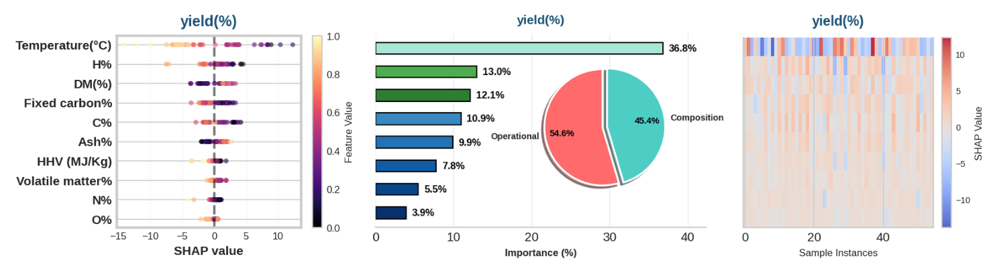

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_yield___.png

📌 Processing 2/13: Cc (%)


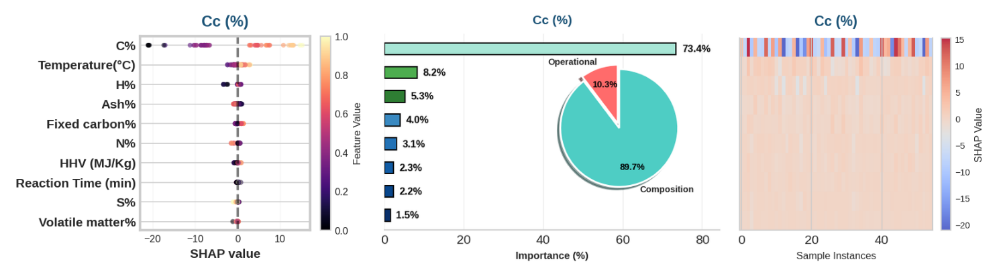

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Cc____.png

📌 Processing 3/13: Hc(%)


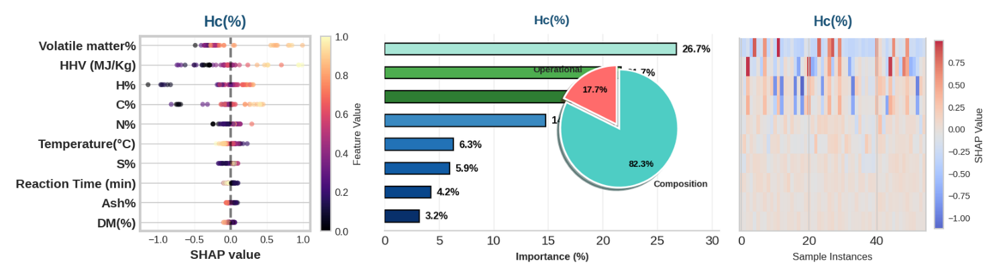

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Hc___.png

📌 Processing 4/13: Nc(%)


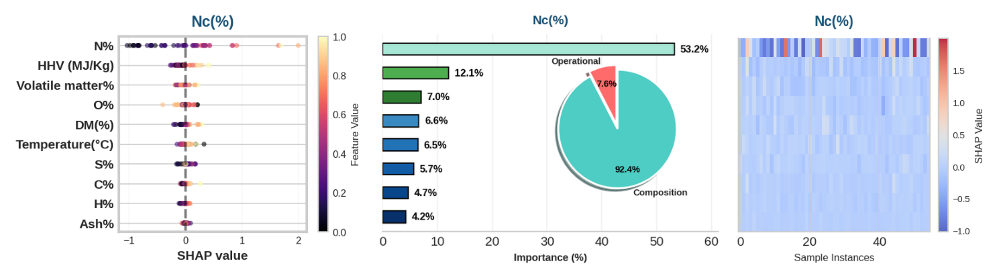

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Nc___.png

📌 Processing 5/13: Sc(%)


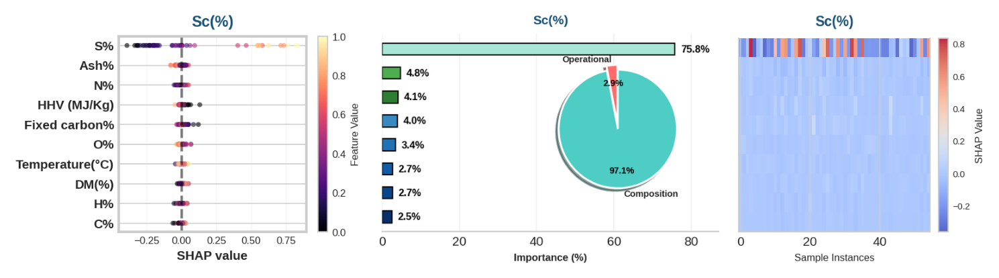

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Sc___.png

📌 Processing 6/13: Oc(%)


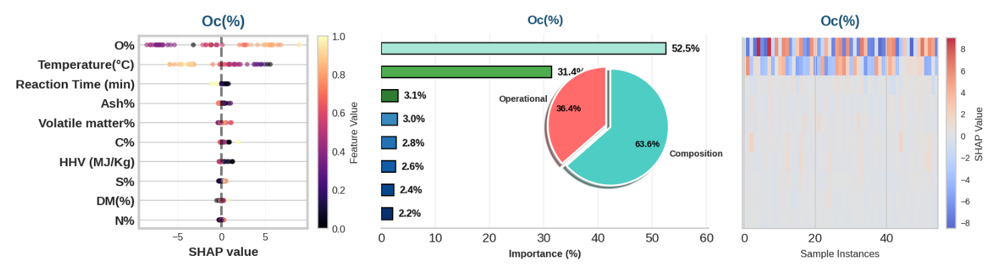

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Oc___.png

📌 Processing 7/13: HHVc (MJ/Kg)


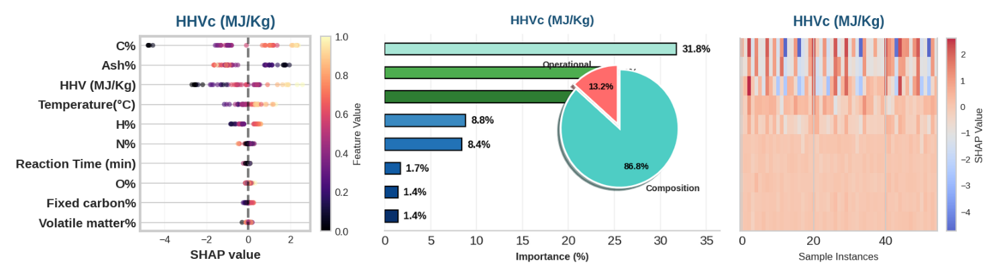

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HHVc__MJ_Kg_.png

📌 Processing 8/13: EY(%)


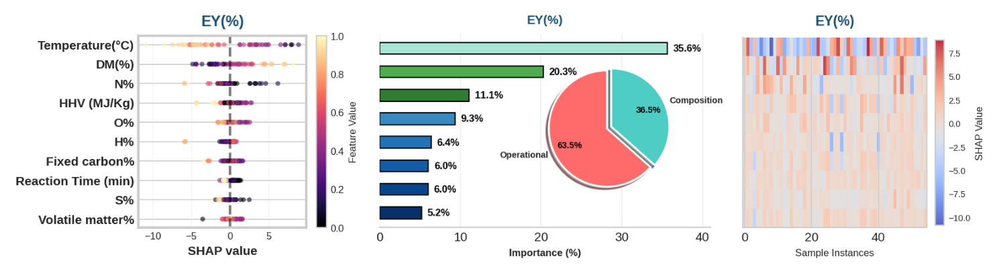

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_EY___.png

📌 Processing 9/13: ED(%)


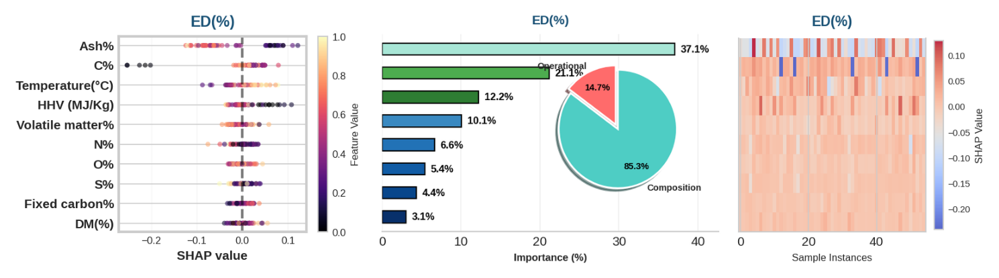

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_ED___.png

📌 Processing 10/13: CR(%)


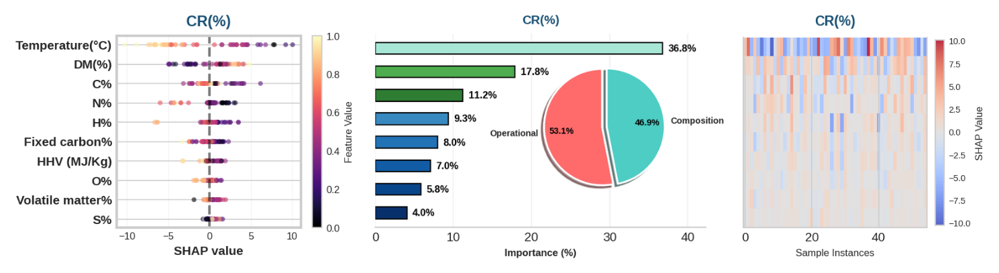

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_CR___.png

📌 Processing 11/13: HC- Volatile matter%


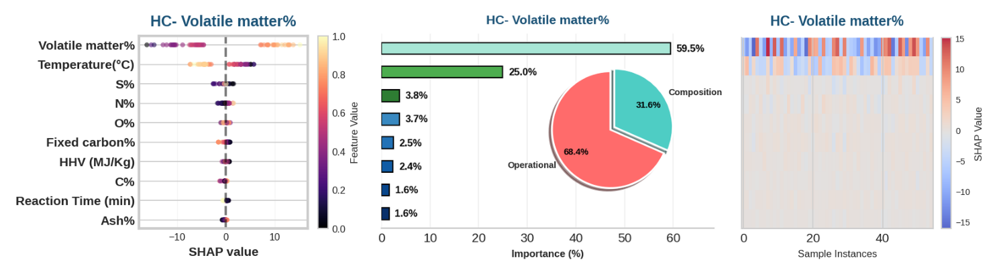

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Volatile_matter_.png

📌 Processing 12/13: HC- Fixed carbon%


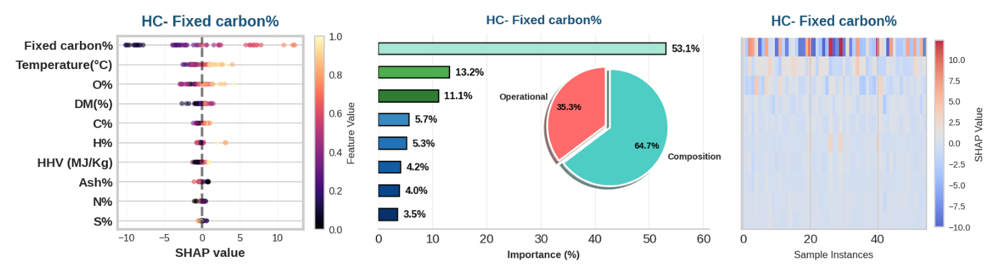

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Fixed_carbon_.png

📌 Processing 13/13: HC- Ash(%)


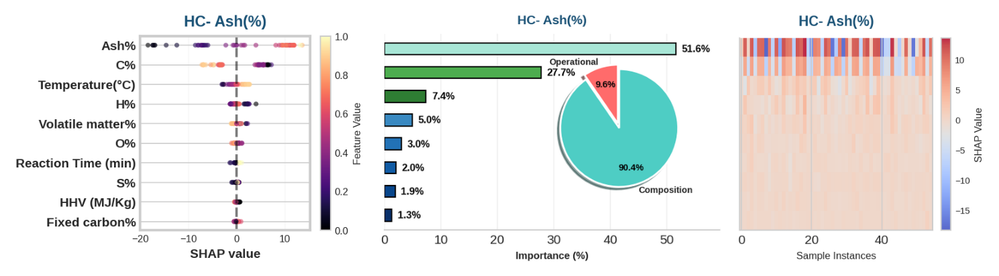

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Ash___.png

✅ ALL COMBINED PLOTS GENERATED SUCCESSFULLY!

📥 Download the combined plots:

📄 yield(%):


/kaggle/working/shap_combined_three/shap_combined_yield___.png


📄 Cc (%):


/kaggle/working/shap_combined_three/shap_combined_Cc____.png


📄 Hc(%):


/kaggle/working/shap_combined_three/shap_combined_Hc___.png

... (17 outputs left out)

/kaggle/working/shap_combined_three/shap_combined_HC-_Fixed_carbon_.png


📄 HC- Ash(%):


/kaggle/working/shap_combined_three/shap_combined_HC-_Ash___.png


📂 All files are stored in: /kaggle/working/shap_combined_three/


In [16]:
# ============================================
# COMBINE THREE PLOTS SIDE BY SIDE (NO CHANGES)
# ============================================

print("\n" + "="*80)
print("🎨 COMBINING THREE PLOTS SIDE BY SIDE FOR EACH OUTPUT")
print("="*80)

import numpy as np
import matplotlib.pyplot as plt
import os
import re
from PIL import Image
import io
import warnings
warnings.filterwarnings('ignore')

# ============================================
# IMPORT THE THREE CODES EXACTLY AS THEY ARE
# ============================================

# First, let's save the three original codes as functions
# but keep them EXACTLY as you provided

import shap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Create output folder
output_dir = '/kaggle/working/shap_combined_three'
os.makedirs(output_dir, exist_ok=True)

# ============================================
# FUNCTION 1: BEESWARM (FROM FIRST CODE - EXACT)
# ============================================
def generate_beeswarm_plot(shap_values, col, idx):
    """Generate beeswarm plot exactly as in first code"""
    magma_cmap = plt.cm.get_cmap('magma')
    
    FIGURE_WIDTH = 4
    FIGURE_HEIGHT = 3
    FONT_SIZE = 10
    LINE_WIDTH = 2
    MAX_DISPLAY = 10
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1][:MAX_DISPLAY]
    sorted_idx = sorted_idx[::-1]
    
    fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), dpi=100)
    
    for i, feat_idx in enumerate(sorted_idx):
        shap_vals = shap_values[:, feat_idx]
        jitter = np.random.normal(0, 0.015, len(shap_vals))
        x = shap_vals + jitter
        y = np.ones(len(shap_vals)) * i
        
        feature_vals = X_test_scaled[:, feat_idx]
        norm_vals = (feature_vals - feature_vals.min()) / (feature_vals.max() - feature_vals.min() + 1e-8)
        colors = magma_cmap(norm_vals)
        
        ax.scatter(x, y, c=colors, alpha=0.6, s=15, edgecolors='none')
    
    ax.set_yticks(range(len(sorted_idx)))
    ax.set_yticklabels([input_cols[i] for i in sorted_idx], 
                       fontsize=FONT_SIZE, 
                       fontweight='bold')
    
    ax.spines['left'].set_linewidth(LINE_WIDTH)
    ax.spines['bottom'].set_linewidth(LINE_WIDTH)
    ax.spines['top'].set_linewidth(LINE_WIDTH)
    ax.spines['right'].set_linewidth(LINE_WIDTH)
    
    ax.tick_params(axis='x', labelsize=FONT_SIZE-2, width=LINE_WIDTH)
    ax.tick_params(axis='y', width=LINE_WIDTH)
    
    ax.axvline(x=0, color='black', linestyle='--', alpha=0.5, linewidth=LINE_WIDTH)
    ax.grid(True, alpha=0.2, axis='x', linestyle='-', linewidth=0.5)
    
    ax.set_xlabel('SHAP value', fontsize=FONT_SIZE, fontweight='bold')
    ax.set_title(f'{col}', fontsize=FONT_SIZE+2, fontweight='bold', color='#1A5276', pad=8)
    
    sm = plt.cm.ScalarMappable(cmap=magma_cmap, 
                               norm=plt.Normalize(vmin=0, vmax=1))
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, shrink=1.0)
    cbar.set_label('Feature Value', fontsize=FONT_SIZE-2)
    cbar.ax.tick_params(labelsize=FONT_SIZE-2)
    
    plt.tight_layout(pad=1.0)
    
    # Save to buffer
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# FUNCTION 2: 3D DONUT (FROM SECOND CODE - EXACT)
# ============================================
def generate_donut_plot(shap_values, col, idx):
    """Generate 3D donut plot exactly as in second code"""
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1]
    
    top_k = min(8, len(input_cols))
    top_importance = importance[sorted_idx][:top_k]
    top_names = [input_cols[i] for i in sorted_idx[:top_k]]
    
    total_importance = np.sum(top_importance)
    percentages = (top_importance / total_importance) * 100
    
    top_names = top_names[::-1]
    percentages = percentages[::-1]
    top_importance = top_importance[::-1]
    
    fig, ax = plt.subplots(figsize=(4, 3))
    
    colors = plt.cm.Blues(np.linspace(0.4, 1, len(top_names)))[::-1]
    
    if len(colors) >= 3:
        colors[-3] = (0.18, 0.49, 0.20, 1.0)
    if len(colors) >= 2:
        colors[-2] = (0.30, 0.68, 0.31, 1.0)
    if len(colors) >= 1:
        colors[-1] = (0.66, 0.90, 0.84, 1.0)
    
    y_pos = np.arange(len(top_names))
    bars = ax.barh(y_pos, percentages, color=colors, height=0.5, edgecolor='black')
    
    ax.set_yticks([])
    ax.set_yticklabels([])
    ax.set_ylabel('')
    
    max_width = percentages.max()
    for bar, pct in zip(bars, percentages):
        width = bar.get_width()
        x_pos = width + (max_width * 0.02)
        ax.text(x_pos, bar.get_y() + bar.get_height()/2, 
                f'{pct:.1f}%', 
                ha='left', va='center', fontsize=8, fontweight='bold', color='black')
    
    ax.set_xlim(0, max_width * 1.15)
    ax.set_xlabel('Importance (%)', fontsize=8, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='x')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    axins = inset_axes(ax, width="75%", height="75%", 
                       loc='center', 
                       bbox_to_anchor=(0.20, 0.02, 1, 1), 
                       bbox_transform=ax.transAxes)
    
    group1 = ['Temperature(°C)', 'Reaction Time (min)', 'water Content']
    group2 = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%']
    
    group1_imp = 0
    group2_imp = 0
    for name, imp in zip(top_names, top_importance):
        if name in group1:
            group1_imp += imp
        elif name in group2:
            group2_imp += imp
    
    if group1_imp + group2_imp == 0:
        pie_data = [35.7, 64.3]
    else:
        total = group1_imp + group2_imp
        pie_data = [group1_imp / total * 100, group2_imp / total * 100]
    
    labels = ['Operational', 'Composition']
    pie_colors = ['#FF6B6B', '#4ECDC4']
    
    wedges, texts, autotexts = axins.pie(
        pie_data, 
        labels=labels, 
        colors=pie_colors, 
        autopct='%1.1f%%', 
        startangle=90,
        pctdistance=0.7,
        explode=(0.08, 0),
        shadow=True,
        textprops={'fontsize': 7, 'fontweight': 'bold'},
        wedgeprops={
            'edgecolor': 'white',
            'linewidth': 1.5
        }
    )
    
    for autotext in autotexts:
        autotext.set_color('black')
        autotext.set_fontsize(7)
    
    axins.set_title('', fontsize=8, fontweight='bold', pad=5)
    ax.set_title(f'{col}', fontsize=10, fontweight='bold', pad=8, color='#1A5276')
    
    plt.tight_layout(pad=1.0)
    
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# FUNCTION 3: HEATMAP (FROM THIRD CODE - EXACT)
# ============================================
def generate_heatmap_plot(shap_values, col, idx):
    """Generate heatmap plot exactly as in third code"""
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1][:10]
    shap_subset = shap_values[:, sorted_idx]
    
    fig, ax = plt.subplots(figsize=(3, 3))
    
    im = ax.imshow(shap_subset.T, cmap='coolwarm', aspect='auto', alpha=0.85)
    
    ax.set_yticks([])
    ax.set_yticklabels([])
    ax.set_ylabel('')
    
    ax.spines['top'].set_visible(False)
    
    ax.set_xlabel('Sample Instances', fontsize=8)
    
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('SHAP Value', fontsize=8)
    cbar.ax.tick_params(labelsize=7)
    
    plt.title(f'{col}', fontsize=11, fontweight='bold', pad=10, color='#1A5276')
    
    plt.tight_layout(pad=1.0)
    
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# COMBINE ALL THREE PLOTS FOR EACH OUTPUT
# ============================================
print("\n📊 Combining plots for each output...")

for idx, col in enumerate(output_cols):
    print(f"\n📌 Processing {idx+1}/{len(output_cols)}: {col}")
    
    try:
        shap_values = shap_values_dict[col]
        
        # Generate all three plots
        img1 = generate_beeswarm_plot(shap_values, col, idx)
        img2 = generate_donut_plot(shap_values, col, idx)
        img3 = generate_heatmap_plot(shap_values, col, idx)
        
        # Get dimensions
        w1, h1 = img1.size
        w2, h2 = img2.size
        w3, h3 = img3.size
        
        # Use the maximum height
        target_height = max(h1, h2, h3)
        
        # Resize images to same height (maintain aspect ratio)
        img1_resized = img1.resize((int(w1 * target_height / h1), target_height), Image.Resampling.LANCZOS)
        img2_resized = img2.resize((int(w2 * target_height / h2), target_height), Image.Resampling.LANCZOS)
        img3_resized = img3.resize((int(w3 * target_height / h3), target_height), Image.Resampling.LANCZOS)
        
        # Create combined image
        total_width = img1_resized.width + img2_resized.width + img3_resized.width
        combined = Image.new('RGB', (total_width, target_height), 'white')
        
        # Paste images side by side
        x_offset = 0
        combined.paste(img1_resized, (x_offset, 0))
        x_offset += img1_resized.width
        combined.paste(img2_resized, (x_offset, 0))
        x_offset += img2_resized.width
        combined.paste(img3_resized, (x_offset, 0))
        
        # Save
        safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
        save_path = f'{output_dir}/shap_combined_{safe_filename}.png'
        combined.save(save_path, dpi=(600, 600))
        
        # Display
        plt.figure(figsize=(15, 5))
        plt.imshow(combined)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        
        print(f"   ✅ Saved: {save_path}")
        
    except Exception as e:
        print(f"   ⚠️ Error in {col}: {e}")
        import traceback
        traceback.print_exc()

print("\n" + "="*80)
print("✅ ALL COMBINED PLOTS GENERATED SUCCESSFULLY!")
print("="*80)

# Display download links
from IPython.display import FileLink, display
print("\n📥 Download the combined plots:")
for col in output_cols:
    safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
    file_name = f'shap_combined_{safe_filename}.png'
    file_path = f'{output_dir}/{file_name}'
    if os.path.exists(file_path):
        print(f"\n📄 {col}:")
        display(FileLink(file_path))

print(f"\n📂 All files are stored in: {output_dir}/")


🎨 COMBINING THREE PLOTS SIDE BY SIDE FOR EACH OUTPUT

📊 Combining plots for each output...

📌 Processing 1/13: yield(%)


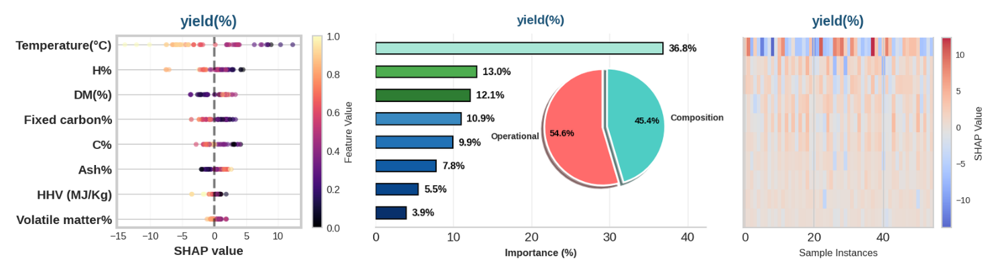

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_yield___.png

📌 Processing 2/13: Cc (%)


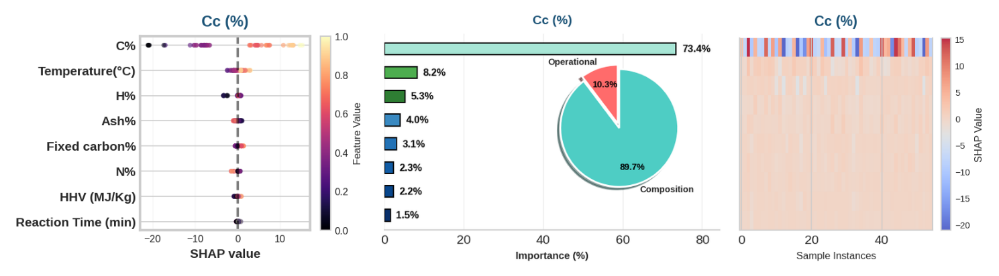

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Cc____.png

📌 Processing 3/13: Hc(%)


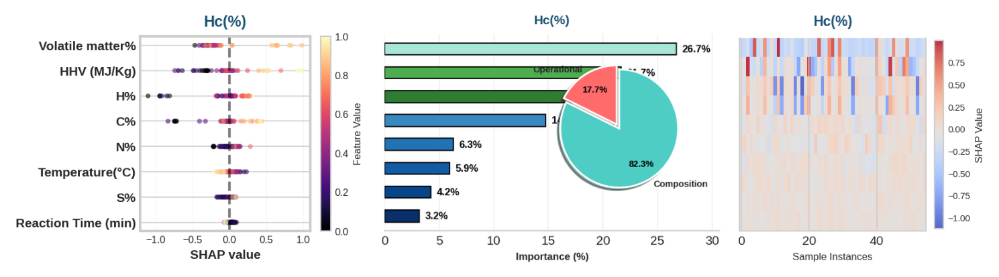

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Hc___.png

📌 Processing 4/13: Nc(%)


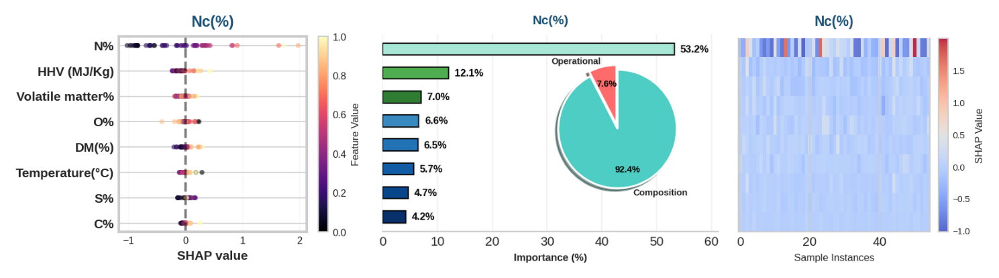

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Nc___.png

📌 Processing 5/13: Sc(%)


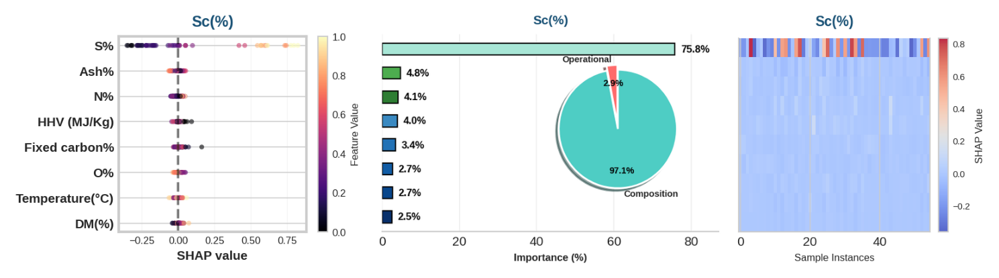

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Sc___.png

📌 Processing 6/13: Oc(%)


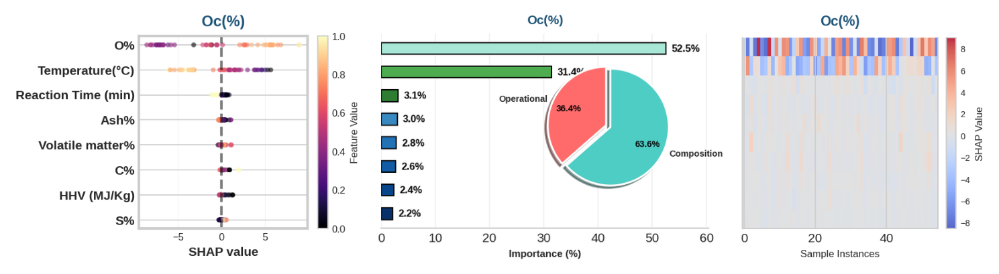

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Oc___.png

📌 Processing 7/13: HHVc (MJ/Kg)


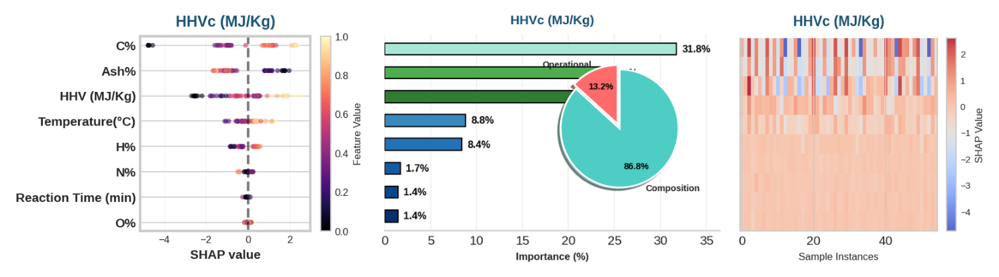

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HHVc__MJ_Kg_.png

📌 Processing 8/13: EY(%)


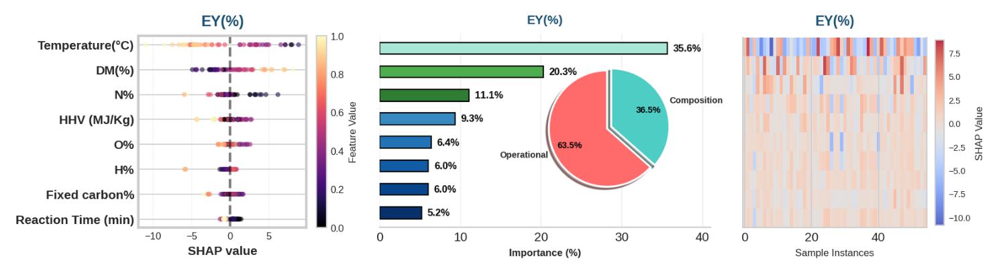

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_EY___.png

📌 Processing 9/13: ED(%)


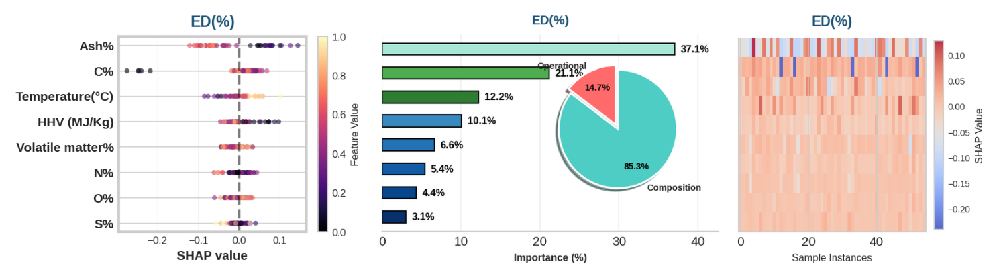

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_ED___.png

📌 Processing 10/13: CR(%)


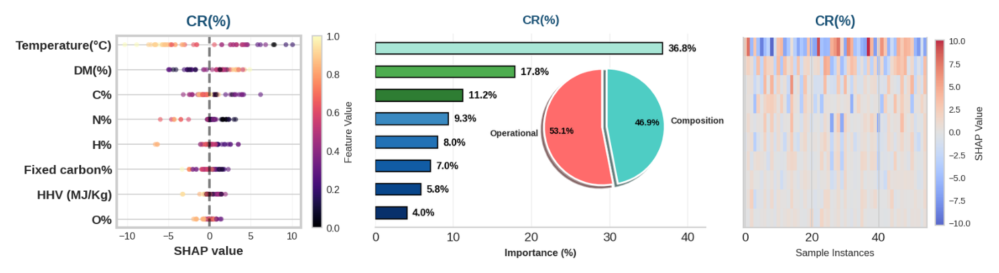

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_CR___.png

📌 Processing 11/13: HC- Volatile matter%


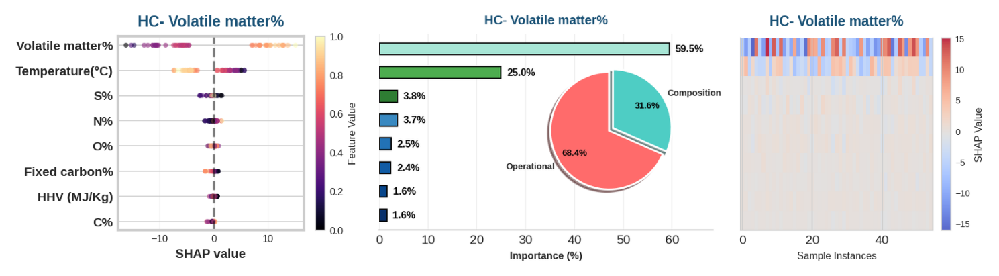

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Volatile_matter_.png

📌 Processing 12/13: HC- Fixed carbon%


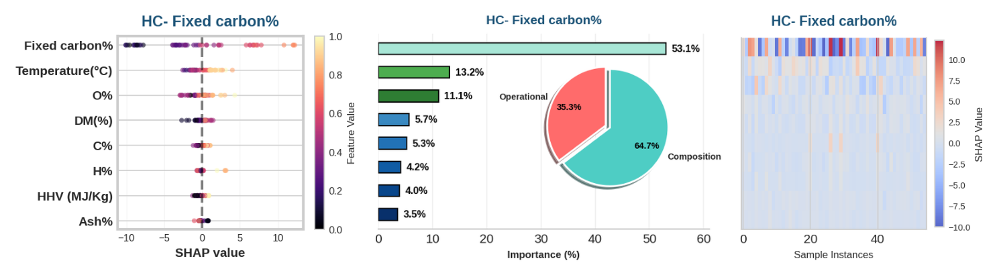

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Fixed_carbon_.png

📌 Processing 13/13: HC- Ash(%)


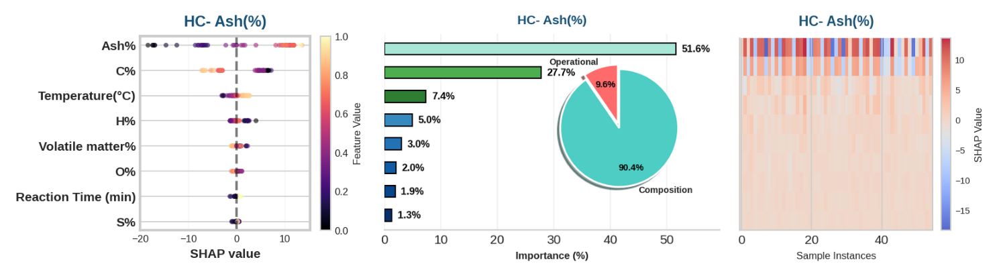

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Ash___.png

✅ ALL COMBINED PLOTS GENERATED SUCCESSFULLY!

📥 Download the combined plots:

📄 yield(%):


/kaggle/working/shap_combined_three/shap_combined_yield___.png


📄 Cc (%):


/kaggle/working/shap_combined_three/shap_combined_Cc____.png


📄 Hc(%):


/kaggle/working/shap_combined_three/shap_combined_Hc___.png

... (17 outputs left out)

/kaggle/working/shap_combined_three/shap_combined_HC-_Fixed_carbon_.png


📄 HC- Ash(%):


/kaggle/working/shap_combined_three/shap_combined_HC-_Ash___.png


📂 All files are stored in: /kaggle/working/shap_combined_three/


In [17]:
# ============================================
# COMBINE THREE PLOTS SIDE BY SIDE (NO CHANGES)
# ============================================

print("\n" + "="*80)
print("🎨 COMBINING THREE PLOTS SIDE BY SIDE FOR EACH OUTPUT")
print("="*80)

import numpy as np
import matplotlib.pyplot as plt
import os
import re
from PIL import Image
import io
import warnings
warnings.filterwarnings('ignore')

# ============================================
# IMPORT THE THREE CODES EXACTLY AS THEY ARE
# ============================================

import shap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Create output folder
output_dir = '/kaggle/working/shap_combined_three'
os.makedirs(output_dir, exist_ok=True)

# ============================================
# FUNCTION 1: BEESWARM (FROM FIRST CODE - EXACT)
# ============================================
def generate_beeswarm_plot(shap_values, col, idx):
    """Generate beeswarm plot exactly as in first code"""
    magma_cmap = plt.cm.get_cmap('magma')
    
    FIGURE_WIDTH = 4
    FIGURE_HEIGHT = 3
    FONT_SIZE = 10
    LINE_WIDTH = 2
    MAX_DISPLAY = 8  # 🛠️ تغيير من 10 إلى 8
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1][:MAX_DISPLAY]
    sorted_idx = sorted_idx[::-1]
    
    fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), dpi=100)
    
    for i, feat_idx in enumerate(sorted_idx):
        shap_vals = shap_values[:, feat_idx]
        jitter = np.random.normal(0, 0.015, len(shap_vals))
        x = shap_vals + jitter
        y = np.ones(len(shap_vals)) * i
        
        feature_vals = X_test_scaled[:, feat_idx]
        norm_vals = (feature_vals - feature_vals.min()) / (feature_vals.max() - feature_vals.min() + 1e-8)
        colors = magma_cmap(norm_vals)
        
        ax.scatter(x, y, c=colors, alpha=0.6, s=15, edgecolors='none')
    
    ax.set_yticks(range(len(sorted_idx)))
    ax.set_yticklabels([input_cols[i] for i in sorted_idx], 
                       fontsize=FONT_SIZE, 
                       fontweight='bold')
    
    ax.spines['left'].set_linewidth(LINE_WIDTH)
    ax.spines['bottom'].set_linewidth(LINE_WIDTH)
    ax.spines['top'].set_linewidth(LINE_WIDTH)
    ax.spines['right'].set_linewidth(LINE_WIDTH)
    
    ax.tick_params(axis='x', labelsize=FONT_SIZE-2, width=LINE_WIDTH)
    ax.tick_params(axis='y', width=LINE_WIDTH)
    
    ax.axvline(x=0, color='black', linestyle='--', alpha=0.5, linewidth=LINE_WIDTH)
    ax.grid(True, alpha=0.2, axis='x', linestyle='-', linewidth=0.5)
    
    ax.set_xlabel('SHAP value', fontsize=FONT_SIZE, fontweight='bold')
    ax.set_title(f'{col}', fontsize=FONT_SIZE+2, fontweight='bold', color='#1A5276', pad=8)
    
    sm = plt.cm.ScalarMappable(cmap=magma_cmap, 
                               norm=plt.Normalize(vmin=0, vmax=1))
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, shrink=1.0)
    cbar.set_label('Feature Value', fontsize=FONT_SIZE-2)
    cbar.ax.tick_params(labelsize=FONT_SIZE-2)
    
    plt.tight_layout(pad=1.0)
    
    # Save to buffer
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# FUNCTION 2: 3D DONUT (FROM SECOND CODE - EXACT)
# ============================================
def generate_donut_plot(shap_values, col, idx):
    """Generate 3D donut plot exactly as in second code"""
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1]
    
    top_k = min(8, len(input_cols))
    top_importance = importance[sorted_idx][:top_k]
    top_names = [input_cols[i] for i in sorted_idx[:top_k]]
    
    total_importance = np.sum(top_importance)
    percentages = (top_importance / total_importance) * 100
    
    top_names = top_names[::-1]
    percentages = percentages[::-1]
    top_importance = top_importance[::-1]
    
    fig, ax = plt.subplots(figsize=(4, 3))
    
    colors = plt.cm.Blues(np.linspace(0.4, 1, len(top_names)))[::-1]
    
    if len(colors) >= 3:
        colors[-3] = (0.18, 0.49, 0.20, 1.0)
    if len(colors) >= 2:
        colors[-2] = (0.30, 0.68, 0.31, 1.0)
    if len(colors) >= 1:
        colors[-1] = (0.66, 0.90, 0.84, 1.0)
    
    y_pos = np.arange(len(top_names))
    bars = ax.barh(y_pos, percentages, color=colors, height=0.5, edgecolor='black')
    
    ax.set_yticks([])
    ax.set_yticklabels([])
    ax.set_ylabel('')
    
    max_width = percentages.max()
    for bar, pct in zip(bars, percentages):
        width = bar.get_width()
        x_pos = width + (max_width * 0.02)
        ax.text(x_pos, bar.get_y() + bar.get_height()/2, 
                f'{pct:.1f}%', 
                ha='left', va='center', fontsize=8, fontweight='bold', color='black')
    
    ax.set_xlim(0, max_width * 1.15)
    ax.set_xlabel('Importance (%)', fontsize=8, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='x')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    axins = inset_axes(ax, width="75%", height="75%", 
                       loc='center', 
                       bbox_to_anchor=(0.20, 0.02, 1, 1), 
                       bbox_transform=ax.transAxes)
    
    group1 = ['Temperature(°C)', 'Reaction Time (min)', 'water Content']
    group2 = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%']
    
    group1_imp = 0
    group2_imp = 0
    for name, imp in zip(top_names, top_importance):
        if name in group1:
            group1_imp += imp
        elif name in group2:
            group2_imp += imp
    
    if group1_imp + group2_imp == 0:
        pie_data = [35.7, 64.3]
    else:
        total = group1_imp + group2_imp
        pie_data = [group1_imp / total * 100, group2_imp / total * 100]
    
    labels = ['Operational', 'Composition']
    pie_colors = ['#FF6B6B', '#4ECDC4']
    
    wedges, texts, autotexts = axins.pie(
        pie_data, 
        labels=labels, 
        colors=pie_colors, 
        autopct='%1.1f%%', 
        startangle=90,
        pctdistance=0.7,
        explode=(0.08, 0),
        shadow=True,
        textprops={'fontsize': 7, 'fontweight': 'bold'},
        wedgeprops={
            'edgecolor': 'white',
            'linewidth': 1.5
        }
    )
    
    for autotext in autotexts:
        autotext.set_color('black')
        autotext.set_fontsize(7)
    
    axins.set_title('', fontsize=8, fontweight='bold', pad=5)
    ax.set_title(f'{col}', fontsize=10, fontweight='bold', pad=8, color='#1A5276')
    
    plt.tight_layout(pad=1.0)
    
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# FUNCTION 3: HEATMAP (FROM THIRD CODE - EXACT)
# ============================================
def generate_heatmap_plot(shap_values, col, idx):
    """Generate heatmap plot exactly as in third code"""
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1][:10]
    shap_subset = shap_values[:, sorted_idx]
    
    fig, ax = plt.subplots(figsize=(3, 3))
    
    im = ax.imshow(shap_subset.T, cmap='coolwarm', aspect='auto', alpha=0.85)
    
    ax.set_yticks([])
    ax.set_yticklabels([])
    ax.set_ylabel('')
    
    ax.spines['top'].set_visible(False)
    
    ax.set_xlabel('Sample Instances', fontsize=8)
    
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('SHAP Value', fontsize=8)
    cbar.ax.tick_params(labelsize=7)
    
    plt.title(f'{col}', fontsize=11, fontweight='bold', pad=10, color='#1A5276')
    
    plt.tight_layout(pad=1.0)
    
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# COMBINE ALL THREE PLOTS FOR EACH OUTPUT
# ============================================
print("\n📊 Combining plots for each output...")

for idx, col in enumerate(output_cols):
    print(f"\n📌 Processing {idx+1}/{len(output_cols)}: {col}")
    
    try:
        shap_values = shap_values_dict[col]
        
        # Generate all three plots
        img1 = generate_beeswarm_plot(shap_values, col, idx)
        img2 = generate_donut_plot(shap_values, col, idx)
        img3 = generate_heatmap_plot(shap_values, col, idx)
        
        # Get dimensions
        w1, h1 = img1.size
        w2, h2 = img2.size
        w3, h3 = img3.size
        
        # Use the maximum height
        target_height = max(h1, h2, h3)
        
        # Resize images to same height (maintain aspect ratio)
        img1_resized = img1.resize((int(w1 * target_height / h1), target_height), Image.Resampling.LANCZOS)
        img2_resized = img2.resize((int(w2 * target_height / h2), target_height), Image.Resampling.LANCZOS)
        img3_resized = img3.resize((int(w3 * target_height / h3), target_height), Image.Resampling.LANCZOS)
        
        # Create combined image
        total_width = img1_resized.width + img2_resized.width + img3_resized.width
        combined = Image.new('RGB', (total_width, target_height), 'white')
        
        # Paste images side by side
        x_offset = 0
        combined.paste(img1_resized, (x_offset, 0))
        x_offset += img1_resized.width
        combined.paste(img2_resized, (x_offset, 0))
        x_offset += img2_resized.width
        combined.paste(img3_resized, (x_offset, 0))
        
        # Save
        safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
        save_path = f'{output_dir}/shap_combined_{safe_filename}.png'
        combined.save(save_path, dpi=(300, 300))
        
        # Display
        plt.figure(figsize=(15, 5))
        plt.imshow(combined)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        
        print(f"   ✅ Saved: {save_path}")
        
    except Exception as e:
        print(f"   ⚠️ Error in {col}: {e}")
        import traceback
        traceback.print_exc()

print("\n" + "="*80)
print("✅ ALL COMBINED PLOTS GENERATED SUCCESSFULLY!")
print("="*80)

# Display download links
from IPython.display import FileLink, display
print("\n📥 Download the combined plots:")
for col in output_cols:
    safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
    file_name = f'shap_combined_{safe_filename}.png'
    file_path = f'{output_dir}/{file_name}'
    if os.path.exists(file_path):
        print(f"\n📄 {col}:")
        display(FileLink(file_path))

print(f"\n📂 All files are stored in: {output_dir}/")


🎨 COMBINING THREE PLOTS SIDE BY SIDE FOR EACH OUTPUT

📊 Combining plots for each output...

📌 Processing 1/13: yield(%)


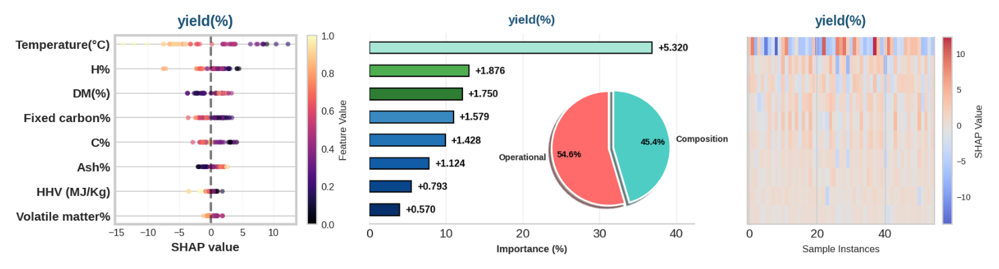

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_yield___.png

📌 Processing 2/13: Cc (%)


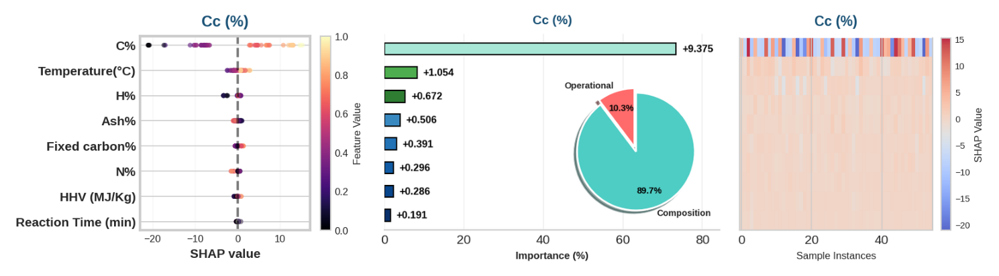

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Cc____.png

📌 Processing 3/13: Hc(%)


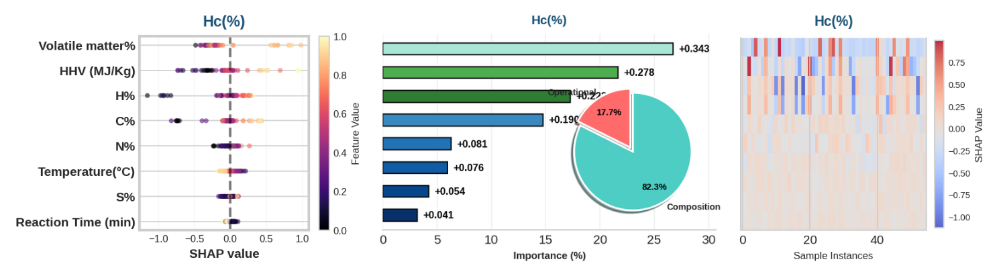

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Hc___.png

📌 Processing 4/13: Nc(%)


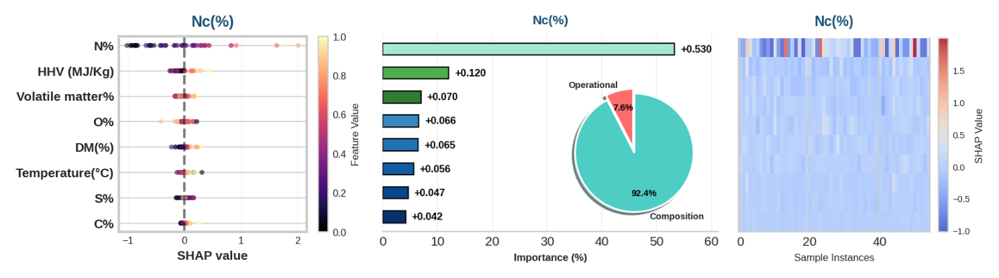

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Nc___.png

📌 Processing 5/13: Sc(%)


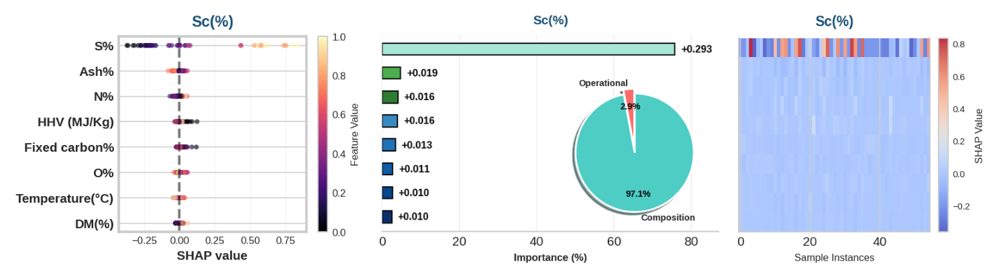

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Sc___.png

📌 Processing 6/13: Oc(%)


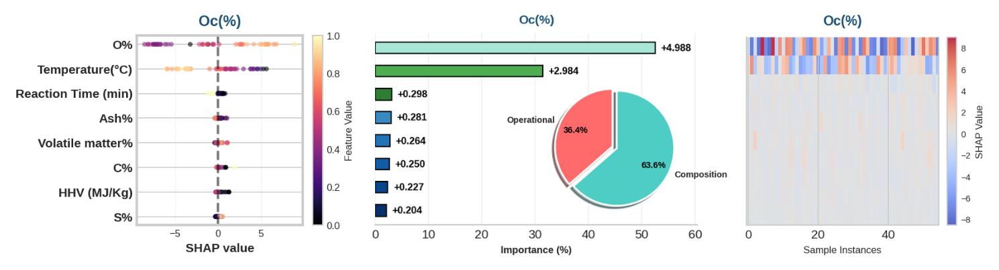

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Oc___.png

📌 Processing 7/13: HHVc (MJ/Kg)


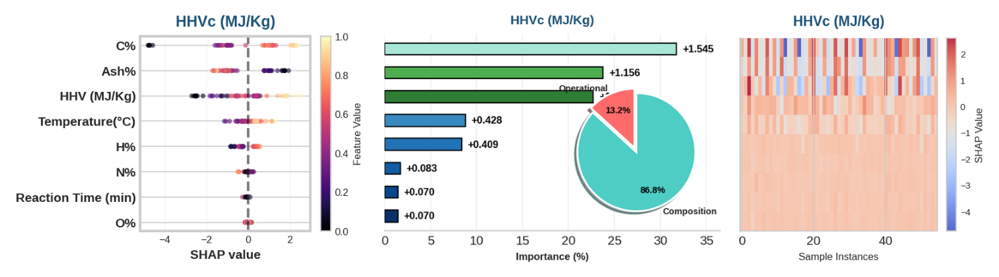

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HHVc__MJ_Kg_.png

📌 Processing 8/13: EY(%)


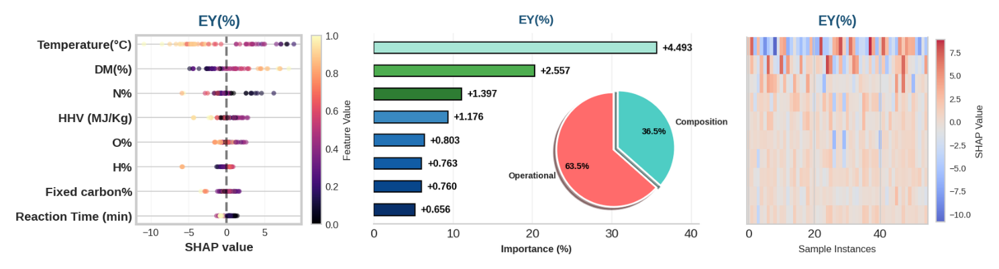

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_EY___.png

📌 Processing 9/13: ED(%)


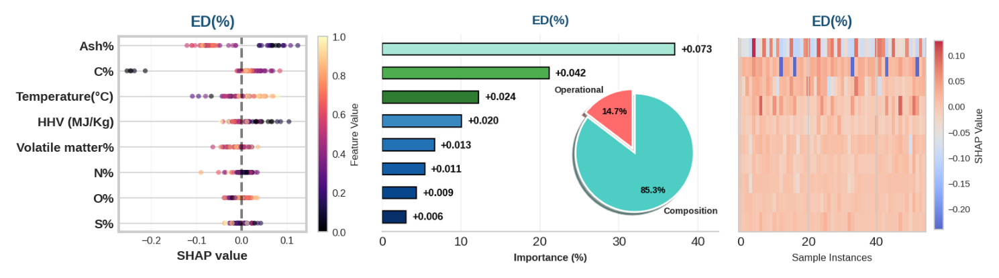

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_ED___.png

📌 Processing 10/13: CR(%)


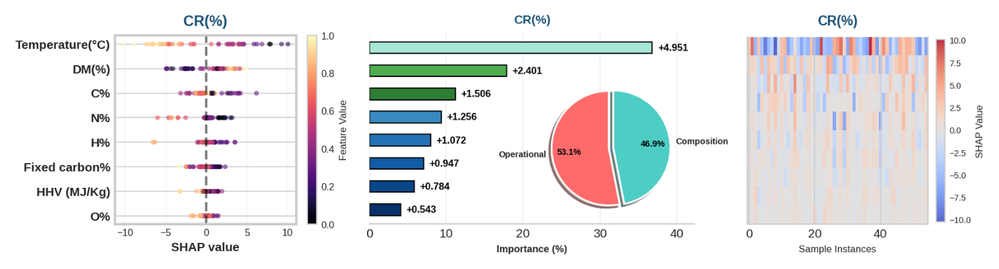

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_CR___.png

📌 Processing 11/13: HC- Volatile matter%


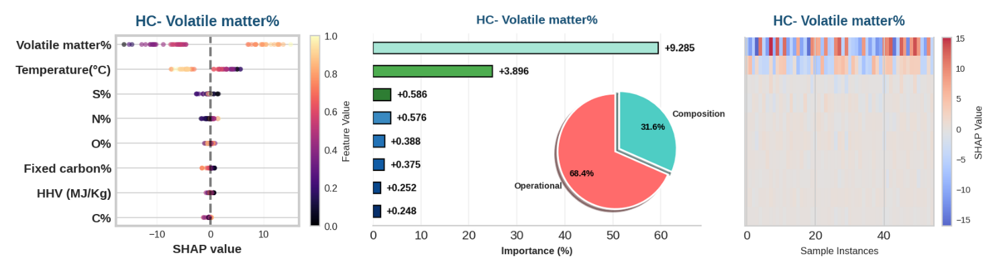

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Volatile_matter_.png

📌 Processing 12/13: HC- Fixed carbon%


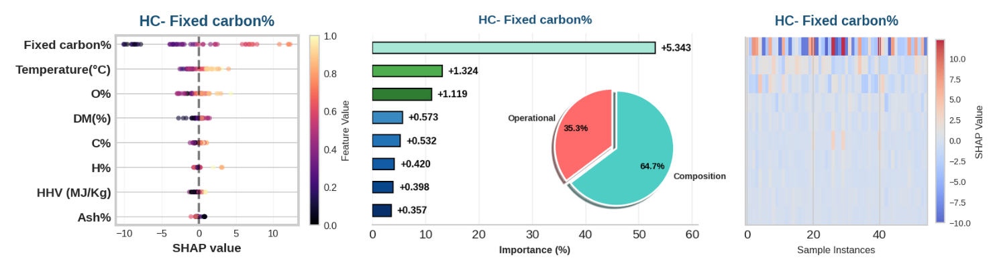

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Fixed_carbon_.png

📌 Processing 13/13: HC- Ash(%)


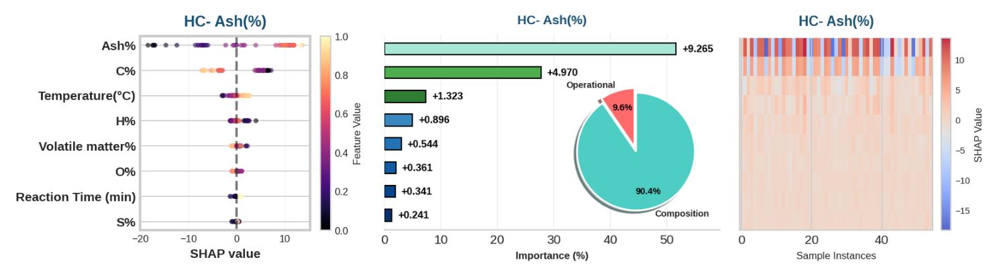

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Ash___.png

✅ ALL COMBINED PLOTS GENERATED SUCCESSFULLY!

📥 Download the combined plots:

📄 yield(%):


/kaggle/working/shap_combined_three/shap_combined_yield___.png


📄 Cc (%):


/kaggle/working/shap_combined_three/shap_combined_Cc____.png


📄 Hc(%):


/kaggle/working/shap_combined_three/shap_combined_Hc___.png

... (17 outputs left out)

/kaggle/working/shap_combined_three/shap_combined_HC-_Fixed_carbon_.png


📄 HC- Ash(%):


/kaggle/working/shap_combined_three/shap_combined_HC-_Ash___.png


📂 All files are stored in: /kaggle/working/shap_combined_three/


In [18]:
# ============================================
# COMBINE THREE PLOTS SIDE BY SIDE (NO CHANGES)
# ============================================

print("\n" + "="*80)
print("🎨 COMBINING THREE PLOTS SIDE BY SIDE FOR EACH OUTPUT")
print("="*80)

import numpy as np
import matplotlib.pyplot as plt
import os
import re
from PIL import Image
import io
import warnings
warnings.filterwarnings('ignore')

# ============================================
# IMPORT THE THREE CODES EXACTLY AS THEY ARE
# ============================================

import shap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Create output folder
output_dir = '/kaggle/working/shap_combined_three'
os.makedirs(output_dir, exist_ok=True)

# ============================================
# FUNCTION 1: BEESWARM (FROM FIRST CODE - EXACT)
# ============================================
def generate_beeswarm_plot(shap_values, col, idx):
    """Generate beeswarm plot exactly as in first code"""
    magma_cmap = plt.cm.get_cmap('magma')
    
    FIGURE_WIDTH = 4
    FIGURE_HEIGHT = 3
    FONT_SIZE = 10
    LINE_WIDTH = 2
    MAX_DISPLAY = 8
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1][:MAX_DISPLAY]
    sorted_idx = sorted_idx[::-1]
    
    fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), dpi=100)
    
    for i, feat_idx in enumerate(sorted_idx):
        shap_vals = shap_values[:, feat_idx]
        jitter = np.random.normal(0, 0.015, len(shap_vals))
        x = shap_vals + jitter
        y = np.ones(len(shap_vals)) * i
        
        feature_vals = X_test_scaled[:, feat_idx]
        norm_vals = (feature_vals - feature_vals.min()) / (feature_vals.max() - feature_vals.min() + 1e-8)
        colors = magma_cmap(norm_vals)
        
        ax.scatter(x, y, c=colors, alpha=0.6, s=15, edgecolors='none')
    
    ax.set_yticks(range(len(sorted_idx)))
    ax.set_yticklabels([input_cols[i] for i in sorted_idx], 
                       fontsize=FONT_SIZE, 
                       fontweight='bold')
    
    ax.spines['left'].set_linewidth(LINE_WIDTH)
    ax.spines['bottom'].set_linewidth(LINE_WIDTH)
    ax.spines['top'].set_linewidth(LINE_WIDTH)
    ax.spines['right'].set_linewidth(LINE_WIDTH)
    
    ax.tick_params(axis='x', labelsize=FONT_SIZE-2, width=LINE_WIDTH)
    ax.tick_params(axis='y', width=LINE_WIDTH)
    
    ax.axvline(x=0, color='black', linestyle='--', alpha=0.5, linewidth=LINE_WIDTH)
    ax.grid(True, alpha=0.2, axis='x', linestyle='-', linewidth=0.5)
    
    ax.set_xlabel('SHAP value', fontsize=FONT_SIZE, fontweight='bold')
    ax.set_title(f'{col}', fontsize=FONT_SIZE+2, fontweight='bold', color='#1A5276', pad=8)
    
    sm = plt.cm.ScalarMappable(cmap=magma_cmap, 
                               norm=plt.Normalize(vmin=0, vmax=1))
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, shrink=1.0)
    cbar.set_label('Feature Value', fontsize=FONT_SIZE-2)
    cbar.ax.tick_params(labelsize=FONT_SIZE-2)
    
    plt.tight_layout(pad=1.0)
    
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# FUNCTION 2: 3D DONUT (التعديلات المطلوبة فقط)
# ============================================
def generate_donut_plot(shap_values, col, idx):
    """Generate 3D donut plot exactly as in second code"""
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1]
    
    top_k = min(8, len(input_cols))
    top_importance = importance[sorted_idx][:top_k]
    top_names = [input_cols[i] for i in sorted_idx[:top_k]]
    
    total_importance = np.sum(top_importance)
    percentages = (top_importance / total_importance) * 100
    
    top_names = top_names[::-1]
    percentages = percentages[::-1]
    top_importance = top_importance[::-1]
    
    fig, ax = plt.subplots(figsize=(4, 3))
    
    colors = plt.cm.Blues(np.linspace(0.4, 1, len(top_names)))[::-1]
    
    if len(colors) >= 3:
        colors[-3] = (0.18, 0.49, 0.20, 1.0)
    if len(colors) >= 2:
        colors[-2] = (0.30, 0.68, 0.31, 1.0)
    if len(colors) >= 1:
        colors[-1] = (0.66, 0.90, 0.84, 1.0)
    
    y_pos = np.arange(len(top_names))
    bars = ax.barh(y_pos, percentages, color=colors, height=0.5, edgecolor='black')
    
    ax.set_yticks([])
    ax.set_yticklabels([])
    ax.set_ylabel('')
    
    max_width = percentages.max()
    
    # ✅ عرض القيم خارج الأعمدة (كما كانت)
    for bar, imp_val in zip(bars, top_importance):
        width = bar.get_width()
        x_pos = width + (max_width * 0.02)
        ax.text(x_pos, bar.get_y() + bar.get_height()/2, 
                f'+{imp_val:.3f}',
                ha='left', va='center', fontsize=8, fontweight='bold', color='black')
    
    ax.set_xlim(0, max_width * 1.15)
    ax.set_xlabel('Importance (%)', fontsize=8, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='x')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    # ✅ تحريك الـ Donut للأسفل ولليمين
    axins = inset_axes(ax, width="75%", height="75%", 
                       loc='center', 
                       bbox_to_anchor=(0.25, -0.10, 1, 1),
                       bbox_transform=ax.transAxes)
    
    group1 = ['Temperature(°C)', 'Reaction Time (min)', 'water Content']
    group2 = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%']
    
    group1_imp = 0
    group2_imp = 0
    for name, imp in zip(top_names, top_importance):
        if name in group1:
            group1_imp += imp
        elif name in group2:
            group2_imp += imp
    
    if group1_imp + group2_imp == 0:
        pie_data = [35.7, 64.3]
    else:
        total = group1_imp + group2_imp
        pie_data = [group1_imp / total * 100, group2_imp / total * 100]
    
    labels = ['Operational', 'Composition']
    pie_colors = ['#FF6B6B', '#4ECDC4']
    
    wedges, texts, autotexts = axins.pie(
        pie_data, 
        labels=labels, 
        colors=pie_colors, 
        autopct='%1.1f%%', 
        startangle=90,
        pctdistance=0.7,
        explode=(0.08, 0),
        shadow=True,
        textprops={'fontsize': 7, 'fontweight': 'bold'},
        wedgeprops={
            'edgecolor': 'white',
            'linewidth': 1.5
        }
    )
    
    for autotext in autotexts:
        autotext.set_color('black')
        autotext.set_fontsize(7)
    
    axins.set_title('', fontsize=8, fontweight='bold', pad=5)
    ax.set_title(f'{col}', fontsize=10, fontweight='bold', pad=8, color='#1A5276')
    
    plt.tight_layout(pad=1.0)
    
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# FUNCTION 3: HEATMAP (FROM THIRD CODE - EXACT)
# ============================================
def generate_heatmap_plot(shap_values, col, idx):
    """Generate heatmap plot exactly as in third code"""
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1][:10]
    shap_subset = shap_values[:, sorted_idx]
    
    fig, ax = plt.subplots(figsize=(3, 3))
    
    im = ax.imshow(shap_subset.T, cmap='coolwarm', aspect='auto', alpha=0.85)
    
    ax.set_yticks([])
    ax.set_yticklabels([])
    ax.set_ylabel('')
    
    ax.spines['top'].set_visible(False)
    
    ax.set_xlabel('Sample Instances', fontsize=8)
    
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('SHAP Value', fontsize=8)
    cbar.ax.tick_params(labelsize=7)
    
    plt.title(f'{col}', fontsize=11, fontweight='bold', pad=10, color='#1A5276')
    
    plt.tight_layout(pad=1.0)
    
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# COMBINE ALL THREE PLOTS FOR EACH OUTPUT
# ============================================
print("\n📊 Combining plots for each output...")

for idx, col in enumerate(output_cols):
    print(f"\n📌 Processing {idx+1}/{len(output_cols)}: {col}")
    
    try:
        shap_values = shap_values_dict[col]
        
        # Generate all three plots
        img1 = generate_beeswarm_plot(shap_values, col, idx)
        img2 = generate_donut_plot(shap_values, col, idx)
        img3 = generate_heatmap_plot(shap_values, col, idx)
        
        # Get dimensions
        w1, h1 = img1.size
        w2, h2 = img2.size
        w3, h3 = img3.size
        
        # Use the maximum height
        target_height = max(h1, h2, h3)
        
        # Resize images to same height (maintain aspect ratio)
        img1_resized = img1.resize((int(w1 * target_height / h1), target_height), Image.Resampling.LANCZOS)
        img2_resized = img2.resize((int(w2 * target_height / h2), target_height), Image.Resampling.LANCZOS)
        img3_resized = img3.resize((int(w3 * target_height / h3), target_height), Image.Resampling.LANCZOS)
        
        # Create combined image
        total_width = img1_resized.width + img2_resized.width + img3_resized.width
        combined = Image.new('RGB', (total_width, target_height), 'white')
        
        # Paste images side by side
        x_offset = 0
        combined.paste(img1_resized, (x_offset, 0))
        x_offset += img1_resized.width
        combined.paste(img2_resized, (x_offset, 0))
        x_offset += img2_resized.width
        combined.paste(img3_resized, (x_offset, 0))
        
        # Save
        safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
        save_path = f'{output_dir}/shap_combined_{safe_filename}.png'
        combined.save(save_path, dpi=(600, 600))
        
        # Display
        plt.figure(figsize=(15, 5))
        plt.imshow(combined)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        
        print(f"   ✅ Saved: {save_path}")
        
    except Exception as e:
        print(f"   ⚠️ Error in {col}: {e}")
        import traceback
        traceback.print_exc()

print("\n" + "="*80)
print("✅ ALL COMBINED PLOTS GENERATED SUCCESSFULLY!")
print("="*80)

# Display download links
from IPython.display import FileLink, display
print("\n📥 Download the combined plots:")
for col in output_cols:
    safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
    file_name = f'shap_combined_{safe_filename}.png'
    file_path = f'{output_dir}/{file_name}'
    if os.path.exists(file_path):
        print(f"\n📄 {col}:")
        display(FileLink(file_path))

print(f"\n📂 All files are stored in: {output_dir}/")

In [19]:
# ============================================
# SHAP IMPORTANCE ANALYSIS - NUMERICAL RESULTS ONLY
# (NO PLOTS, ONLY TABLES AND NUMBERS)
# ============================================

print("\n" + "="*80)
print("📊 SHAP IMPORTANCE ANALYSIS - NUMERICAL RESULTS ONLY")
print("="*80)

import pandas as pd
import numpy as np

# ============================================
# 1. استخراج قيم الأهمية لكل مخرج
# ============================================

print("\n📊 Calculating SHAP importance for each output...")

# قاموس لتخزين النتائج
shap_importance_results = {}

for col in output_cols:
    shap_values = shap_values_dict[col]
    
    # حساب متوسط القيم المطلقة لـ SHAP لكل متغير
    importance = np.abs(shap_values).mean(axis=0)
    
    # حساب متوسط قيم SHAP (مع الإشارة)
    mean_shap = np.mean(shap_values, axis=0)
    
    # ترتيب المتغيرات تنازلياً حسب الأهمية
    sorted_idx = np.argsort(importance)[::-1]
    
    # تخزين النتائج
    shap_importance_results[col] = {
        'features': [input_cols[i] for i in sorted_idx],
        'importance': importance[sorted_idx],
        'mean_shap': mean_shap[sorted_idx],
        'all_importance': importance,
        'all_mean_shap': mean_shap
    }

# ============================================
# 2. عرض أهم 5 متغيرات لكل مخرج
# ============================================

print("\n" + "="*100)
print("📋 TOP 5 FEATURES PER OUTPUT")
print("="*100)

top_n = 5

for col in output_cols:
    features = shap_importance_results[col]['features'][:top_n]
    importance = shap_importance_results[col]['importance'][:top_n]
    mean_shap = shap_importance_results[col]['mean_shap'][:top_n]
    
    print(f"\n📌 {col}:")
    print("-" * 80)
    print(f"{'Rank':<6} {'Feature':<30} {'Importance (|SHAP|)':<20} {'Mean SHAP':<15} {'Direction':<10}")
    print("-" * 80)
    for i, (feat, imp, shap) in enumerate(zip(features, importance, mean_shap), 1):
        direction = "Positive (+)" if shap > 0 else "Negative (-)"
        print(f"{i:<6} {feat:<30} {imp:<20.4f} {shap:<15.4f} {direction:<10}")
    print("-" * 80)

# ============================================
# 3. مصفوفة الأهمية الكاملة (13x13)
# ============================================

print("\n" + "="*100)
print("📊 COMPLETE SHAP IMPORTANCE MATRIX (All Inputs vs All Outputs)")
print("="*100)

# إنشاء DataFrame شامل
all_features = input_cols
importance_matrix = pd.DataFrame(index=all_features)

for col in output_cols:
    # إنشاء قاموس للأهمية
    imp_dict = dict(zip(
        shap_importance_results[col]['features'],
        shap_importance_results[col]['importance']
    ))
    
    # إضافة القيم للـ DataFrame
    importance_matrix[col] = [imp_dict.get(feat, 0) for feat in all_features]

# ترتيب المخرجات حسب المتوسط
importance_matrix['Mean_Importance'] = importance_matrix.mean(axis=1)
importance_matrix = importance_matrix.sort_values('Mean_Importance', ascending=False)

print("\n📋 Complete Matrix (Sorted by Mean Importance):")
print("="*110)
print(importance_matrix.round(4).to_string())
print("="*110)

# ============================================
# 4. المتغيرات الأكثر تأثيراً إجمالاً
# ============================================

print("\n" + "="*100)
print("🏆 GLOBAL FEATURE IMPORTANCE RANKING (Average Across All Outputs)")
print("="*100)

# حساب المتوسط لكل متغير عبر جميع المخرجات
global_importance = {}
for feat in all_features:
    global_importance[feat] = importance_matrix.loc[feat, output_cols].mean()

# ترتيب تنازلي
sorted_global = sorted(global_importance.items(), key=lambda x: x[1], reverse=True)

print(f"\n{'Rank':<6} {'Feature':<35} {'Avg Importance':<20} {'Percentage':<15}")
print("-"*80)
total_importance = sum([imp for _, imp in sorted_global])
for i, (feat, imp) in enumerate(sorted_global, 1):
    percentage = (imp / total_importance) * 100
    print(f"{i:<6} {feat:<35} {imp:<20.4f} {percentage:<15.2f}%")
print("-"*80)

# ============================================
# 5. المخرجات الأكثر تأثراً بكل متغير
# ============================================

print("\n" + "="*100)
print("📌 TOP OUTPUTS AFFECTED BY EACH INPUT FEATURE")
print("="*100)

for feat in all_features:
    # الحصول على تأثير هذا المتغير على كل المخرجات
    impacts = {}
    for col in output_cols:
        imp_dict = dict(zip(
            shap_importance_results[col]['features'],
            shap_importance_results[col]['importance']
        ))
        impacts[col] = imp_dict.get(feat, 0)
    
    # ترتيب المخرجات حسب التأثير
    sorted_impacts = sorted(impacts.items(), key=lambda x: x[1], reverse=True)
    
    print(f"\n🔹 {feat}:")
    print("-" * 60)
    print(f"{'Rank':<6} {'Output':<30} {'Importance':<15}")
    print("-" * 60)
    for i, (out, imp) in enumerate(sorted_impacts[:5], 1):
        print(f"{i:<6} {out:<30} {imp:<15.4f}")
    print("-" * 60)

# ============================================
# 6. اتجاه العلاقة (موجب/سالب) لكل متغير مع كل مخرج
# ============================================

print("\n" + "="*100)
print("🔄 DIRECTION OF RELATIONSHIP (Positive/Negative Impact)")
print("="*100)

# إنشاء DataFrame لاتجاه العلاقة
direction_matrix = pd.DataFrame(index=all_features)

for col in output_cols:
    # إنشاء قاموس لمتوسط SHAP
    mean_dict = dict(zip(
        shap_importance_results[col]['features'],
        shap_importance_results[col]['all_mean_shap']
    ))
    
    # إضافة القيم للـ DataFrame
    direction_matrix[col] = [mean_dict.get(feat, 0) for feat in all_features]

print("\n📋 Direction Matrix (Positive = Increases Output, Negative = Decreases Output):")
print("="*110)
print(direction_matrix.round(4).to_string())
print("="*110)

# ============================================
# 7. ملخص المتغيرات الأكثر تأثيراً لكل مخرج
# ============================================

print("\n" + "="*100)
print("📋 SUMMARY: MOST INFLUENTIAL FEATURE FOR EACH OUTPUT")
print("="*100)

print(f"\n{'Output':<30} {'Most Influential Feature':<35} {'Importance':<15}")
print("-"*80)

for col in output_cols:
    top_feat = shap_importance_results[col]['features'][0]
    top_imp = shap_importance_results[col]['importance'][0]
    print(f"{col:<30} {top_feat:<35} {top_imp:<15.4f}")

print("-"*80)

# ============================================
# 8. تصنيف المتغيرات حسب النوع (تشغيلية/تركيبية)
# ============================================

print("\n" + "="*100)
print("📊 CATEGORIZATION: Operational vs Compositional Features")
print("="*100)

operational = ['Temperature(°C)', 'Reaction Time (min)', 'water Content (%)']
compositional = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 
                 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)']

# حساب الأهمية الإجمالية لكل فئة
op_importance = sum([global_importance.get(f, 0) for f in operational if f in global_importance])
comp_importance = sum([global_importance.get(f, 0) for f in compositional if f in global_importance])

total = op_importance + comp_importance

print(f"\n{'Category':<30} {'Total Importance':<20} {'Percentage':<15}")
print("-"*60)
print(f"{'Operational Parameters':<30} {op_importance:<20.4f} {(op_importance/total)*100:<15.2f}%")
print(f"{'Compositional Parameters':<30} {comp_importance:<20.4f} {(comp_importance/total)*100:<15.2f}%")
print("-"*60)

# تفاصيل المتغيرات التشغيلية
print("\n🔹 Operational Parameters Details:")
print("-"*60)
for feat in operational:
    if feat in global_importance:
        imp = global_importance[feat]
        pct = (imp / total) * 100
        print(f"   {feat:<30} {imp:<15.4f} ({pct:.2f}%)")

# تفاصيل المتغيرات التركيبية
print("\n🔹 Compositional Parameters Details:")
print("-"*60)
for feat in compositional:
    if feat in global_importance:
        imp = global_importance[feat]
        pct = (imp / total) * 100
        print(f"   {feat:<30} {imp:<15.4f} ({pct:.2f}%)")

# ============================================
# 9. حفظ النتائج في Excel
# ============================================

print("\n" + "="*100)
print("💾 SAVING RESULTS TO EXCEL")
print("="*100)

with pd.ExcelWriter('/kaggle/working/shap_importance_results.xlsx') as writer:
    # 1. مصفوفة الأهمية الكاملة
    importance_matrix.to_excel(writer, sheet_name='Complete_Importance_Matrix')
    
    # 2. أهم 5 متغيرات لكل مخرج
    top5_list = []
    for col in output_cols:
        features = shap_importance_results[col]['features'][:5]
        importance = shap_importance_results[col]['importance'][:5]
        mean_shap = shap_importance_results[col]['mean_shap'][:5]
        
        for i, (feat, imp, shap) in enumerate(zip(features, importance, mean_shap), 1):
            top5_list.append({
                'Output': col,
                'Rank': i,
                'Feature': feat,
                'Importance': imp,
                'Mean_SHAP': shap,
                'Direction': 'Positive' if shap > 0 else 'Negative'
            })
    
    top5_df = pd.DataFrame(top5_list)
    top5_df.to_excel(writer, sheet_name='Top5_Per_Output', index=False)
    
    # 3. الترتيب العالمي للمتغيرات
    global_df = pd.DataFrame({
        'Rank': range(1, len(sorted_global)+1),
        'Feature': [f[0] for f in sorted_global],
        'Avg_Importance': [f[1] for f in sorted_global],
        'Percentage': [(f[1]/total_importance)*100 for f in sorted_global]
    })
    global_df.to_excel(writer, sheet_name='Global_Importance', index=False)
    
    # 4. مصفوفة الاتجاه (موجب/سالب)
    direction_matrix.to_excel(writer, sheet_name='Direction_Matrix')
    
    # 5. الملخص: المتغير الأكثر تأثيراً لكل مخرج
    summary_df = pd.DataFrame({
        'Output': output_cols,
        'Most_Influential_Feature': [shap_importance_results[col]['features'][0] for col in output_cols],
        'Importance': [shap_importance_results[col]['importance'][0] for col in output_cols]
    })
    summary_df.to_excel(writer, sheet_name='Summary_Most_Influential', index=False)
    
    # 6. تصنيف المتغيرات
    category_df = pd.DataFrame({
        'Category': ['Operational', 'Compositional'],
        'Total_Importance': [op_importance, comp_importance],
        'Percentage': [(op_importance/total)*100, (comp_importance/total)*100]
    })
    category_df.to_excel(writer, sheet_name='Category_Analysis', index=False)

print("\n✅ Results saved to: shap_importance_results.xlsx")

# ============================================
# 10. الملخص النهائي
# ============================================

print("\n" + "="*100)
print("📊 FINAL SUMMARY - SHAP IMPORTANCE ANALYSIS")
print("="*100)

print(f"""
📌 Analysis Summary:
   • Number of Input Features: {len(input_cols)}
   • Number of Output Targets: {len(output_cols)}
   • Total SHAP Values Calculated: {len(input_cols) * len(output_cols)}

🏆 Top 5 Most Influential Features Overall:
   1. {sorted_global[0][0]}: {sorted_global[0][1]:.4f} ({sorted_global[0][1]/total_importance*100:.2f}%)
   2. {sorted_global[1][0]}: {sorted_global[1][1]:.4f} ({sorted_global[1][1]/total_importance*100:.2f}%)
   3. {sorted_global[2][0]}: {sorted_global[2][1]:.4f} ({sorted_global[2][1]/total_importance*100:.2f}%)
   4. {sorted_global[3][0]}: {sorted_global[3][1]:.4f} ({sorted_global[3][1]/total_importance*100:.2f}%)
   5. {sorted_global[4][0]}: {sorted_global[4][1]:.4f} ({sorted_global[4][1]/total_importance*100:.2f}%)

📊 Category Distribution:
   • Operational Parameters: {op_importance/total*100:.2f}% of total importance
   • Compositional Parameters: {comp_importance/total*100:.2f}% of total importance

📁 Files Generated:
   • shap_importance_results.xlsx (All numerical results)
     - Sheet 1: Complete_Importance_Matrix (13x13)
     - Sheet 2: Top5_Per_Output
     - Sheet 3: Global_Importance
     - Sheet 4: Direction_Matrix
     - Sheet 5: Summary_Most_Influential
     - Sheet 6: Category_Analysis
""")

print("="*100)
print("✅ SHAP Numerical Analysis Complete!")
print("="*100)


📊 SHAP IMPORTANCE ANALYSIS - NUMERICAL RESULTS ONLY

📊 Calculating SHAP importance for each output...

📋 TOP 5 FEATURES PER OUTPUT

📌 yield(%):
--------------------------------------------------------------------------------
Rank   Feature                        Importance (|SHAP|)  Mean SHAP       Direction 
--------------------------------------------------------------------------------
1      Temperature(°C)                5.3197               -0.9609         Negative (-)
2      H%                             1.8758               0.3022          Positive (+)
3      DM(%)                          1.7496               0.2391          Positive (+)
4      Fixed carbon%                  1.5794               0.3223          Positive (+)
5      C%                             1.4285               0.2811          Positive (+)
--------------------------------------------------------------------------------

📌 Cc (%):
---------------------------------------------------------------------------


🎨 COMBINING THREE PLOTS SIDE BY SIDE FOR EACH OUTPUT

📊 Combining plots for each output...

📌 Processing 1/13: yield(%)


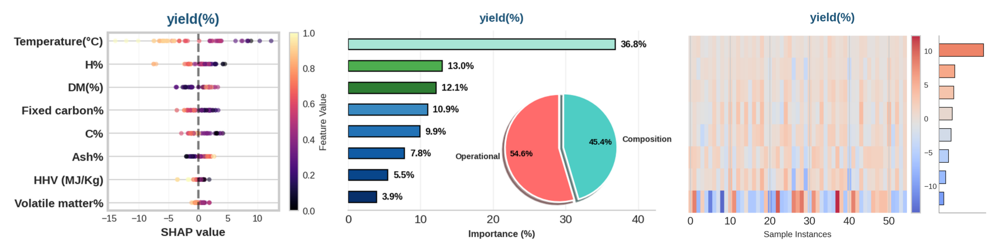

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_yield___.png

📌 Processing 2/13: Cc (%)


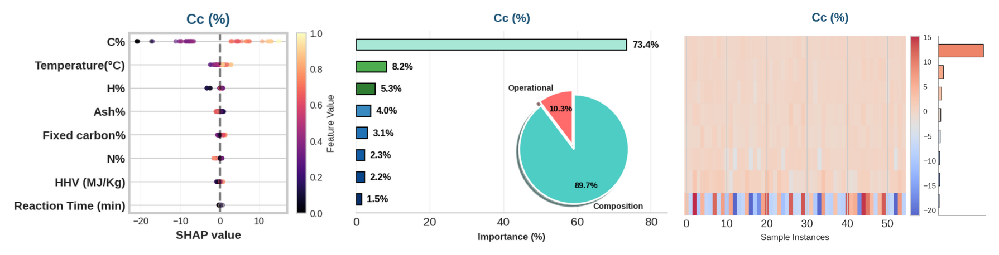

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Cc____.png

📌 Processing 3/13: Hc(%)


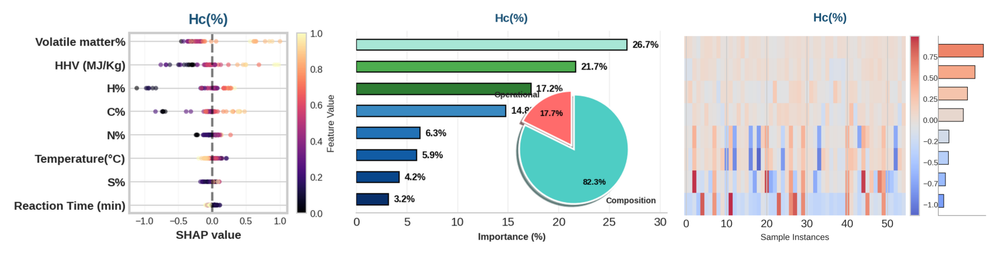

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Hc___.png

📌 Processing 4/13: Nc(%)


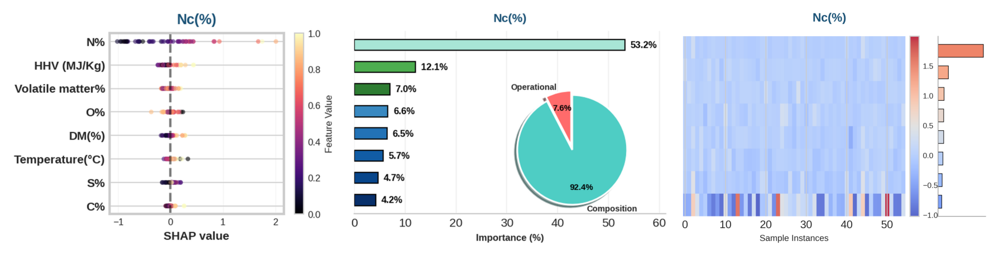

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Nc___.png

📌 Processing 5/13: Sc(%)


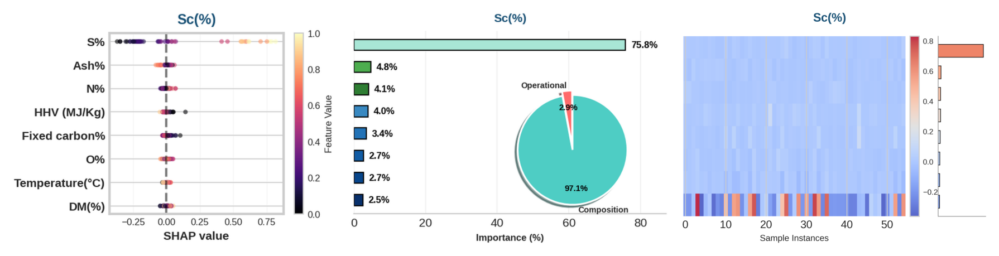

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Sc___.png

📌 Processing 6/13: Oc(%)


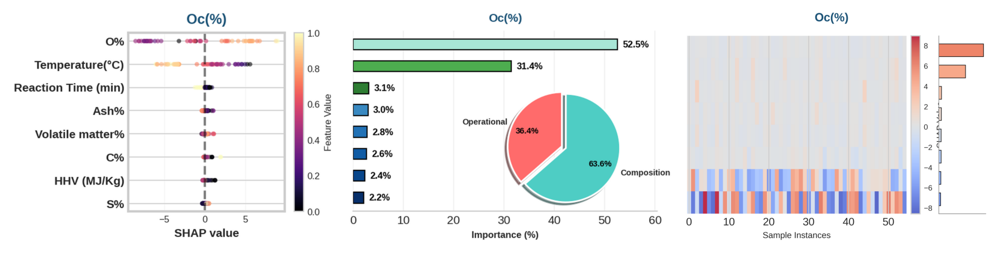

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Oc___.png

📌 Processing 7/13: HHVc (MJ/Kg)


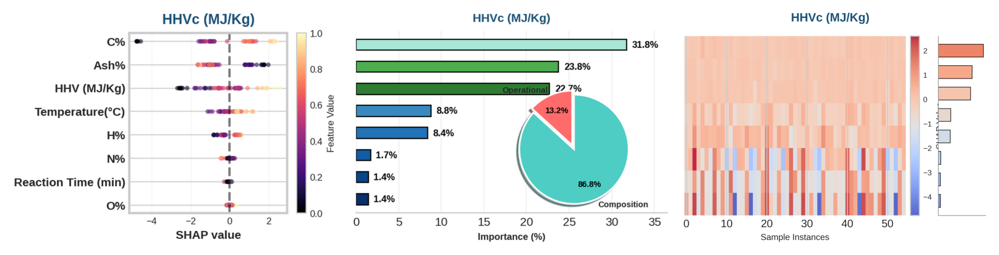

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HHVc__MJ_Kg_.png

📌 Processing 8/13: EY(%)


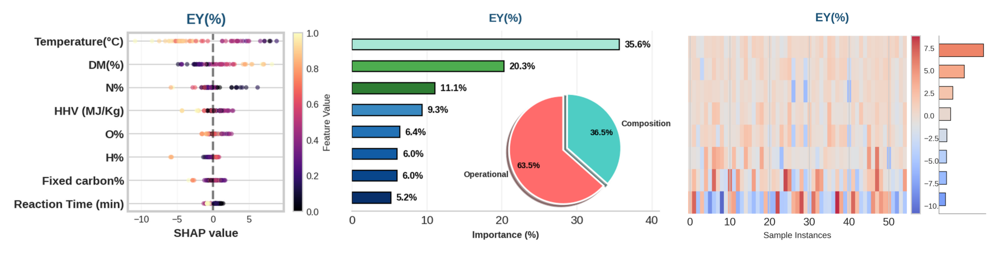

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_EY___.png

📌 Processing 9/13: ED(%)


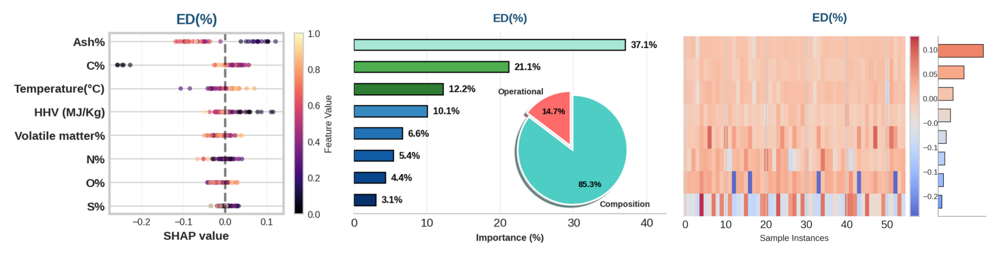

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_ED___.png

📌 Processing 10/13: CR(%)


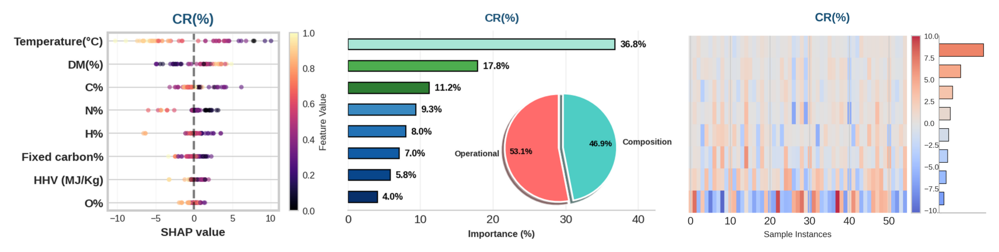

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_CR___.png

📌 Processing 11/13: HC- Volatile matter%


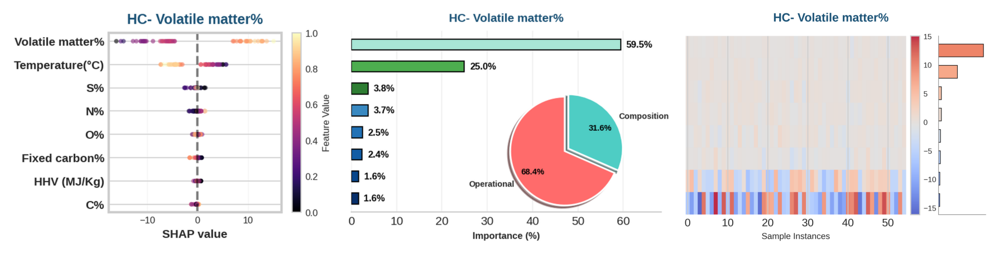

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Volatile_matter_.png

📌 Processing 12/13: HC- Fixed carbon%


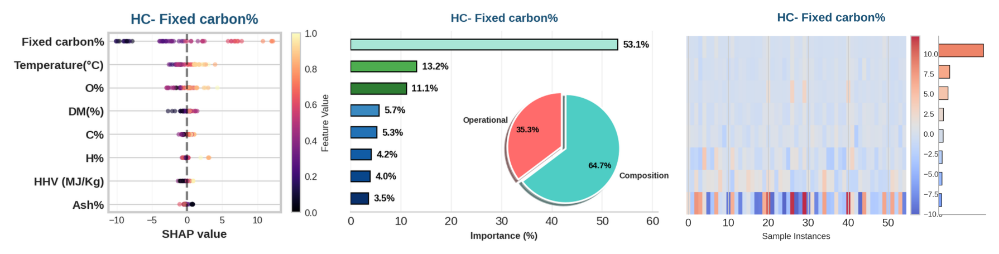

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Fixed_carbon_.png

📌 Processing 13/13: HC- Ash(%)


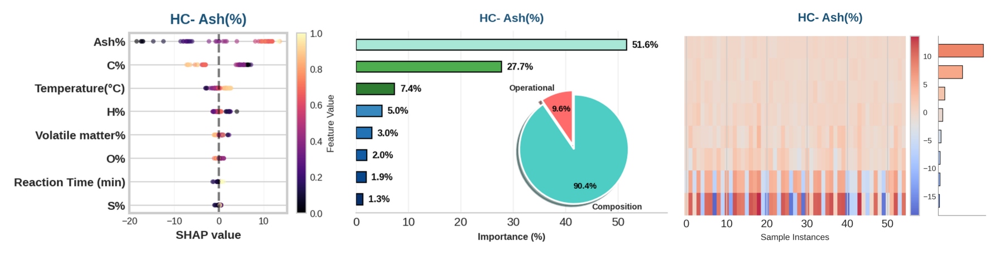

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Ash___.png

✅ ALL COMBINED PLOTS GENERATED SUCCESSFULLY!

📥 Download the combined plots:

📄 yield(%):


/kaggle/working/shap_combined_three/shap_combined_yield___.png


📄 Cc (%):


/kaggle/working/shap_combined_three/shap_combined_Cc____.png


📄 Hc(%):


/kaggle/working/shap_combined_three/shap_combined_Hc___.png

... (17 outputs left out)

/kaggle/working/shap_combined_three/shap_combined_HC-_Fixed_carbon_.png


📄 HC- Ash(%):


/kaggle/working/shap_combined_three/shap_combined_HC-_Ash___.png


📂 All files are stored in: /kaggle/working/shap_combined_three/


In [20]:
# ============================================
# COMBINE THREE PLOTS SIDE BY SIDE (WITH IMPORTANCE BAR)
# ============================================

print("\n" + "="*80)
print("🎨 COMBINING THREE PLOTS SIDE BY SIDE FOR EACH OUTPUT")
print("="*80)

import numpy as np
import matplotlib.pyplot as plt
import os
import re
from PIL import Image
import io
import warnings
warnings.filterwarnings('ignore')

# ============================================
# IMPORT THE THREE CODES EXACTLY AS THEY ARE
# ============================================

import shap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Create output folder
output_dir = '/kaggle/working/shap_combined_three'
os.makedirs(output_dir, exist_ok=True)

# ============================================
# FUNCTION 1: BEESWARM (FROM FIRST CODE - EXACT)
# ============================================
def generate_beeswarm_plot(shap_values, col, idx):
    """Generate beeswarm plot exactly as in first code"""
    magma_cmap = plt.cm.get_cmap('magma')
    
    FIGURE_WIDTH = 4
    FIGURE_HEIGHT = 3
    FONT_SIZE = 10
    LINE_WIDTH = 2
    MAX_DISPLAY = 8
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1][:MAX_DISPLAY]
    sorted_idx = sorted_idx[::-1]
    
    fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), dpi=100)
    
    for i, feat_idx in enumerate(sorted_idx):
        shap_vals = shap_values[:, feat_idx]
        jitter = np.random.normal(0, 0.015, len(shap_vals))
        x = shap_vals + jitter
        y = np.ones(len(shap_vals)) * i
        
        feature_vals = X_test_scaled[:, feat_idx]
        norm_vals = (feature_vals - feature_vals.min()) / (feature_vals.max() - feature_vals.min() + 1e-8)
        colors = magma_cmap(norm_vals)
        
        ax.scatter(x, y, c=colors, alpha=0.6, s=15, edgecolors='none')
    
    ax.set_yticks(range(len(sorted_idx)))
    ax.set_yticklabels([input_cols[i] for i in sorted_idx], 
                       fontsize=FONT_SIZE, 
                       fontweight='bold')
    
    ax.spines['left'].set_linewidth(LINE_WIDTH)
    ax.spines['bottom'].set_linewidth(LINE_WIDTH)
    ax.spines['top'].set_linewidth(LINE_WIDTH)
    ax.spines['right'].set_linewidth(LINE_WIDTH)
    
    ax.tick_params(axis='x', labelsize=FONT_SIZE-2, width=LINE_WIDTH)
    ax.tick_params(axis='y', width=LINE_WIDTH)
    
    ax.axvline(x=0, color='black', linestyle='--', alpha=0.5, linewidth=LINE_WIDTH)
    ax.grid(True, alpha=0.2, axis='x', linestyle='-', linewidth=0.5)
    
    ax.set_xlabel('SHAP value', fontsize=FONT_SIZE, fontweight='bold')
    ax.set_title(f'{col}', fontsize=FONT_SIZE+2, fontweight='bold', color='#1A5276', pad=8)
    
    sm = plt.cm.ScalarMappable(cmap=magma_cmap, 
                               norm=plt.Normalize(vmin=0, vmax=1))
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, shrink=1.0)
    cbar.set_label('Feature Value', fontsize=FONT_SIZE-2)
    cbar.ax.tick_params(labelsize=FONT_SIZE-2)
    
    plt.tight_layout(pad=1.0)
    
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# FUNCTION 2: 3D DONUT (FROM SECOND CODE - EXACT)
# ============================================
def generate_donut_plot(shap_values, col, idx):
    """Generate 3D donut plot exactly as in second code"""
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1]
    
    top_k = min(8, len(input_cols))
    top_importance = importance[sorted_idx][:top_k]
    top_names = [input_cols[i] for i in sorted_idx[:top_k]]
    
    total_importance = np.sum(top_importance)
    percentages = (top_importance / total_importance) * 100
    
    top_names = top_names[::-1]
    percentages = percentages[::-1]
    top_importance = top_importance[::-1]
    
    fig, ax = plt.subplots(figsize=(4, 3))
    
    colors = plt.cm.Blues(np.linspace(0.4, 1, len(top_names)))[::-1]
    
    if len(colors) >= 3:
        colors[-3] = (0.18, 0.49, 0.20, 1.0)
    if len(colors) >= 2:
        colors[-2] = (0.30, 0.68, 0.31, 1.0)
    if len(colors) >= 1:
        colors[-1] = (0.66, 0.90, 0.84, 1.0)
    
    y_pos = np.arange(len(top_names))
    bars = ax.barh(y_pos, percentages, color=colors, height=0.5, edgecolor='black')
    
    ax.set_yticks([])
    ax.set_yticklabels([])
    ax.set_ylabel('')
    
    max_width = percentages.max()
    for bar, pct in zip(bars, percentages):
        width = bar.get_width()
        x_pos = width + (max_width * 0.02)
        ax.text(x_pos, bar.get_y() + bar.get_height()/2, 
                f'{pct:.1f}%', 
                ha='left', va='center', fontsize=8, fontweight='bold', color='black')
    
    ax.set_xlim(0, max_width * 1.15)
    ax.set_xlabel('Importance (%)', fontsize=8, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='x')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    axins = inset_axes(ax, width="75%", height="75%", 
                       loc='center', 
                       bbox_to_anchor=(0.20, -0.15, 1, 1), 
                       bbox_transform=ax.transAxes)
    
    group1 = ['Temperature(°C)', 'Reaction Time (min)', 'water Content']
    group2 = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%']
    
    group1_imp = 0
    group2_imp = 0
    for name, imp in zip(top_names, top_importance):
        if name in group1:
            group1_imp += imp
        elif name in group2:
            group2_imp += imp
    
    if group1_imp + group2_imp == 0:
        pie_data = [35.7, 64.3]
    else:
        total = group1_imp + group2_imp
        pie_data = [group1_imp / total * 100, group2_imp / total * 100]
    
    labels = ['Operational', 'Composition']
    pie_colors = ['#FF6B6B', '#4ECDC4']
    
    wedges, texts, autotexts = axins.pie(
        pie_data, 
        labels=labels, 
        colors=pie_colors, 
        autopct='%1.1f%%', 
        startangle=90,
        pctdistance=0.7,
        explode=(0.08, 0),
        shadow=True,
        textprops={'fontsize': 7, 'fontweight': 'bold'},
        wedgeprops={
            'edgecolor': 'white',
            'linewidth': 1.5
        }
    )
    
    for autotext in autotexts:
        autotext.set_color('black')
        autotext.set_fontsize(7)
    
    axins.set_title('', fontsize=8, fontweight='bold', pad=5)
    ax.set_title(f'{col}', fontsize=10, fontweight='bold', pad=8, color='#1A5276')
    
    plt.tight_layout(pad=1.0)
    
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# FUNCTION 3: HEATMAP WITH IMPORTANCE BAR (UPDATED)
# ============================================
def generate_heatmap_plot(shap_values, col, idx):
    """Generate heatmap plot with importance bar - Top 8, Most important at TOP"""
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1][:8]  # أهم 8 ميزات فقط
    
    # عكس الترتيب بحيث يكون الأكثر أهمية في الأعلى
    sorted_idx = sorted_idx[::-1]  # الأكثر أهمية في الأعلى
    
    shap_subset = shap_values[:, sorted_idx]
    
    # إنشاء شكل مقسم إلى جزئين: Heatmap + Bar Chart
    fig = plt.figure(figsize=(5, 3))
    
    # تقسيم الشكل إلى جزئين
    gs = fig.add_gridspec(1, 2, width_ratios=[4, 0.8], wspace=0.12)
    
    # الجزء الأيسر: Heatmap
    ax1 = fig.add_subplot(gs[0])
    im = ax1.imshow(shap_subset.T, cmap='coolwarm', aspect='auto', alpha=0.85)
    
    # إزالة جميع تسميات المحور الرأسي
    ax1.set_yticks([])
    ax1.set_yticklabels([])
    ax1.set_ylabel('')
    
    # إزالة جميع الحدود
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.spines['left'].set_visible(False)
    ax1.spines['bottom'].set_visible(False)
    
    ax1.set_xlabel('Sample Instances', fontsize=8)
    
    # Colorbar للـ Heatmap
    cbar = plt.colorbar(im, ax=ax1, fraction=0.046, pad=0.02)
    cbar.set_label('SHAP Value', fontsize=8)
    cbar.ax.tick_params(labelsize=7)
    
    # الجزء الأيمن: Bar Chart أفقي (بدون أسماء أو أرقام)
    ax2 = fig.add_subplot(gs[1])
    
    # الحصول على أسماء الميزات وأهميتها (بنفس ترتيب الـ Heatmap)
    feature_names = [input_cols[i] for i in sorted_idx]
    feature_importance = importance[sorted_idx]
    
    # تطبيع الأهمية إلى 0-1 للعرض
    norm_importance = feature_importance / feature_importance.max()
    
    # رسم Bar Chart أفقي
    y_pos = np.arange(len(feature_names))
    bars = ax2.barh(y_pos, norm_importance, 
                    color=plt.cm.coolwarm(np.linspace(0.2, 0.8, len(feature_names))), 
                    height=0.6, edgecolor='black', linewidth=0.5)
    
    # إزالة جميع الأرقام من على الأشرطة
    # تم حذف حلقة for التي كانت تضيف الأرقام
    
    # إزالة جميع تسميات المحاور
    ax2.set_yticks([])
    ax2.set_yticklabels([])
    ax2.set_ylabel('')
    ax2.set_xticks([])
    ax2.set_xticklabels([])
    ax2.set_xlabel('')
    
    # إزالة جميع الخطوط
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.spines['bottom'].set_visible(False)
    ax2.spines['left'].set_visible(False)
    
    # إزالة الشبكة
    ax2.grid(False)
    
    # إضافة حدود خفيفة حول الـ Bar Chart فقط
    ax2.spines['left'].set_visible(True)
    ax2.spines['left'].set_color('gray')
    ax2.spines['left'].set_linewidth(0.5)
    ax2.spines['bottom'].set_visible(True)
    ax2.spines['bottom'].set_color('gray')
    ax2.spines['bottom'].set_linewidth(0.5)
    
    # عنوان رئيسي (صغير)
    plt.suptitle(f'{col}', fontsize=11, fontweight='bold', color='#1A5276', y=0.98)
    
    plt.tight_layout(pad=0.5)
    
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=600, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# COMBINE ALL THREE PLOTS FOR EACH OUTPUT
# ============================================
print("\n📊 Combining plots for each output...")

for idx, col in enumerate(output_cols):
    print(f"\n📌 Processing {idx+1}/{len(output_cols)}: {col}")
    
    try:
        shap_values = shap_values_dict[col]
        
        # Generate all three plots
        img1 = generate_beeswarm_plot(shap_values, col, idx)
        img2 = generate_donut_plot(shap_values, col, idx)
        img3 = generate_heatmap_plot(shap_values, col, idx)
        
        # Get dimensions
        w1, h1 = img1.size
        w2, h2 = img2.size
        w3, h3 = img3.size
        
        # Use the maximum height
        target_height = max(h1, h2, h3)
        
        # Resize images to same height (maintain aspect ratio)
        img1_resized = img1.resize((int(w1 * target_height / h1), target_height), Image.Resampling.LANCZOS)
        img2_resized = img2.resize((int(w2 * target_height / h2), target_height), Image.Resampling.LANCZOS)
        img3_resized = img3.resize((int(w3 * target_height / h3), target_height), Image.Resampling.LANCZOS)
        
        # Create combined image
        total_width = img1_resized.width + img2_resized.width + img3_resized.width
        combined = Image.new('RGB', (total_width, target_height), 'white')
        
        # Paste images side by side
        x_offset = 0
        combined.paste(img1_resized, (x_offset, 0))
        x_offset += img1_resized.width
        combined.paste(img2_resized, (x_offset, 0))
        x_offset += img2_resized.width
        combined.paste(img3_resized, (x_offset, 0))
        
        # Save
        safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
        save_path = f'{output_dir}/shap_combined_{safe_filename}.png'
        combined.save(save_path, dpi=(600, 600))
        
        # Display
        plt.figure(figsize=(18, 5))
        plt.imshow(combined)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        
        print(f"   ✅ Saved: {save_path}")
        
    except Exception as e:
        print(f"   ⚠️ Error in {col}: {e}")
        import traceback
        traceback.print_exc()

print("\n" + "="*80)
print("✅ ALL COMBINED PLOTS GENERATED SUCCESSFULLY!")
print("="*80)

# Display download links
from IPython.display import FileLink, display
print("\n📥 Download the combined plots:")
for col in output_cols:
    safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
    file_name = f'shap_combined_{safe_filename}.png'
    file_path = f'{output_dir}/{file_name}'
    if os.path.exists(file_path):
        print(f"\n📄 {col}:")
        display(FileLink(file_path))

print(f"\n📂 All files are stored in: {output_dir}/")


🎨 GENERATING SHAP HEATMAP (Instances Heatmap - Final Fix)

📌 Processing 1/13: yield(%)


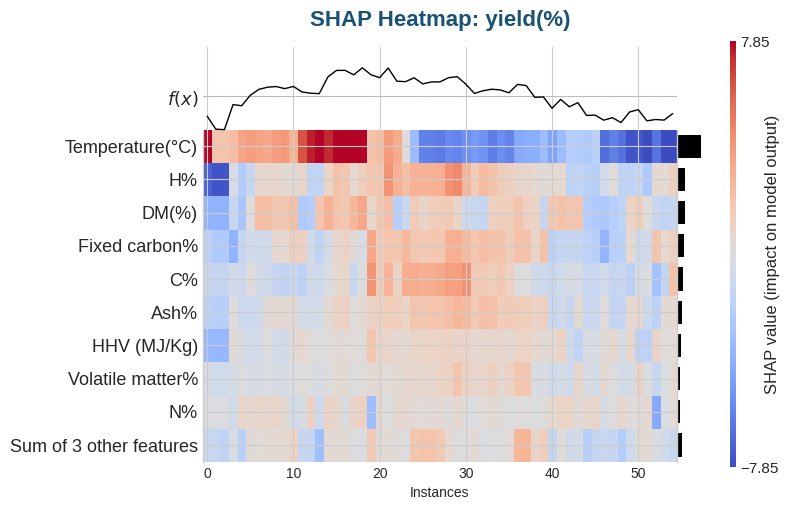

   ✅ Saved: /kaggle/working/shap_heatmaps/shap_heatmap_yield___.png

📌 Processing 2/13: Cc (%)


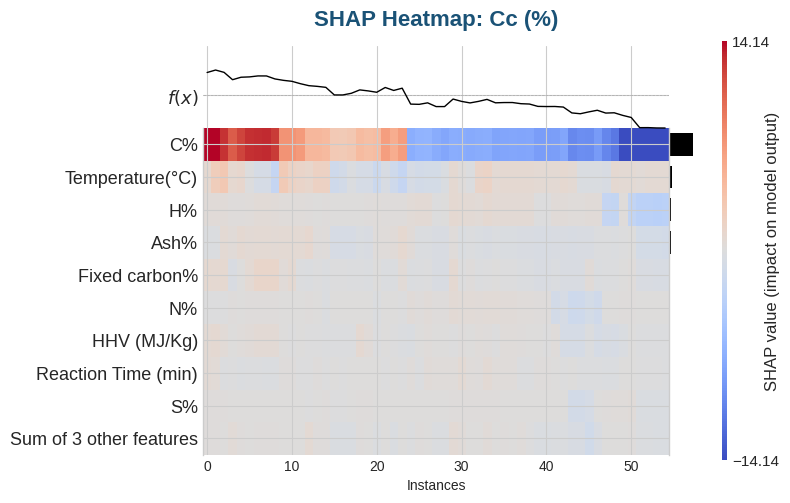

   ✅ Saved: /kaggle/working/shap_heatmaps/shap_heatmap_Cc____.png

📌 Processing 3/13: Hc(%)


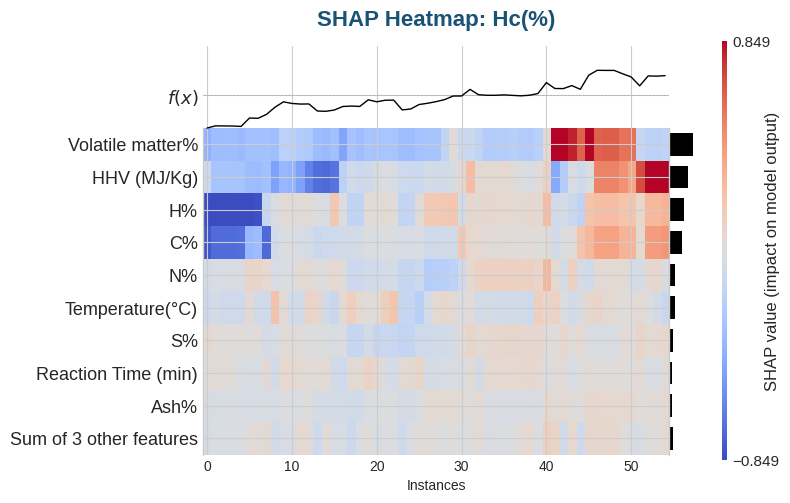

   ✅ Saved: /kaggle/working/shap_heatmaps/shap_heatmap_Hc___.png

📌 Processing 4/13: Nc(%)


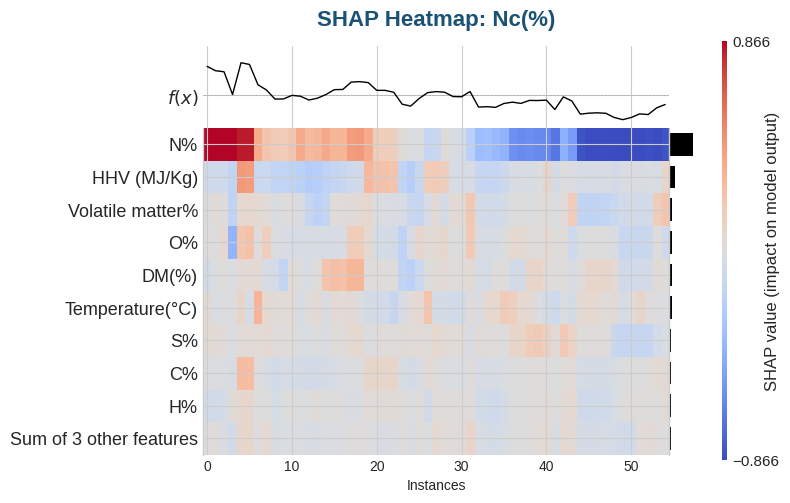

   ✅ Saved: /kaggle/working/shap_heatmaps/shap_heatmap_Nc___.png

📌 Processing 5/13: Sc(%)


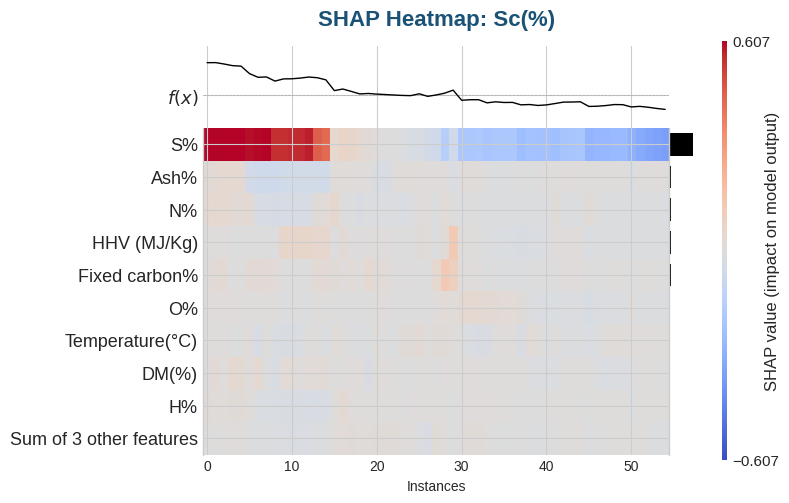

   ✅ Saved: /kaggle/working/shap_heatmaps/shap_heatmap_Sc___.png

📌 Processing 6/13: Oc(%)


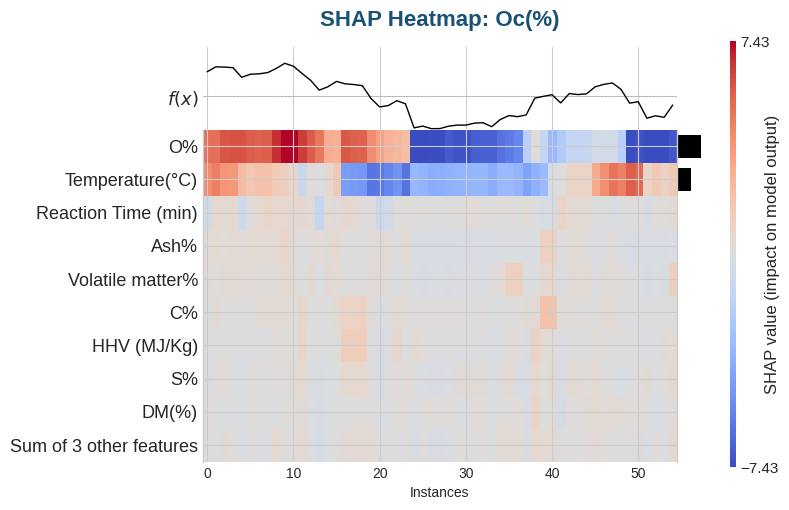

   ✅ Saved: /kaggle/working/shap_heatmaps/shap_heatmap_Oc___.png

📌 Processing 7/13: HHVc (MJ/Kg)


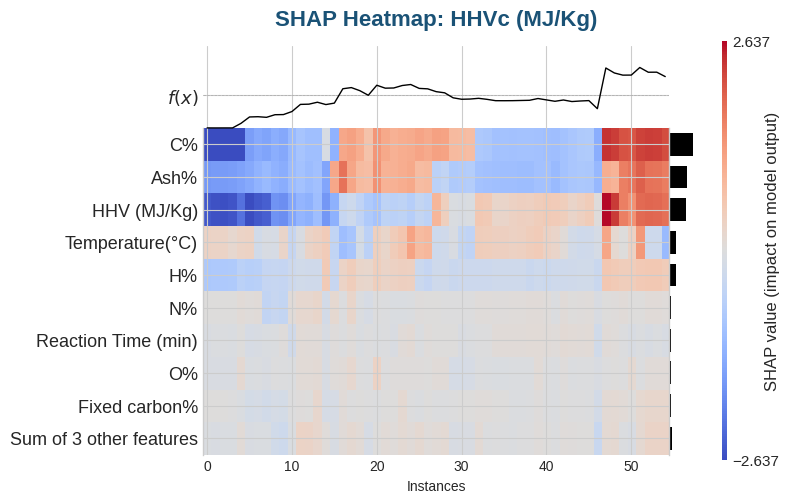

   ✅ Saved: /kaggle/working/shap_heatmaps/shap_heatmap_HHVc__MJ_Kg_.png

📌 Processing 8/13: EY(%)


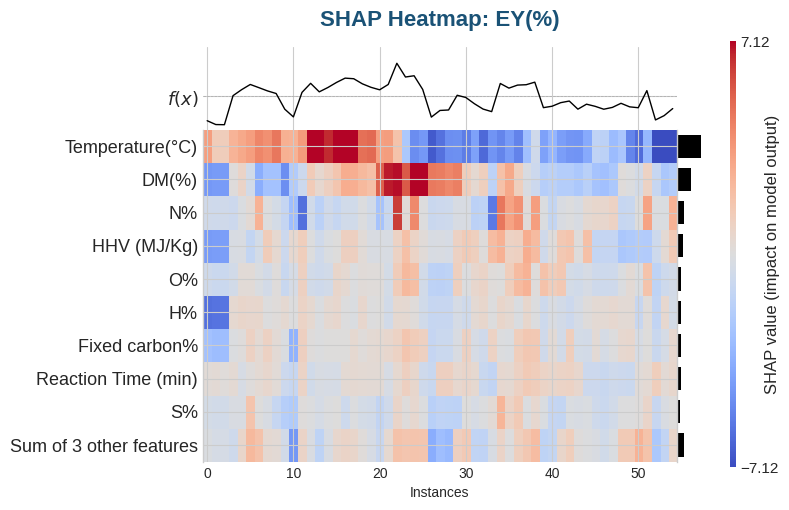

   ✅ Saved: /kaggle/working/shap_heatmaps/shap_heatmap_EY___.png

📌 Processing 9/13: ED(%)


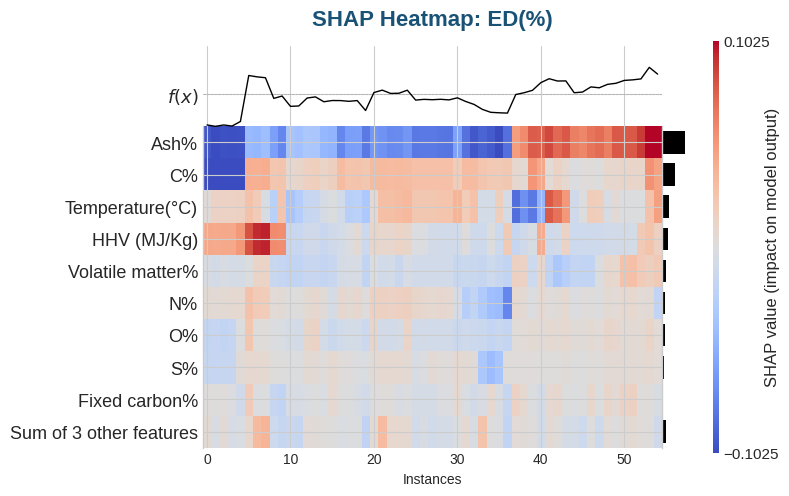

   ✅ Saved: /kaggle/working/shap_heatmaps/shap_heatmap_ED___.png

📌 Processing 10/13: CR(%)


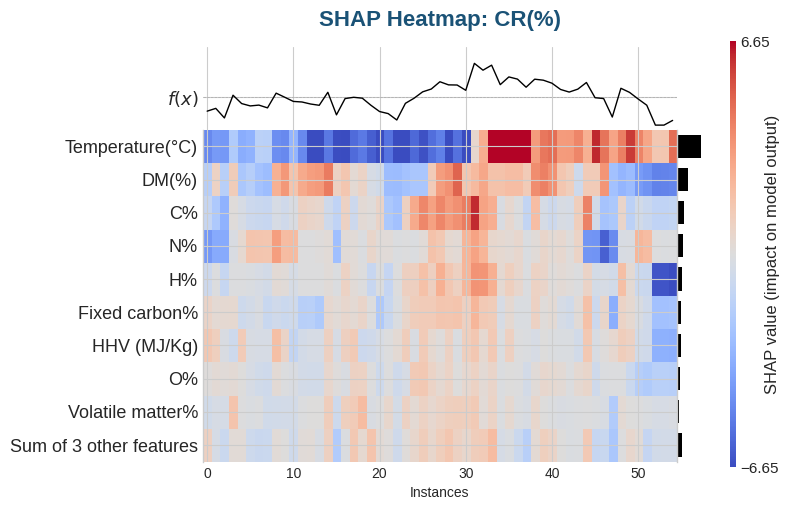

   ✅ Saved: /kaggle/working/shap_heatmaps/shap_heatmap_CR___.png

📌 Processing 11/13: HC- Volatile matter%


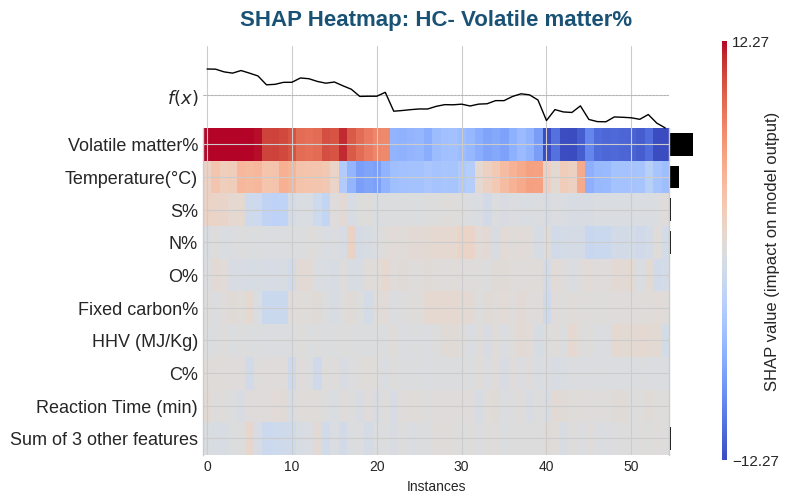

   ✅ Saved: /kaggle/working/shap_heatmaps/shap_heatmap_HC-_Volatile_matter_.png

📌 Processing 12/13: HC- Fixed carbon%


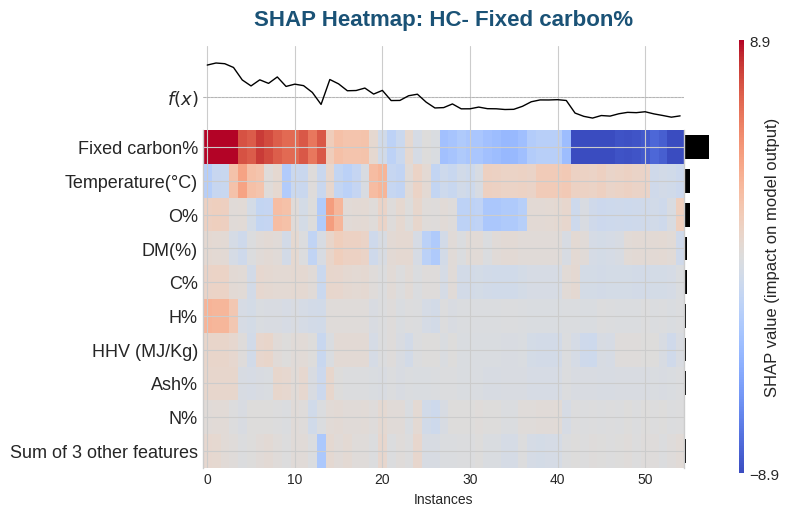

   ✅ Saved: /kaggle/working/shap_heatmaps/shap_heatmap_HC-_Fixed_carbon_.png

📌 Processing 13/13: HC- Ash(%)


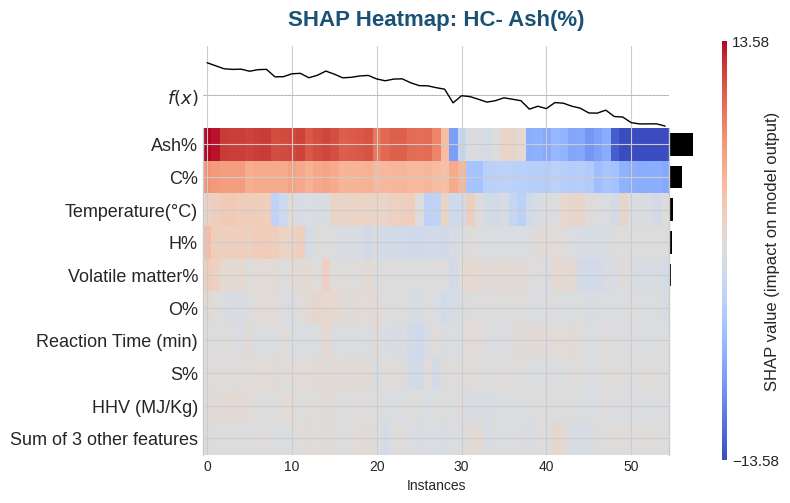

   ✅ Saved: /kaggle/working/shap_heatmaps/shap_heatmap_HC-_Ash___.png

✅ ALL SHAP HEATMAP PLOTS GENERATED SUCCESSFULLY!

📥 Download the 600 DPI heatmaps:

📄 yield(%):


/kaggle/working/shap_heatmaps/shap_heatmap_yield___.png


📄 Cc (%):


/kaggle/working/shap_heatmaps/shap_heatmap_Cc____.png


📄 Hc(%):


/kaggle/working/shap_heatmaps/shap_heatmap_Hc___.png

... (17 outputs left out)

/kaggle/working/shap_heatmaps/shap_heatmap_HC-_Fixed_carbon_.png


📄 HC- Ash(%):


/kaggle/working/shap_heatmaps/shap_heatmap_HC-_Ash___.png


📂 All files are stored in: /kaggle/working/shap_heatmaps/


In [21]:
# ============================================
# SHAP HEATMAP (Fixed - Using Explanation Object)
# ============================================

print("\n" + "="*80)
print("🎨 GENERATING SHAP HEATMAP (Instances Heatmap - Final Fix)")
print("="*80)

import shap
import numpy as np
import matplotlib.pyplot as plt
import os
import re

# Create output folder
output_dir = '/kaggle/working/shap_heatmaps'
os.makedirs(output_dir, exist_ok=True)

# Loop through all outputs
for idx, col in enumerate(output_cols):
    print(f"\n📌 Processing {idx+1}/{len(output_cols)}: {col}")
    
    try:
        shap_values = shap_values_dict[col]
        
        # 🛠️ FIX: Create a SHAP Explanation object
        # This is required for the heatmap function in older shap versions
        explanation = shap.Explanation(
            values=shap_values,
            base_values=np.mean(shap_values, axis=0),
            data=X_test_scaled,
            feature_names=input_cols
        )
        
        # Create a clean figure for each output
        fig, ax = plt.subplots(figsize=(12, 8))
        
        # Draw the SHAP Heatmap using the Explanation object
        shap.plots.heatmap(
            explanation,
            show=False,
            max_display=10,
            cmap="coolwarm"
        )
        
        # Set Title
        plt.title(f'SHAP Heatmap: {col}', fontsize=16, fontweight='bold', pad=15, color='#1A5276')
        
        # Adjust layout
        plt.tight_layout()
        
        # Save at 600 DPI
        safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
        save_path = f'{output_dir}/shap_heatmap_{safe_filename}.png'
        plt.savefig(save_path, dpi=600, bbox_inches='tight', facecolor='white')
        
        # Show the plot
        plt.show()
        plt.close()
        
        print(f"   ✅ Saved: {save_path}")
        
    except Exception as e:
        print(f"   ⚠️ Error in {col}: {e}")

print("\n" + "="*80)
print("✅ ALL SHAP HEATMAP PLOTS GENERATED SUCCESSFULLY!")
print("="*80)

# Display Download Links
from IPython.display import FileLink, display
print("\n📥 Download the 600 DPI heatmaps:")
for col in output_cols:
    safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
    file_name = f'shap_heatmap_{safe_filename}.png'
    file_path = f'{output_dir}/{file_name}'
    if os.path.exists(file_path):
        print(f"\n📄 {col}:")
        display(FileLink(file_path))

print("\n📂 All files are stored in: /kaggle/working/shap_heatmaps/")